# Ne model v6b: v6a schedule + flux constraint
**Part A**: data, split by whole years, ANN training over every training-year row, metrics. **Part B**: figures of Gowtam et al. 2019.
Same data, inputs, network and split as v6/v6a: 19 inputs (no drift, no dip latitude), GIRO and COSMIC-1 in full, 30% of COSMIC-2 profiles. Changes, each aimed at a fault seen in v6:
- **Training length (v6a schedule)**: 3 epochs; no checkpoint can be chosen before epoch 1.0; the smoothness penalty is ramped in over the first epoch. v6 kept the weights from 0.1 epoch, which gave one smooth equatorial maximum instead of two crests.
- **NmF2 must not fall as F10.7 rises**: a penalty on any drop in output when F10.7 and F10.7(81) are raised together by 20 sfu, at random flux values between 65 and 230 sfu (`NE_MONO_LAM`). v6 NmF2 peaked near 160 sfu and then fell.
- **Rare high-flux rows count more**: loss weight ∝ (share of rows in the 20-sfu F10.7 bin)^-0.5 (`NE_F107_BAL`). Most high-flux years are held out (2002, 2014, 2024), so few training rows exist above 170 sfu.
- **Optional, off by default**: `NE_DIPOLE_LAT = '1'` adds a centred-dipole magnetic latitude, computed only from geographic latitude and longitude (no data input). Use it only if the crests are still missing after this run and dip-latitude-like inputs are allowed.
- A quick check after training (F10.7 response at Jicamarca and Grahamstown, latitude cut at 75°E) shows both faults before the long figure cells run.

In [1]:
import os
os.environ['NE_DATA_DIR'] = '/media/dell/Volume_D/ne_work/selected_parameters'
os.environ['NE_PQ'] = '/media/dell/Volume_D/ne_work/v6_pq'
os.environ['NE_COSMIC_PQ'] = os.environ['NE_PQ']
os.environ['NE_YEAR_MIN'] = '1993'
os.environ['NE_YEAR_MAX'] = '2024'
os.environ['NE_CONVERT'] = '0'
os.environ['NE_COSMIC_ALT_MIN'] = '0'
os.environ['NE_MIN'] = '1000'
os.environ['NE_VAL'] = '[2003, 2007, 2012, 2017, 2022]'
os.environ['NE_TEST'] = '[2002, 2009, 2014, 2021]'
os.environ['NE_FUTURE'] = '[2024]'
os.environ['NE_HOLD'] = '[]'
os.environ['NE_DF_ROWS'] = '150000000'
os.environ['NE_VAL_PER_GROUP'] = '600000'
os.environ['NE_TEST_PER_GROUP'] = '2000000'
os.environ['NE_BUF_ROWS'] = '100000000'
os.environ['NE_GROUP_POWER'] = '0.5'
os.environ['NE_NO_PENALTY_RUN'] = '1'
os.environ['NE_LOYO_MIN_ROWS'] = '500000'
os.environ['NE_LAYERS'] = '256,256,128,64'
os.environ['NE_ACTS'] = 'Sigmoid'
os.environ['NE_EPOCHS'] = '3'
os.environ['NE_MIN_SEL_EPOCH'] = '1.0'
os.environ['NE_PEN_RAMP_EPOCHS'] = '1.0'
os.environ['NE_LR'] = '1e-3'
os.environ['NE_WD'] = '1e-4'
os.environ['NE_ALT_BAL'] = '0.0'
os.environ['NE_SMOOTH_LAM'] = '0.01'
os.environ['NE_SMOOTH_H_KM'] = '15'
os.environ['NE_SMOOTH_FRAC'] = '0.25'
os.environ['NE_MONO_LAM'] = '1.0'
os.environ['NE_MONO_STEP'] = '20'
os.environ['NE_MONO_FRAC'] = '0.25'
os.environ['NE_F107_BAL'] = '0.5'
os.environ['NE_DIPOLE_LAT'] = '0'


## 0. Config

In [2]:
import os, glob, time, json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib; import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FuncFormatter
T00 = time.time()
def tic(msg): print(f"[{time.time()-T00:6.0f}s] {msg}", flush=True)

PQ_DIR = os.environ.get("NE_PQ", "parquet_full"); os.makedirs(PQ_DIR, exist_ok=True)
COSMIC_PQ = os.environ.get("NE_COSMIC_PQ", PQ_DIR + "_cosmic_full"); os.makedirs(COSMIC_PQ, exist_ok=True)
COSMIC_LOAD_FRAC = float(os.environ.get("NE_COSMIC_LOAD_FRAC", 1.0))
ANN_LR, ANN_WD = float(os.environ.get("NE_LR", 1e-3)), float(os.environ.get("NE_WD", 1e-4))
GIRO_DIR = os.path.expanduser(os.environ.get("NE_GIRO_DIR", "~/Downloads"))
OUT = "ne_results_v6b"; os.makedirs(OUT, exist_ok=True)
VAL_YEARS  = eval(os.environ.get("NE_VAL",  "None"))
TEST_YEARS = eval(os.environ.get("NE_TEST", "None"))
HOLDOUT_YEARS = eval(os.environ.get("NE_HOLD", "None"))
N_TRAIN, N_VAL, N_TEST = [int(x) for x in os.environ.get("NE_N", "0,3000000,10000000").split(",")]
if N_TRAIN <= 0: N_TRAIN = 10**12
ANN_EPOCHS, ANN_BS, ANN_PATIENCE = int(os.environ.get("NE_EPOCHS", 12)), int(os.environ.get("NE_BS", 4096)), 3
ACT_LIST = [a.strip() for a in os.environ.get("NE_ACTS", "SiLU,ReLU,Sigmoid").split(",") if a.strip()]
NE_MIN, F107_MAX, SEED = float(os.environ.get("NE_MIN", 1000.0)), 500.0, 0
LOAD_FRAC = float(os.environ.get("NE_LOAD_FRAC", 1.0))
COSMIC_ALT_MIN = float(os.environ.get("NE_COSMIC_ALT_MIN", 0))
MONTH_END = np.cumsum([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

BLUE, ORANGE, GREEN, GRAY, DGRAY, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#2e9d6a", "#b9b8b2", "#8c8b85", "#0b0b0b", "#52514e", "#e8e7e3", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110})
pw = FuncFormatter(lambda v, _: f"$10^{{{v:g}}}$")
def save(fig, name): fig.savefig(os.path.join(OUT, name), dpi=170, bbox_inches="tight"); plt.show()
YEAR_MIN, YEAR_MAX = int(os.environ.get("NE_YEAR_MIN", 2006)), int(os.environ.get("NE_YEAR_MAX", 2017))
LAYERS = [int(x) for x in os.environ.get("NE_LAYERS", "256,256,128,64").split(",") if x.strip()]
SMOOTH_LAM, SMOOTH_H_KM, SMOOTH_FRAC = float(os.environ.get("NE_SMOOTH_LAM", 0.003)), float(os.environ.get("NE_SMOOTH_H_KM", 15)), float(os.environ.get("NE_SMOOTH_FRAC", 0.25))
FUTURE_YEARS = eval(os.environ.get("NE_FUTURE", "[]")); DATA_DIR = os.environ.get("NE_DATA_DIR", "")
DF_ROWS, VAL_PER_GROUP, TEST_PER_GROUP, BUF_ROWS = [int(os.environ.get(k, v)) for k, v in (("NE_DF_ROWS", 150_000_000), ("NE_VAL_PER_GROUP", 600_000), ("NE_TEST_PER_GROUP", 2_000_000), ("NE_BUF_ROWS", 250_000_000))]
GROUP_POW = float(os.environ.get("NE_GROUP_POWER", 0.5)); SRC_ID, SRC_NAME = {"GIRO": 0, "COSMIC1": 1, "COSMIC2": 2}, {0: "GIRO", 1: "COSMIC-1", 2: "COSMIC-2"}


## 0b. Convert GIRO, COSMIC-1 and COSMIC-2 .mat files to parquet (one time, resumable)

In [3]:
tic('0b. Convert GIRO, COSMIC-1 and COSMIC-2 .mat files to parquet (skips months already done)')
import h5py, re
COLS13 = ["doy", "ut", "lat", "diplat", "lon", "alt", "ne", "symh", "kp", "f107", "f107_81", "drift", "cpcp"]
def convert_all():
    files = sorted(glob.glob(os.path.join(DATA_DIR, "*.mat"))); done = 0; t00 = time.time(); print(len(files), "files in", DATA_DIR)
    for f in files:
        m = re.match(r"(GIRO|COSMIC1|COSMIC2)_(\d{4})_(\d{2})\.mat$", os.path.basename(f))
        if not m or not (YEAR_MIN <= int(m.group(2)) <= YEAR_MAX): continue
        dst = os.path.join(PQ_DIR, os.path.basename(f)[:-4] + ".parquet")
        if os.path.exists(dst): continue
        t0 = time.time()
        try:
            with h5py.File(f, "r") as h: a = h["data"][()]
        except Exception as e: print("FAILED", os.path.basename(f), repr(e)); continue
        if a.ndim != 2 or 13 not in a.shape: print("unexpected shape", a.shape, f); continue
        a = a if a.shape[0] == 13 else a.T; d = pd.DataFrame({c: a[i].astype("float32") for i, c in enumerate(COLS13)}); del a
        d = d[np.isfinite(d.values).all(axis=1) & (d["ne"].values > 0) & (d["f107"].values < F107_MAX)].reset_index(drop=True)
        if d.empty: print(os.path.basename(f), "has no valid rows, skipped"); continue
        d.insert(0, "year", np.float32(m.group(2))); d["src"] = np.int8(SRC_ID[m.group(1)])
        d.to_parquet(dst + ".tmp", index=False, row_group_size=2_000_000); os.replace(dst + ".tmp", dst); done += 1
        print(f"{os.path.basename(f)} -> {len(d):,} rows ({time.time()-t0:.0f}s, total {time.time()-t00:.0f}s)", flush=True)
    print("converted", done, "new months")
if os.environ.get("NE_CONVERT") == "1": convert_all()


[     0s] 0b. Convert GIRO, COSMIC-1 and COSMIC-2 .mat files to parquet (skips months already done)


## 1. Index the data, split by whole years, and sample rows for validation, test and figures
Training reads every training-year row from disk in mixed buffers; only samples of the other years are kept in memory.

In [4]:
tic('1. Index the months, build hourly Sym-H, and sample rows for validation, test, future and figures')
import pyarrow.parquet as pq, gc
NEED = ["year", "doy", "ut", "lat", "diplat", "lon", "alt", "ne", "symh", "kp", "f107", "f107_81", "drift", "cpcp", "src"]
def clean(d): return d[(d["f107"] < F107_MAX) & (d["f107_81"] < F107_MAX) & (d["ne"] >= NE_MIN) & d["kp"].between(0, 90) & d["diplat"].abs().le(90) & (d["alt"] >= COSMIC_ALT_MIN)]
def add_cols(d):
    d["month"] = np.minimum(np.searchsorted(MONTH_END, d["doy"].values.astype(int) - 1, side="right") + 1, 12).astype("int8")
    d["lt"] = (d["ut"] + d["lon"] / 15.0) % 24
    d["st"] = ((d["lat"].values * 10).round().astype("int32") + 900) * 10000 + ((d["lon"].values * 10).round().astype("int32") + 1800)
    d["y"] = np.log10(d["ne"]).astype("float32"); return d
def hour_index(year, doy, ut):
    y = np.asarray(year).astype("int64"); days = 365 * (y - 1970) + (y - 1969) // 4 - (y - 1901) // 100 + (y - 1601) // 400 + np.asarray(doy).astype("int64") - 1
    return days * 24 + np.floor(np.asarray(ut)).astype("int64")
FL = []
for p in sorted(glob.glob(os.path.join(PQ_DIR, "*.parquet"))):
    s_, y_, m_ = os.path.basename(p)[:-8].rsplit("_", 2)
    if s_ in SRC_ID and YEAR_MIN <= int(y_) <= YEAR_MAX: _md = pq.ParquetFile(p).metadata; FL.append(dict(path=p, src=SRC_ID[s_], year=int(y_), month=int(m_), rows=_md.num_rows, rg_rows=[_md.row_group(j).num_rows for j in range(_md.num_row_groups)]))
FL = pd.DataFrame(FL); assert len(FL), f"no parquet files in {PQ_DIR}: set NE_CONVERT = '1' in the settings cell"
assert not (set(TEST_YEARS) & set(VAL_YEARS) or set(TEST_YEARS) & set(FUTURE_YEARS) or set(VAL_YEARS) & set(FUTURE_YEARS)), "split years overlap"
FL["role"] = np.select([FL["year"].isin(TEST_YEARS), FL["year"].isin(VAL_YEARS), FL["year"].isin(FUTURE_YEARS)], ["test", "validation", "future"], "training")
_g = FL.groupby(["role", "src", "year"])["rows"].sum(); _cap = {"validation": VAL_PER_GROUP, "test": TEST_PER_GROUP, "future": TEST_PER_GROUP}
rate_df = min(1.0, DF_ROWS / FL["rows"].sum()); rng = np.random.default_rng(SEED); DFL, VAL, TST, FUT, HSL, NCL = [], [], [], [], [], []; _t0 = time.time()
print(f"{len(FL)} monthly files, years {FL['year'].min()}-{FL['year'].max()}, {FL['rows'].sum():,} rows before cleaning | figure sample rate {rate_df:.3%}")
for _i, r in enumerate(FL.itertuples()):
    if _i % 25 == 0: print(f"reading {_i}/{len(FL)} files, {time.time()-_t0:.0f}s", flush=True)
    d = clean(pd.read_parquet(r.path, columns=NEED)); NCL.append(len(d))
    if not len(d): continue
    HSL.append(pd.Series(d["symh"].values.astype("float64")).groupby(hour_index(d["year"].values, d["doy"].values, d["ut"].values)).agg(["sum", "size"]))
    DFL.append(d[rng.random(len(d)) < rate_df])
    if r.role != "training": {"validation": VAL, "test": TST, "future": FUT}[r.role].append(d[rng.random(len(d)) < min(1.0, _cap[r.role] / _g[(r.role, r.src, r.year)])])
    del d
FL["n_clean"] = NCL; HS = pd.concat(HSL).groupby(level=0).sum(); HS = pd.DataFrame({"symh": HS["sum"] / HS["size"]}); del HSL
df = add_cols(pd.concat(DFL, ignore_index=True)); del DFL; gc.collect()
va, te = add_cols(pd.concat(VAL, ignore_index=True)), add_cols(pd.concat(TST, ignore_index=True)); fu = add_cols(pd.concat(FUT, ignore_index=True)) if FUT else te.iloc[:0].copy(); del VAL, TST, FUT; gc.collect()
TAB = FL.pivot_table(index="year", columns="src", values="n_clean", aggfunc="sum", fill_value=0).rename(columns=SRC_NAME); TAB["role"] = FL.groupby("year")["role"].first(); TAB.to_csv(os.path.join(OUT, "rows_by_year_and_source.csv")); print(TAB.to_string())
RS = FL.pivot_table(index="role", columns="src", values="n_clean", aggfunc="sum", fill_value=0).rename(columns=SRC_NAME); RS["all"] = RS.sum(axis=1); print(RS.to_string())
print(f"years: training {sorted(FL.loc[FL.role == 'training', 'year'].unique().tolist())} | validation {VAL_YEARS} | test {TEST_YEARS} | future {FUTURE_YEARS}")
yr = df["year"].astype("int16"); is_te, is_va, is_fu = yr.isin(TEST_YEARS), yr.isin(VAL_YEARS), yr.isin(FUTURE_YEARS)
smp = lambda d, n: d.sample(n=min(n, len(d)), random_state=SEED)
def pick_ix(mask, n, seed=SEED):
    ix = np.flatnonzero(np.asarray(mask))
    if n < len(ix): ix = np.sort(np.random.RandomState(seed).choice(ix, n, replace=False))
    return ix
def pick_rows(mask, n, seed=SEED, cols=None):
    ix = pick_ix(mask, n, seed)
    return df.iloc[ix].copy() if cols is None else pd.DataFrame({c: df[c].values[ix] for c in cols})
print(f"{int(FL['n_clean'].sum()):,} usable rows | figure sample {len(df):,} | validation sample {len(va):,} | test sample {len(te):,} | future sample {len(fu):,}")
FEATS = ["doy_s", "doy_c", "ut_s", "ut_c", "lt_s", "lt_c", "lon_s", "lon_c", "lat", "alt", "symh", "kp", "f107", "f107_81", "cpcp"]
BASE_IN = ["lat", "alt", "symh", "kp", "f107", "f107_81", "cpcp"]
DIPOLE_LAT = os.environ.get("NE_DIPOLE_LAT", "0") == "1"
def dipole_lat(lat, lon, plat=80.65, plon=-72.68):
    la, lo, pa = np.radians(lat), np.radians(lon), np.radians(plat)
    return np.degrees(np.arcsin(np.clip(np.sin(la) * np.sin(pa) + np.cos(la) * np.cos(pa) * np.cos(lo - np.radians(plon)), -1, 1)))
if DIPOLE_LAT: FEATS.insert(FEATS.index("lat") + 1, "mlat_d"); BASE_IN.insert(1, "mlat_d")
cyc = lambda v, per: (np.sin(2*np.pi*v/per), np.cos(2*np.pi*v/per))
def feats(d):
    o = {}
    for k, col, per in [("doy", "doy", 365.25), ("ut", "ut", 24), ("lt", "lt", 24), ("lon", "lon", 360)]: o[k + "_s"], o[k + "_c"] = cyc(d[col].values, per)
    for c in BASE_IN: o[c] = dipole_lat(d["lat"].values, d["lon"].values) if c == "mlat_d" else d[c].values
    return pd.DataFrame(o)[FEATS].astype("float32").reset_index(drop=True)


[     0s] 1. Index the months, build hourly Sym-H, and sample rows for validation, test, future and figures


497 monthly files, years 1994-2024, 1,990,817,438 rows before cleaning | figure sample rate 7.535%
reading 0/497 files, 0s


reading 25/497 files, 50s


reading 50/497 files, 105s


reading 75/497 files, 138s


reading 100/497 files, 175s


... (13 outputs left out)

reading 450/497 files, 305s


reading 475/497 files, 308s


src       GIRO   COSMIC-1   COSMIC-2        role
year                                            
1994     22345          0          0    training
1995     84062          0          0    training
1996     30335          0          0    training
1997    178660          0          0    training
1998    536502          0          0    training
1999   1008206          0          0    training
2000    949813          0          0    training
2001   3232192          0          0    training
2002   5198256          0          0        test
2003   3358674          0          0  validation
2004   9584853          0          0    training
2005   7727044          0          0    training
2006   7975494   39956458          0    training
2007   6835440  175989560          0  validation
2008   5178318  159351515          0    training
2009   5868297  167413864          0        test
2010   7254932  128770807          0    training
2011   8790818  102996682          0    training
2012  10874202  1055

1,916,555,276 usable rows | figure sample 144,409,023 | validation sample 4,652,874 | test sample 12,082,240 | future sample 1,998,041


In [5]:
tic('1a. Coverage report: COSMIC rows by altitude (bottomside / topside) and by year')
_b = pd.cut(df["alt"], [-1, 100, 150, 200, 300, 400, 600, 2000], labels=["<100", "100-150", "150-200", "200-300", "300-400", "400-600", ">600"])
CV = _b.value_counts().sort_index().rename("rows").to_frame(); CV["share_%"] = 100 * CV["rows"] / CV["rows"].sum(); print("rows of the figure sample by altitude (km):"); print(CV.round(1).to_string())
print(f"{len(df):,} rows | years {int(df['year'].min())}-{int(df['year'].max())} | altitude {df['alt'].min():.0f}-{df['alt'].max():.0f} km | below 300 km {100*(df['alt']<300).mean():.1f}% | above 300 km {100*(df['alt']>=300).mean():.1f}%")
print("rows per year:", {int(k): int(v) for k, v in df["year"].astype(int).value_counts().sort_index().items()}); CV.to_csv(os.path.join(OUT, "coverage_by_altitude.csv")); del _b

[   326s] 1a. Coverage report: COSMIC rows by altitude (bottomside / topside) and by year


rows of the figure sample by altitude (km):
             rows  share_%
alt                       
<100       270884      0.2
100-150   9423652      6.5
150-200  11097882      7.7
200-300  26092712     18.1
300-400  22546314     15.6
400-600  41579530     28.8
>600     33398049     23.1


144,409,023 rows | years 1994-2024 | altitude 100-876 km | below 300 km 32.3% | above 300 km 67.7%


rows per year: {1994: 1670, 1995: 6228, 1996: 2255, 1997: 13431, 1998: 40298, 1999: 75926, 2000: 71352, 2001: 243753, 2002: 391213, 2003: 253309, 2004: 723147, 2005: 582681, 2006: 3612391, 2007: 13773636, 2008: 12400135, 2009: 13056422, 2010: 10244409, 2011: 8422314, 2012: 8776444, 2013: 9850752, 2014: 7734725, 2015: 6888958, 2016: 4076165, 2017: 2118314, 2018: 571031, 2019: 1322620, 2020: 7288658, 2021: 9429958, 2022: 7516482, 2023: 9748908, 2024: 5171438}


## Cell 1: training-year rows of the figure sample

In [6]:
tic('Cell 1: training-year rows of the figure sample (for the lookup tables)')
NE_CUT = NE_MIN; TR_COLS = ["year", "lat", "alt", "lt", "month", "st", "y"]
_trm = (~(is_te | is_va | is_fu)).values; tr = pd.DataFrame({c: df[c].values[_trm] for c in TR_COLS}); del _trm
print(f"figure sample {len(df):,} rows | training-year rows in it {len(tr):,} | validation {len(va):,} | test {len(te):,} | future {len(fu):,}")


[   332s] Cell 1: training-year rows of the figure sample (for the lookup tables)


figure sample 144,409,023 rows | training-year rows in it 76,187,082 | validation 4,652,874 | test 12,082,240 | future 1,998,041


## Cell 3: storm history inputs

In [7]:
tic('Cell 3: storm history inputs')
HIST_H, HIST_VARS = [3, 6, 12, 24], ["symh"]
H = HS.reindex(np.arange(HS.index.min(), HS.index.max() + 1)).interpolate(limit=12, limit_area="inside"); T0 = int(H.index.min())
HIST = {f"{v}_h{h}": H[v].rolling(h, min_periods=1).mean().shift(1).values.astype("float32") for v in HIST_VARS for h in HIST_H}
print(f"hourly series: {len(H):,} hours, {int(H['symh'].notna().sum()):,} with data")
def add_hist(d):
    if all(k in d.columns for k in HIST): return d
    d = d.copy()
    if "year" in d.columns:
        ix = np.clip(hour_index(d["year"].values, d["doy"].values, d["ut"].values) - T0, 0, len(H) - 1)
        for k, arr in HIST.items(): v = arr[ix]; d[k] = np.where(np.isnan(v), d[k.split("_h")[0]].values, v)
    else:
        for k in HIST: d[k] = d[k.split("_h")[0]].values
    return d
FEATS = [f for f in FEATS if "_h" not in f] + list(HIST)
def feats(d):
    d = add_hist(d); o = {}
    for k, col, per in [("doy", "doy", 365.25), ("ut", "ut", 24), ("lt", "lt", 24), ("lon", "lon", 360)]: o[k + "_s"], o[k + "_c"] = cyc(d[col].values, per)
    for c in BASE_IN + list(HIST): o[c] = dipole_lat(d["lat"].values, d["lon"].values) if c == "mlat_d" else d[c].values
    return pd.DataFrame(o)[FEATS].astype("float32").reset_index(drop=True)
EXTRA = ["diplat", "drift"]
def featsw(d):
    X = feats(d)
    for c in EXTRA: X[c] = np.asarray(d[c].values, dtype="float32")
    return X
Xva, Xte, Xfu = feats(va), feats(te), feats(fu); yva, yte, yfu = va["y"].values, te["y"].values, fu["y"].values
DF_KEEP = len(df) / FL["n_clean"].sum(); gc.collect(); print(len(FEATS), "inputs now:", FEATS)


[   335s] Cell 3: storm history inputs


hourly series: 264,479 hours, 230,793 with data


19 inputs now: ['doy_s', 'doy_c', 'ut_s', 'ut_c', 'lt_s', 'lt_c', 'lon_s', 'lon_c', 'lat', 'alt', 'symh', 'kp', 'f107', 'f107_81', 'cpcp', 'symh_h3', 'symh_h6', 'symh_h12', 'symh_h24']


## 1c. Data sanity checks (should all say PASS before you trust any result)

In [8]:
tic('1c. Data sanity checks (should all say PASS before you trust')
CHK = []
def ok(name, cond, info=""): CHK.append((name, "PASS" if bool(cond) else "WARN", str(info))); print(f"  [{CHK[-1][1]}] {name} {info}")
print("DATA SANITY"); yq = np.percentile(df["y"].values[::50], [0.1, 99.9])
ok("no NaN / inf in model inputs", np.isfinite(Xva.values).all() and np.isfinite(Xte.values).all())
ok("altitude 100-1100 km", df["alt"].min() >= 100 and df["alt"].max() <= 1100, f"({df['alt'].min():.0f}-{df['alt'].max():.0f})")
ok("latitude within +-90", df["lat"].abs().max() <= 90); ok("F10.7 50-400", df["f107"].between(40, 400).mean() > 0.999, f"({df['f107'].min():.0f}-{df['f107'].max():.0f})")
ok("log10 Ne in a physical range (2.5-7)", yq[0] > 2.5 and yq[1] < 7.2, f"(0.1%-99.9% = {yq[0]:.2f}..{yq[1]:.2f})")
ok("train / val / test years do not overlap", not (set(TEST_YEARS) & set(VAL_YEARS)) and set(tr["year"].astype(int).unique()).isdisjoint(set(TEST_YEARS) | set(VAL_YEARS)))
ok("test years contain at least 100k rows", len(te) >= 100_000, f"({len(te):,} rows)"); ok("future years are not training or validation years", set(FUTURE_YEARS).isdisjoint(set(VAL_YEARS) | set(FL.loc[FL.role == "training", "year"])))
ok("COSMIC only used at or above COSMIC_ALT_MIN", df.loc[df["src"] >= 1, "alt"].min() >= COSMIC_ALT_MIN)
ok("removed inputs are really gone (ap, bz, decl, incl, diplat, drift)", not any(c in FEATS for c in ("ap", "bz", "decl", "incl", "diplat", "drift")) and len(FEATS) == 19, f"({len(FEATS)} inputs)")
ok("storm range present (Sym-H min below -100 nT)", df["symh"].min() < -100, f"(min {df['symh'].min():.0f})")
print(f"df kept for figures: {len(df):,} rows ({DF_KEEP:.1%} of all rows); training streams all {int(FL.loc[FL.role == 'training', 'n_clean'].sum()):,} training-year rows from disk")
_c2 = pd.read_csv(os.path.join(OUT, "cosmic2_30pct_profiles.csv")); ok("COSMIC-2 is 30% of its profiles in every month", np.allclose(_c2["profiles_kept"] / _c2["profiles"], 0.3, atol=0.001), f"({_c2['profiles_kept'].sum():,} of {_c2['profiles'].sum():,} profiles, {_c2['rows_kept'].sum() / _c2['rows'].sum():.1%} of rows)")


[   339s] 1c. Data sanity checks (should all say PASS before you trust


DATA SANITY


  [PASS] no NaN / inf in model inputs 


  [PASS] altitude 100-1100 km (100-876)


  [PASS] latitude within +-90 


  [PASS] F10.7 50-400 (63-345)
  [PASS] log10 Ne in a physical range (2.5-7) (0.1%-99.9% = 3.07..6.42)


  [PASS] train / val / test years do not overlap 
  [PASS] test years contain at least 100k rows (12,082,240 rows)
  [PASS] future years are not training or validation years 


  [PASS] COSMIC only used at or above COSMIC_ALT_MIN 
  [PASS] removed inputs are really gone (ap, bz, decl, incl, diplat, drift) (19 inputs)


  [PASS] storm range present (Sym-H min below -100 nT) (min -497)
df kept for figures: 144,409,023 rows (7.5% of all rows); training streams all 1,011,066,407 training-year rows from disk
  [PASS] COSMIC-2 is 30% of its profiles in every month (1,703,025 of 5,676,744 profiles, 30.0% of rows)


## 3. ANN (PyTorch), trained by streaming buffers from disk. Every buffer holds a random share of every training month (2-million-row blocks), so no buffer is tied to a season, year or source; each source and year is weighted so the large COSMIC-2 years do not dominate. Validation weights every source and year equally.

In [9]:
tic('3. ANN (PyTorch): streamed training over every training-year row')
import gc, torch, torch.nn as nn
from concurrent.futures import ThreadPoolExecutor
dev = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", dev, "| inputs:", len(FEATS))
ACTS = {"SiLU": nn.SiLU, "ReLU": nn.ReLU, "Sigmoid": nn.Sigmoid, "Tanh": nn.Tanh, "Softplus": nn.Softplus}
def build_mlp(n_in, layers, act):
    mods, p = [], n_in
    for h in layers: mods += [nn.Linear(p, h), ACTS[act]()]; p = h
    return nn.Sequential(*mods, nn.Linear(p, 1))
def _prep(Xdf, mu_t, sd_t, where):
    a = np.ascontiguousarray(Xdf.values, dtype="float32"); out = torch.empty(a.shape, dtype=torch.float32, device=where)
    for i in range(0, len(a), 4_000_000): out[i:i+4_000_000] = ((torch.from_numpy(a[i:i+4_000_000]).to(dev) - mu_t) / sd_t).to(where)
    return out
VAL_PATIENCE = 12
MONO_LAM, MONO_STEP, MONO_FRAC, F107_BAL = [float(os.environ.get(k, v)) for k, v in (("NE_MONO_LAM", 0.0), ("NE_MONO_STEP", 20), ("NE_MONO_FRAC", 0.25), ("NE_F107_BAL", 0.0))]; FB = np.arange(60, 261, 20)
MIN_SEL_EPOCH, PEN_RAMP_EPOCHS = float(os.environ.get("NE_MIN_SEL_EPOCH", 0.0)), float(os.environ.get("NE_PEN_RAMP_EPOCHS", 0.0))
PEN_ALT, ALT_BAL = (100.0, 850.0), float(os.environ.get("NE_ALT_BAL", 0.0))
def train_ann(act, Xd, y, Xvd, yv_, epochs, tag, save=True, lam=0.0):
    torch.manual_seed(SEED); np.random.seed(SEED); t_start = time.time()
    s_ = np.random.RandomState(SEED).choice(len(Xd), min(len(Xd), 2_000_000), replace=False); mu, sd = Xd.values[s_].mean(0), Xd.values[s_].std(0) + 1e-6
    ymu, ysd = float(np.mean(y[s_])), float(np.std(y[s_])); mu_t, sd_t = torch.tensor(mu, dtype=torch.float32, device=dev), torch.tensor(sd, dtype=torch.float32, device=dev)
    need = len(Xd) * ((Xd.shape[1] + 1) * 4 + 8)
    if dev == "cuda" and need < 0.6 * torch.cuda.mem_get_info()[0]: Xt = _prep(Xd, mu_t, sd_t, dev); yt = torch.tensor(((y - ymu) / ysd).astype("float32"), device=dev); norm = lambda x: x
    else: print(f"  (data {need/1e9:.1f} GB is too big for the GPU, keeping it in RAM and normalising each batch)" if dev == "cuda" else "  (CPU run, data kept in RAM)"); Xt = torch.from_numpy(np.ascontiguousarray(Xd.values, dtype="float32")); yt = torch.tensor(((y - ymu) / ysd).astype("float32")); norm = lambda x: (x - mu_t) / sd_t
    Xv = _prep(Xvd, mu_t, sd_t, "cpu"); yvn = ((yv_ - ymu) / ysd).astype("float32")
    net = build_mlp(Xt.shape[1], LAYERS, act).to(dev); ia = list(Xd.columns).index("alt"); a_mu, a_sd = float(mu[ia]), float(sd[ia]); hs = SMOOTH_H_KM / a_sd
    lo_n, hi_n = (PEN_ALT[0] + SMOOTH_H_KM - a_mu) / a_sd, (PEN_ALT[1] - SMOOTH_H_KM - a_mu) / a_sd
    _p = np.histogram(Xd["alt"].values[s_], bins=np.arange(100, 901, 50))[0] / len(s_); _w = np.maximum(_p, 1e-4) ** (-ALT_BAL); _w = _w / (_p * _w).sum(); W = torch.tensor(_w, dtype=torch.float32, device=dev)
    wof = lambda xn: W[((xn[:, ia] * a_sd + a_mu - 100.0) / 50.0).long().clamp(0, len(W) - 1)]
    def pen(xb):
        if lam <= 0: return 0.0
        xs = xb[: max(8, int(len(xb) * SMOOTH_FRAC))].clone(); xs[:, ia] = lo_n + (hi_n - lo_n) * torch.rand(len(xs), device=xs.device); xp, xm = xs.clone(), xs.clone(); xp[:, ia] += hs; xm[:, ia] -= hs
        return lam * (((net(xp) - 2 * net(xs) + net(xm)) / (SMOOTH_H_KM / 100.0) ** 2) ** 2).mean()
    def pred_norm(X, bs=262144):
        net.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), bs): out.append(net(X[i:i+bs].to(dev)).squeeze(1).cpu())
        return torch.cat(out).numpy()
    spe = int(np.ceil(len(Xt) / ANN_BS)); total = epochs * spe; every = max(200, total // 40); warm = max(1, total // 100)
    opt = torch.optim.AdamW(net.parameters(), lr=ANN_LR, weight_decay=ANN_WD)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda st: min(1.0, (st + 1) / warm) * (0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * min(st, total) / total))))
    wv = wof(Xv.to(dev)).cpu().numpy(); best, best_state, bad, hist, step, stop = 1e9, None, 0, [], 0, False; tl, nl, t0 = 0.0, 0, time.time()
    for ep in range(epochs):
        if stop: break
        perm = torch.randperm(len(Xt), device=Xt.device)
        for i in range(0, len(Xt), ANN_BS):
            net.train(); idx = perm[i:i+ANN_BS]; opt.zero_grad(); xb = norm(Xt[idx].to(dev)); e2 = (net(xb).squeeze(1) - yt[idx].to(dev)) ** 2; loss = (e2 * wof(xb)).mean() + pen(xb); loss.backward(); opt.step(); sched.step(); step += 1
            if step % 200 == 0: tl += e2.mean().item(); nl += 1
            if step % every == 0 or step == total:
                e = pred_norm(Xv) - yvn; vl = float(np.mean(wv * e ** 2)); plain = float(np.mean(e ** 2)); hist.append((step / spe, np.sqrt(tl / max(1, nl)) * ysd, np.sqrt(plain) * ysd)); tl, nl = 0.0, 0
                print(f"[{tag}] epoch {step/spe:.2f}/{epochs} train~{hist[-1][1]:.4f} val RMSE(log10) {hist[-1][2]:.4f} balanced {np.sqrt(vl)*ysd:.4f} lr {sched.get_last_lr()[0]:.1e} {time.time()-t0:.0f}s", flush=True)
                if vl < best - 1e-6: best, bad, best_state = vl, 0, {k: v.clone() for k, v in net.state_dict().items()}
                else:
                    bad += 1
                    if bad >= VAL_PATIENCE: print(f"[{tag}] early stop"); stop = True; break
    net.load_state_dict(best_state); best_plain = float(np.sqrt(np.mean((pred_norm(Xv) - yvn) ** 2)) * ysd); del Xt, yt, Xv; gc.collect(); torch.cuda.empty_cache() if dev == "cuda" else None
    def predict(X, bs=262144):
        net.eval(); a = np.ascontiguousarray(X[FEATS].values, dtype="float32"); out = []
        with torch.no_grad():
            for i in range(0, len(a), bs): out.append(net(((torch.from_numpy(a[i:i+bs]).to(dev)) - mu_t) / sd_t).squeeze(1).cpu())
        return torch.cat(out).numpy() * ysd + ymu
    if save: torch.save({"state": best_state, "mu": mu, "sd": sd, "ymu": ymu, "ysd": ysd, "feats": FEATS, "act": act, "layers": LAYERS, "lam": lam, "alt_bal": ALT_BAL}, os.path.join(OUT, f"ne_cosmic_{tag.replace(' ', '_')}.pt"))
    return dict(predict=predict, hist=hist, seconds=time.time() - t_start, best_val=best_plain, act=act)
TRF = FL[FL["role"] == "training"].reset_index(drop=True); N_TR = int(TRF["n_clean"].sum())
GN = TRF.groupby(["src", "year"])["n_clean"].sum(); GN = GN[GN > 0]; GW = np.maximum(GN, 1_000_000).astype(float) ** (-GROUP_POW); GW = GW / ((GN * GW).sum() / GN.sum()); GWD = {(int(k[0]), int(k[1])): float(v) for k, v in GW.items()}
SH = pd.DataFrame({"rows_%": 100 * GN.groupby(level=0).sum() / GN.sum(), "loss_weight_%": 100 * (GN * GW).groupby(level=0).sum() / (GN * GW).sum()}).rename(index=SRC_NAME); print(f"training rows {N_TR:,}; share of rows and of the loss by source:"); print(SH.round(1).to_string())
YS = pd.DataFrame({"rows_%": 100 * GN.groupby(level=1).sum() / GN.sum(), "loss_weight_%": 100 * (GN * GW).groupby(level=1).sum() / (GN * GW).sum()}); YS.round(2).to_csv(os.path.join(OUT, "training_share_by_year.csv")); SH.round(2).to_csv(os.path.join(OUT, "training_share_by_source.csv"))
UNITS = pd.DataFrame([dict(f=i, rg=j, rows=n) for i, r in enumerate(TRF.itertuples()) for j, n in enumerate(r.rg_rows)])
def load_buffer(units):
    n = int(units["rows"].sum()); X = np.empty((n, len(FEATS)), dtype="float32"); Y = np.empty(n, dtype="float32"); Wt = np.empty(n, dtype="float32"); i = 0
    for f_, u in units.groupby("f"):
        r = TRF.iloc[f_]; d = clean(pq.ParquetFile(r.path).read_row_groups(sorted(u["rg"].tolist()), columns=NEED).to_pandas()); k = len(d)
        if not k: continue
        d["lt"] = (d["ut"] + d["lon"] / 15.0) % 24; X[i:i+k] = feats(d).values; Y[i:i+k] = np.log10(d["ne"].values); Wt[i:i+k] = GWD[(int(r.src), int(r.year))]; i += k; del d
    return X[:i], Y[:i], Wt[:i]
def buffers(rng):
    nb = max(1, int(np.ceil(UNITS["rows"].sum() / BUF_ROWS))); u = UNITS.iloc[rng.permutation(len(UNITS))]; load = np.zeros(nb); out = [[] for _ in range(nb)]
    for k, n in zip(u.index, u["rows"].values): b = int(load.argmin()); out[b].append(k); load[b] += n
    return [UNITS.loc[o] for o in out]
def train_stream(act, Xvd, yv_, gv_, epochs, tag, lam=0.0, save=True):
    torch.manual_seed(SEED); np.random.seed(SEED); rng = np.random.default_rng(SEED); t_start = time.time()
    S_ = df.iloc[pick_ix(~(is_te | is_va | is_fu), 2_000_000)]; Xs = feats(S_).values; mu, sd = Xs.mean(0), Xs.std(0) + 1e-6; ymu, ysd = float(S_["y"].mean()), float(S_["y"].std())
    if_, if8 = FEATS.index("f107"), FEATS.index("f107_81"); _pf = np.histogram(np.clip(Xs[:, if_], FB[0], FB[-1] - 1e-3), bins=FB)[0] / len(Xs); _wf = np.maximum(_pf, 1e-4) ** (-F107_BAL); _wf = _wf / (_pf * _wf).sum(); WF = torch.tensor(_wf, dtype=torch.float32, device=dev); del S_, Xs
    print(f"[{tag}] F10.7 loss weight by bin {FB[0]}-{FB[-1]} sfu:", np.round(_wf, 2).tolist(), f"| flux penalty {MONO_LAM:g}", flush=True)
    mu_t, sd_t = torch.tensor(mu, dtype=torch.float32, device=dev), torch.tensor(sd, dtype=torch.float32, device=dev)
    Xv = _prep(Xvd, mu_t, sd_t, "cpu"); yvn = ((yv_ - ymu) / ysd).astype("float32"); gcode = pd.factorize(gv_)[0]; ng = int(gcode.max()) + 1; gcnt = np.bincount(gcode, minlength=ng)
    net = build_mlp(len(FEATS), LAYERS, act).to(dev); ia = FEATS.index("alt"); a_mu, a_sd = float(mu[ia]), float(sd[ia]); hs = SMOOTH_H_KM / a_sd
    lo_n, hi_n = (PEN_ALT[0] + SMOOTH_H_KM - a_mu) / a_sd, (PEN_ALT[1] - SMOOTH_H_KM - a_mu) / a_sd
    def pen(xb):
        if lam <= 0: return 0.0
        xs = xb[: max(8, int(len(xb) * SMOOTH_FRAC))].clone(); xs[:, ia] = lo_n + (hi_n - lo_n) * torch.rand(len(xs), device=xs.device); xp, xm = xs.clone(), xs.clone(); xp[:, ia] += hs; xm[:, ia] -= hs
        ramp = min(1.0, step / (PEN_RAMP_EPOCHS * spe)) if PEN_RAMP_EPOCHS > 0 else 1.0
        return lam * ramp * (((net(xp) - 2 * net(xs) + net(xm)) / (SMOOTH_H_KM / 100.0) ** 2) ** 2).mean()
    def mono(xb):
        if MONO_LAM <= 0: return 0.0
        xs = xb[: max(8, int(len(xb) * MONO_FRAC))].clone(); f = 65.0 + (230.0 - MONO_STEP - 65.0) * torch.rand(len(xs), device=xs.device)
        xs[:, if_], xs[:, if8] = (f - float(mu[if_])) / float(sd[if_]), (f - float(mu[if8])) / float(sd[if8]); xp = xs.clone(); xp[:, if_] += MONO_STEP / float(sd[if_]); xp[:, if8] += MONO_STEP / float(sd[if8])
        return MONO_LAM * torch.relu(net(xs) - net(xp)).mean()
    wfx = lambda xb: WF[((xb[:, if_] * float(sd[if_]) + float(mu[if_]) - FB[0]) / 20.0).long().clamp(0, len(WF) - 1)]
    def pred_norm(X, bs=262144):
        net.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(X), bs): out.append(net(X[i:i+bs].to(dev)).squeeze(1).cpu())
        return torch.cat(out).numpy()
    def vloss():
        e = pred_norm(Xv) - yvn; return float((np.bincount(gcode, weights=e ** 2, minlength=ng) / gcnt).mean()), float(np.mean(e ** 2))
    spe = int(np.ceil(N_TR / ANN_BS)); total = epochs * spe; every = max(200, total // 40); warm = max(1, total // 100)
    opt = torch.optim.AdamW(net.parameters(), lr=ANN_LR, weight_decay=ANN_WD)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda st: min(1.0, (st + 1) / warm) * (0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * min(st, total) / total))))
    best, best_state, bad, hist, step, stop = 1e9, None, 0, [], 0, False; tl, nl, t0 = 0.0, 0, time.time(); pool = ThreadPoolExecutor(1); fut = None
    ck = lambda st: {"state": st, "mu": mu, "sd": sd, "ymu": ymu, "ysd": ysd, "feats": FEATS, "act": act, "layers": LAYERS, "lam": lam, "train_years": sorted(TRF["year"].unique().tolist()), "val_years": VAL_YEARS, "test_years": TEST_YEARS, "future_years": FUTURE_YEARS, "group_power": GROUP_POW, "min_sel_epoch": MIN_SEL_EPOCH, "pen_ramp_epochs": PEN_RAMP_EPOCHS, "mono_lam": MONO_LAM, "mono_step": MONO_STEP, "f107_bal": F107_BAL, "dipole_lat": DIPOLE_LAT}
    for ep in range(epochs):
        if stop: break
        B = buffers(rng); fut = pool.submit(load_buffer, B[0])
        for bi in range(len(B)):
            Xb, Yb, Wb = fut.result(); fut = pool.submit(load_buffer, B[bi + 1]) if bi + 1 < len(B) else None
            Xt, yt, wt = torch.from_numpy(Xb), torch.from_numpy((Yb - ymu) / ysd), torch.from_numpy(Wb); perm = torch.randperm(len(Xt))
            print(f"[{tag}] epoch {ep + 1}, buffer {bi + 1}/{len(B)}: {len(Xt):,} rows from {B[bi]['f'].nunique()} months, {time.time()-t0:.0f}s", flush=True)
            for i in range(0, len(Xt), ANN_BS):
                net.train(); idx = perm[i:i+ANN_BS]; opt.zero_grad(); xb = (Xt[idx].to(dev, non_blocking=True) - mu_t) / sd_t; e2 = (net(xb).squeeze(1) - yt[idx].to(dev)) ** 2; loss = (e2 * wt[idx].to(dev) * wfx(xb)).mean() + pen(xb) + mono(xb); loss.backward(); opt.step(); sched.step(); step += 1
                if step % 200 == 0: tl += e2.mean().item(); nl += 1
                if step % every == 0 or step == total:
                    vl, plain = vloss(); hist.append((step / spe, np.sqrt(tl / max(1, nl)) * ysd, np.sqrt(plain) * ysd)); tl, nl = 0.0, 0
                    print(f"[{tag}] epoch {step/spe:.2f}/{epochs} penalty x{lam * (min(1.0, step / (PEN_RAMP_EPOCHS * spe)) if PEN_RAMP_EPOCHS > 0 else 1.0):.4f} train~{hist[-1][1]:.4f} val RMSE(log10) {hist[-1][2]:.4f} balanced {np.sqrt(vl)*ysd:.4f} lr {sched.get_last_lr()[0]:.1e} {time.time()-t0:.0f}s", flush=True)
                    if step / spe < MIN_SEL_EPOCH - 1e-9: print(f"[{tag}] (no checkpoint before epoch {MIN_SEL_EPOCH:g})", flush=True)
                    elif vl < best - 1e-6:
                        best, bad, best_state = vl, 0, {k: v.detach().clone() for k, v in net.state_dict().items()}
                        if save: torch.save(ck(best_state), os.path.join(OUT, f"ne_v6b_{tag.replace(' ', '_')}_best_so_far.pt"))
                    else:
                        bad += 1
                        if bad >= VAL_PATIENCE: print(f"[{tag}] early stop"); stop = True; break
            del Xt, yt, wt, Xb, Yb, Wb, perm; gc.collect()
            if stop: break
        if fut is not None: fut.result(); fut = None; gc.collect()
    pool.shutdown(wait=True); net.load_state_dict(best_state); best_plain = float(np.sqrt(np.mean((pred_norm(Xv) - yvn) ** 2)) * ysd); del Xv; gc.collect(); torch.cuda.empty_cache() if dev == "cuda" else None
    def predict(X, bs=262144):
        net.eval(); a = np.ascontiguousarray(X[FEATS].values, dtype="float32"); out = []
        with torch.no_grad():
            for i in range(0, len(a), bs): out.append(net(((torch.from_numpy(a[i:i+bs]).to(dev)) - mu_t) / sd_t).squeeze(1).cpu())
        return torch.cat(out).numpy() * ysd + ymu
    if save: torch.save(ck(best_state), os.path.join(OUT, f"ne_v6b_{tag.replace(' ', '_')}.pt"))
    return dict(predict=predict, hist=hist, seconds=time.time() - t_start, best_val=best_plain, act=act)
MAIN_ACT = ACT_LIST[0]; ANN_RES, PRED = {}, {}
RUNS = [("ANN", MAIN_ACT, SMOOTH_LAM)] + ([("ANN no penalty", MAIN_ACT, 0.0)] if os.environ.get("NE_NO_PENALTY_RUN", "1") == "1" else [])
GV = va["src"].values.astype("int64") * 10000 + va["year"].values.astype("int64")
print("training runs (name, activation, penalty weight):", RUNS, "| hidden layers:", LAYERS, f"| up to {ANN_EPOCHS} epochs of {N_TR:,} rows, buffers of up to {BUF_ROWS:,} rows")
for nm, act, lam in RUNS:
    r = train_stream(act, Xva, yva, GV, ANN_EPOCHS, nm, lam=lam)
    ANN_RES[nm] = r; PRED[nm] = r["predict"]; te["p_" + nm] = r["predict"](Xte)
    if len(fu): fu["p_" + nm] = r["predict"](Xfu)
    print(f"== {nm}: val RMSE {r['best_val']:.4f}, test RMSE {float(np.sqrt(np.mean((te['p_' + nm].values - yte) ** 2))):.4f}, {r['seconds']/60:.1f} min")
ann_hist = ANN_RES["ANN"]["hist"]; ACT_MODELS = list(PRED)
MODELS = ["ANN"]; BEST = "ANN"; print("main model:", BEST, f"(activation {MAIN_ACT}) | compared:", ACT_MODELS)
def predict_ne(X, model="ANN"): return 10 ** PRED[model](X)
for nm in PRED: te["ne_" + nm] = 10 ** te["p_" + nm].values
print("predict_ne(X) returns Ne in cm^-3; test predictions are in te['ne_ANN']; the future year is scored only in cell 4")


[   345s] 3. ANN (PyTorch): streamed training over every training-year row


device: cuda | inputs: 19
training rows 1,011,066,407; share of rows and of the loss by source:
          rows_%  loss_weight_%
src                            
GIRO        13.3           33.3
COSMIC-1    65.8           49.4
COSMIC-2    20.9           17.3
training runs (name, activation, penalty weight): [('ANN', 'Sigmoid', 0.01), ('ANN no penalty', 'Sigmoid', 0.0)] | hidden layers: [256, 256, 128, 64] | up to 3 epochs of 1,011,066,407 rows, buffers of up to 100,000,000 rows


[ANN] F10.7 loss weight by bin 60-260 sfu: [0.63, 0.9, 0.99, 1.19, 1.36, 1.68, 3.68, 5.75, 9.29, 16.39] | flux penalty 1


[ANN] epoch 1, buffer 1/11: 91,040,211 rows from 63 months, 36s


[ANN] epoch 0.07/3 penalty x0.0007 train~0.3395 val RMSE(log10) 0.3301 balanced 0.3384 lr 1.0e-03 166s


[ANN] (no checkpoint before epoch 1)


... (170 outputs left out)

[ANN no penalty] epoch 2.92/3 penalty x0.0000 train~0.1985 val RMSE(log10) 0.2751 balanced 0.2840 lr 1.2e-05 3273s


[ANN no penalty] epoch 3.00/3 penalty x0.0000 train~0.1858 val RMSE(log10) 0.2870 balanced 0.2971 lr 1.0e-05 3334s


[ANN no penalty] epoch 3.00/3 penalty x0.0000 train~0.0000 val RMSE(log10) 0.2869 balanced 0.2970 lr 1.0e-05 3335s


== ANN no penalty: val RMSE 0.2672, test RMSE 0.2804, 55.7 min
main model: ANN (activation Sigmoid) | compared: ['ANN', 'ANN no penalty']
predict_ne(X) returns Ne in cm^-3; test predictions are in te['ne_ANN']; the future year is scored only in cell 4


## Quick check: F10.7 response and equatorial crests
Run before the long figure cells. Pass when NmF2 never falls as F10.7 rises at either site, and the 12 LT March latitude cut at 75°E has two crests on either side of the dip equator (about 8°N) with a dip between them.

[  8819s] Quick check: F10.7 response and equatorial crests


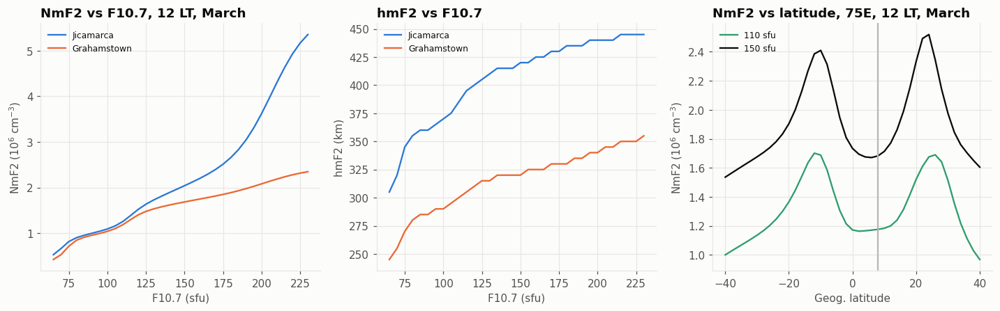

                                           check                                 value  pass_
  Jicamarca: largest NmF2 drop as F10.7 rises, %                                   0.0   True
Grahamstown: largest NmF2 drop as F10.7 rises, %                                   0.0   True
           75E 110 sfu: NmF2 maxima at latitudes [np.float64(-12.0), np.float64(26.0)]   True
           75E 150 sfu: NmF2 maxima at latitudes [np.float64(-10.0), np.float64(24.0)]   True


In [10]:
tic('Quick check: F10.7 response and equatorial crests')
AQ = np.arange(150, 800, 5.0); QQ = va[va["kp"] <= 20][["symh", "kp", "cpcp"]].median()
def peak(lat, lon, doy, lt, f, model="ANN"):
    n = len(AQ); d = pd.DataFrame(dict(doy=np.full(n, doy), lt=np.full(n, lt), ut=np.full(n, (lt - lon / 15.0) % 24), lon=np.full(n, lon), lat=np.full(n, lat), alt=AQ, symh=QQ["symh"], kp=QQ["kp"], f107=f, f107_81=f, cpcp=QQ["cpcp"]))
    ne = 10 ** PRED[model](feats(d)); k = int(ne.argmax()); return ne[k], AQ[k]
FQ, LQ = np.arange(65, 231, 5.0), np.arange(-40, 41, 2.0); fig, axs = plt.subplots(1, 3, figsize=(16, 4.2)); QC = []
for (nm, la, lo), c in zip((("Jicamarca", -11.95, -76.87), ("Grahamstown", -33.3, 26.5)), (BLUE, ORANGE)):
    P = np.array([peak(la, lo, 81, 12.0, f) for f in FQ]); axs[0].plot(FQ, P[:, 0] / 1e6, color=c, label=nm); axs[1].plot(FQ, P[:, 1], color=c, label=nm)
    drop = float(np.max(np.maximum.accumulate(P[:, 0]) / P[:, 0]) - 1); QC.append(dict(check=f"{nm}: largest NmF2 drop as F10.7 rises, %", value=100 * drop, pass_=drop < 0.01))
for f, c in ((110.0, GREEN), (150.0, INK)):
    nmL = np.array([peak(la, 75.0, 81, 12.0, f)[0] for la in LQ]); axs[2].plot(LQ, nmL / 1e6, color=c, label=f"{f:g} sfu")
    mx = [LQ[i] for i in range(1, len(LQ) - 1) if nmL[i] > nmL[i - 1] and nmL[i] >= nmL[i + 1]]; QC.append(dict(check=f"75E {f:g} sfu: NmF2 maxima at latitudes", value=str(mx), pass_=len(mx) >= 2))
axs[0].set(xlabel="F10.7 (sfu)", ylabel="NmF2 (10$^6$ cm$^{-3}$)", title="NmF2 vs F10.7, 12 LT, March"); axs[1].set(xlabel="F10.7 (sfu)", ylabel="hmF2 (km)", title="hmF2 vs F10.7"); axs[2].axvline(8, color=GRAY); axs[2].set(xlabel="Geog. latitude", ylabel="NmF2 (10$^6$ cm$^{-3}$)", title="NmF2 vs latitude, 75E, 12 LT, March")
for a in axs: a.legend(fontsize=8)
save(fig, "quick_check_f107_and_crests.png"); QC = pd.DataFrame(QC); QC.to_csv(os.path.join(OUT, "quick_check.csv"), index=False); print(QC.to_string(index=False))


## 4. Baselines (lookup tables) and metrics on the test years

In [11]:
tic('4. Baselines (lookup tables) and metrics on the test years')
for d in (tr, te):
    d["altb"] = (d["alt"] // 10).astype("int16"); d["ltb"] = (d["lt"] // 2).astype("int8"); d["latb"] = ((d["lat"] // 10).astype("int16") + 20); d["mb"] = d["month"]
def climatology(train, test, keys, fallback):
    def key(d):
        k = np.zeros(len(d), dtype="int64")
        for c in keys: k = k * 1000 + d[c].values.astype("int64") if c != "st" else d[c].values.astype("int64")
        return k
    ktr, kte = key(train), key(test); uk, inv = np.unique(ktr, return_inverse=True)
    mean = np.bincount(inv, weights=train["y"].values.astype("float64")) / np.bincount(inv)
    pos = np.clip(np.searchsorted(uk, kte), 0, len(uk) - 1); return np.where(uk[pos] == kte, mean[pos], fallback)
def tables(train, test):
    B0 = np.full(len(test), train["y"].mean()); B1 = climatology(train, test, ["altb"], B0)
    B2 = climatology(train, test, ["altb", "ltb", "latb"], B1); B3 = climatology(train, test, ["altb", "ltb", "latb", "mb"], B2)
    return B0, B1, B2, B3, climatology(train, test, ["st", "altb", "ltb", "mb"], B3)
te["B0"], te["B1"], te["B2"], te["B3"], te["B4"] = tables(tr, te)
r2 = lambda a, b: 1 - ((a - b) ** 2).sum() / ((a - a.mean()) ** 2).sum(); rmse = lambda a, b: float(np.sqrt(((a - b) ** 2).mean()))
def metrics(y, p):
    ne, pe = 10 ** y, 10 ** p
    return dict(R2_log=r2(y, p), RMSE_log10=rmse(y, p), typical_factor=10 ** rmse(y, p), bias_factor=10 ** float((p - y).mean()),
                RMSE_Ne_cm3=float(np.sqrt(np.mean((pe - ne) ** 2))), MAE_Ne_cm3=float(np.mean(np.abs(pe - ne))), MedAPE_pct=float(np.median(np.abs(pe - ne) / ne) * 100), R2_linear_Ne=r2(ne, pe))
cols = {"B0 global mean": "B0", "B1 + altitude": "B1", "B2 + local time, lat band": "B2", "B3 + month": "B3", "B4 + station (table)": "B4", **{m: "p_" + m for m in MODELS}}
M = pd.DataFrame({k: metrics(yte, te[c].values) for k, c in cols.items()}).T
M["skill_vs_B4"] = 1 - (M["RMSE_log10"] / M.loc["B4 + station (table)", "RMSE_log10"]) ** 2
M.round(4).to_csv(os.path.join(OUT, "metrics_test.csv")); print(M.round(3).to_string())

te["dn"] = np.where((te["lt"] >= 6) & (te["lt"] < 18), "day", "night"); te["altband"] = pd.cut(te["alt"], [0, 130, 160, 200, 250, 300, 400, 600])
S = []
for (b, dn), g in te.groupby(["altband", "dn"], observed=True):
    r = dict(altband=str(b), dn=dn, n=len(g), RMSE_table=rmse(g["y"].values, g["B4"].values))
    for m in MODELS: r["RMSE_" + m] = rmse(g["y"].values, g["p_" + m].values); r["R2_" + m] = r2(g["y"].values, g["p_" + m].values)
    S.append(r)
S = pd.DataFrame(S); S.round(3).to_csv(os.path.join(OUT, "metrics_by_altitude_daynight.csv")); print(S.round(3).to_string(index=False))
MC = {"ANN": GREEN}
FM = pd.DataFrame({m: metrics(yfu, fu["p_" + m].values) for m in MODELS}).T if len(fu) else pd.DataFrame(); print(f"\nfuture year(s) {FUTURE_YEARS}, scored once and never used for any choice:"); print(FM.round(3).to_string()); FM.round(4).to_csv(os.path.join(OUT, "metrics_future.csv"))
BYS = pd.DataFrame([dict(set=s_, source=SRC_NAME[int(k[0])], year=int(k[1]), rows=len(g), typical_factor=10 ** rmse(g["y"].values, g["p_ANN"].values), bias_factor=10 ** float((g["p_ANN"] - g["y"]).mean()), MedAPE_pct=float(np.median(np.abs(10 ** (g["p_ANN"].values - g["y"].values) - 1)) * 100), R2_Ne=r2(10 ** g["y"].values, 10 ** g["p_ANN"].values), median_F107=float(g["f107"].median())) for s_, D_ in (("test", te), ("future", fu)) for k, g in D_.groupby(["src", "year"])])
print("\nby source and year (Ne error as a factor, median absolute % error, R2 on Ne):"); print(BYS.round(3).to_string(index=False)); BYS.round(4).to_csv(os.path.join(OUT, "metrics_by_source_year.csv"), index=False)


[  8820s] 4. Baselines (lookup tables) and metrics on the test years


                           R2_log  RMSE_log10  typical_factor  bias_factor  RMSE_Ne_cm3  MAE_Ne_cm3  MedAPE_pct  R2_linear_Ne  skill_vs_B4
B0 global mean             -0.006       0.670           4.680        0.886   369880.844  197332.328      77.787        -0.208       -2.194
B1 + altitude               0.224       0.589           3.878        1.101   326131.533  178754.360      68.692         0.061       -1.463
B2 + local time, lat band   0.570       0.438           2.743        1.090   248140.715  124765.008      53.139         0.456       -0.365
B3 + month                  0.651       0.395           2.481        1.086   230822.689  115419.889      48.292         0.530       -0.108
B4 + station (table)        0.685       0.375           2.372        1.012   205383.779  106239.401      46.471         0.628        0.000
ANN                         0.813       0.289           1.946        1.093   137908.125   65325.867      24.818         0.832        0.405


   altband    dn       n  RMSE_table  RMSE_ANN  R2_ANN
  (0, 130]   day  759406       0.396     0.404   0.414
  (0, 130] night  153110       0.486     0.504   0.199
(130, 160]   day  732403       0.336     0.326   0.511
(130, 160] night  191118       0.492     0.518   0.268
(160, 200]   day 1033294       0.261     0.228   0.627
(160, 200] night  468306       0.510     0.531   0.365
(200, 250]   day 1049921       0.209     0.157   0.729
(200, 250] night 1145178       0.491     0.457   0.544
(250, 300]   day  596869       0.226     0.137   0.827
(250, 300] night  955246       0.354     0.301   0.560
(300, 400]   day  656976       0.324     0.144   0.914
(300, 400] night  833991       0.381     0.250   0.718
(400, 600]   day 1015529       0.400     0.161   0.904
(400, 600] night  971676       0.446     0.205   0.857

future year(s) [2024], scored once and never used for any choice:
     R2_log  RMSE_log10  typical_factor  bias_factor  RMSE_Ne_cm3  MAE_Ne_cm3  MedAPE_pct  R2_linear_Ne
ANN 


by source and year (Ne error as a factor, median absolute % error, R2 on Ne):
   set   source  year    rows  typical_factor  bias_factor  MedAPE_pct  R2_Ne  median_F107
  test     GIRO  2002 1656714           2.731        1.386      36.372  0.748        164.9
  test     GIRO  2009 1409796           2.132        1.049      27.350  0.832         70.4
  test     GIRO  2014 1540951           2.047        1.147      23.775  0.898        153.1
  test     GIRO  2021 1487809           2.003        1.006      24.907  0.832         77.8
  test COSMIC-1  2009 1991965           1.493        0.984      19.909  0.848         69.8
  test COSMIC-1  2014 1998923           1.553        1.033      20.810  0.884        142.9
  test COSMIC-2  2021 1996082           1.779        1.113      29.108  0.778         77.9
future COSMIC-2  2024 1998041           1.835        1.104      26.811  0.669        178.8


## 4b. Smoothness of the raw output (roughness, peaks per profile) and real occultation profiles vs the model

[  8886s] 4b. Smoothness of the RAW network output (no filtering anywhere)


roughness = mean |second difference| of log10 Ne on a 5 km grid; peaks = local maxima per profile (about 1 is clean)
                R2_log  RMSE_log10  roughness  max_roughness  mean_peaks  pct_profiles_1_peak
model                                                                                        
ANN             0.8127      0.2892     0.0008         0.0265      1.0000               100.00
ANN no penalty  0.8239      0.2804     0.0012         0.0510      1.0225                97.75


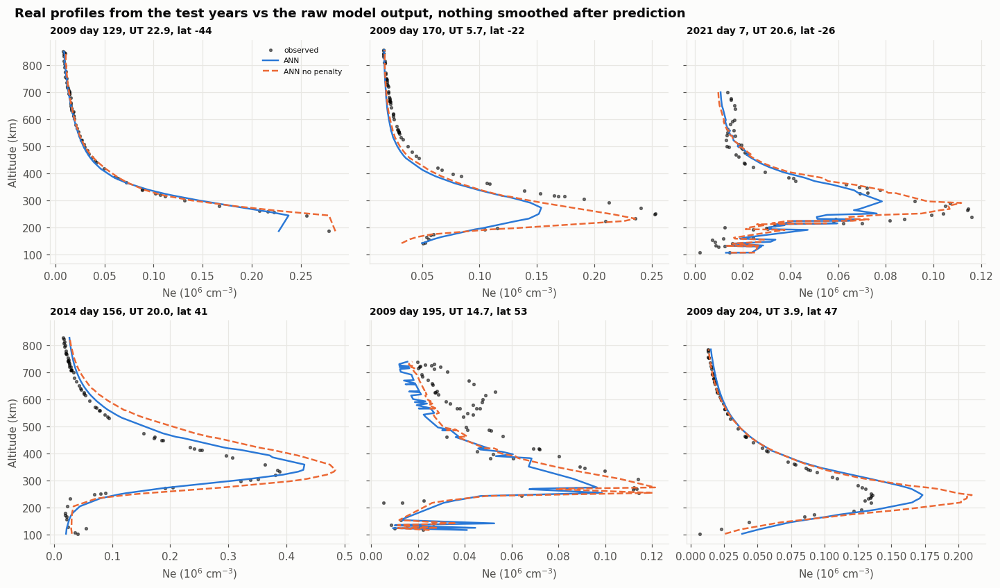

In [12]:
tic('4b. Smoothness of the RAW network output (no filtering anywhere)')
AGR = np.arange(150, 801, 5.0); _sel = np.random.RandomState(1).choice(len(Xte), min(400, len(Xte)), replace=False); _base = Xte.iloc[_sel].reset_index(drop=True)
def profile_grid(pred, base):
    n = len(base); G = pd.DataFrame(np.repeat(base.values, len(AGR), axis=0), columns=base.columns); G["alt"] = np.tile(AGR, n); return pred(G).reshape(n, len(AGR))
rows = []
for nm_, pr_ in PRED.items():
    P = profile_grid(pr_, _base); d2 = np.abs(np.diff(P, 2, axis=1)); dP = np.diff(P, axis=1); pk = ((dP[:, :-1] > 0) & (dP[:, 1:] <= 0)).sum(axis=1)
    rows.append(dict(model=nm_, R2_log=r2(yte, te["p_" + nm_].values), RMSE_log10=rmse(yte, te["p_" + nm_].values), roughness=float(d2.mean()), max_roughness=float(d2.max()), mean_peaks=float(pk.mean()), pct_profiles_1_peak=float((pk == 1).mean() * 100)))
SM = pd.DataFrame(rows).set_index("model"); print("roughness = mean |second difference| of log10 Ne on a 5 km grid; peaks = local maxima per profile (about 1 is clean)"); print(SM.round(4).to_string()); SM.round(5).to_csv(os.path.join(OUT, "smoothness_vs_accuracy.csv"))
te_all = df[is_te].copy(); te_all["pid"] = te_all["year"].astype("int64") * 10**11 + te_all["doy"].astype("int64") * 10**8 + np.round(te_all["ut"] * 100).astype("int64") * 10**3 + np.round((te_all["lon"] + 180) / 5).astype("int64")
cnt_ = te_all.groupby("pid").size(); good = cnt_[cnt_ >= 20].sort_values(ascending=False).index.values[:60]; pids = np.random.RandomState(3).choice(good, min(6, len(good)), replace=False) if len(good) else []
if len(pids) == 0: print("no occultation with >= 20 rows in the test years (KEEP too small?): the profile panels below stay empty")
fig, axs = plt.subplots(2, 3, figsize=(13, 7.6), sharey=True, constrained_layout=True); pal = [BLUE, ORANGE, GREEN, GRAY, DGRAY, "#8c2fb0"]
for a, pid in zip(axs.ravel(), pids):
    g = te_all[te_all["pid"] == pid].sort_values("alt"); Xg = feats(g); a.scatter(g["ne"] / 1e6, g["alt"], s=6, c="k", alpha=.5, label="observed")
    for k_, (nm_, pr_) in enumerate(PRED.items()): a.plot(10 ** pr_(Xg) / 1e6, g["alt"].values, lw=1.6, color=pal[k_ % 6], ls="--" if nm_ == "ANN no penalty" else "-", label=nm_)
    a.set_title(f"{int(g['year'].iloc[0])} day {int(g['doy'].iloc[0])}, UT {g['ut'].iloc[0]:.1f}, lat {g['lat'].mean():.0f}", fontsize=9); a.set_xlabel("Ne (10$^6$ cm$^{-3}$)")
axs[0, 0].set_ylabel("Altitude (km)"); axs[1, 0].set_ylabel("Altitude (km)"); axs[0, 0].legend(fontsize=7); fig.suptitle("Real profiles from the test years vs the raw model output, nothing smoothed after prediction", x=.01, ha="left", fontweight="bold"); save(fig, "fig_smooth_profiles_raw_model_vs_cosmic.png"); del te_all

# PART B: figures of the paper (Gowtam et al. 2019, JGR Space Physics, ANNIM-3D)
Fig 1 to 10 in the paper's order and layout. Differences are stated in each title: the paper's ISR radars and in-situ satellites are not in our data, so Fig 5, 6 and 7 use COSMIC observations and IRI instead. Fig 4 uses F10.7 = 70 to 190 sfu.

In [13]:
ALTG = np.arange(100, 801, 2.0); PEAKMASK = (ALTG >= 150) & (ALTG <= 700)
import sys, subprocess
from matplotlib.collections import LineCollection
def _coast_segs():
    try:
        try: from mpl_toolkits.basemap import Basemap
        except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "basemap", "-q"]); from mpl_toolkits.basemap import Basemap
        m_ = Basemap(projection="cyl", llcrnrlon=-180, urcrnrlon=180, llcrnrlat=-90, urcrnrlat=90, resolution="c"); return [np.array(s_) for s_ in m_.coastsegs if len(s_) > 1]
    except Exception as e1:
        try:
            import cartopy.feature as cf; return [np.array(p_.coords) for g_ in cf.NaturalEarthFeature("physical", "coastline", "110m").geometries() for p_ in getattr(g_, "geoms", [g_])]
        except Exception as e2: print("no coastlines available (pip install basemap):", repr(e1)[:60]); return []
COAST = _coast_segs()
def add_coast(ax):
    if COAST: xl, yl = ax.get_xlim(), ax.get_ylim(); ax.add_collection(LineCollection(COAST, colors="k", linewidths=.5, alpha=.7, zorder=4)); ax.set_xlim(xl); ax.set_ylim(yl)
from scipy.spatial import cKDTree
_s = df.sample(n=min(3_000_000, len(df)), random_state=SEED); _g = _s[["lat", "lon", "diplat"]].copy()
DRIFT_LT = _s.groupby(_s["lt"].astype(int).clip(0, 23))["drift"].median().reindex(np.arange(24)).interpolate(limit_direction="both").values; _kpb = _s.groupby(_s["kp"].round())["cpcp"].median(); del _s
def drift_cpcp(lt, kp): return DRIFT_LT[np.asarray(lt).astype(int) % 24], np.interp(kp, _kpb.index.values, _kpb.values)
_g["la"], _g["lo"] = (_g["lat"] / 2).round() * 2, (_g["lon"] / 2).round() * 2; _g = _g.groupby(["la", "lo"]).median().reset_index()
_tree, _gv = cKDTree(np.c_[_g["la"], _g["lo"]]), _g[["diplat"]].values
def drivers(symh):
    return np.clip(1 + np.maximum(-symh - 10, 0) / 18, 0, 9)
PLOTM = "ANN"
_c5 = torch.load("/home/user1/Downloads/ne_results_v5/ne_v5_ANN.pt", weights_only=False); FEATS5 = list(_c5["feats"]); _n5 = build_mlp(len(FEATS5), _c5["layers"], _c5["act"]).to(dev); _n5.load_state_dict(_c5["state"]); _n5.eval(); _m5, _s5 = torch.tensor(_c5["mu"], dtype=torch.float32, device=dev), torch.tensor(_c5["sd"], dtype=torch.float32, device=dev)
def pred_v5(X, bs=262144):
    a = np.ascontiguousarray(X[FEATS5].values, dtype="float32"); out = []
    with torch.no_grad():
        for i in range(0, len(a), bs): out.append(_n5((torch.from_numpy(a[i:i+bs]).to(dev) - _m5) / _s5).squeeze(1).cpu())
    return torch.cat(out).numpy() * _c5["ysd"] + _c5["ymu"]
print("v5 loaded for comparison:", len(FEATS5), "inputs")
def season_drv(doy0, f0, f1):
    dd = np.abs(df["doy"].values - doy0); g = df.loc[(np.minimum(dd, 365 - dd) <= 20) & (df["f107"].values >= f0) & (df["f107"].values <= f1) & (df["kp"].values < 3), ["lt", "kp", "symh", "cpcp", "drift", "f107_81"]]
    return dict(kp=float(g["kp"].median()), symh=float(g["symh"].median()), cpcp=float(g["cpcp"].median()), f81=float(g["f107_81"].median()), drift=g.groupby(g["lt"].astype(int).clip(0, 23))["drift"].median().reindex(np.arange(24)).interpolate(limit_direction="both").values)
def ne_model(doy, lt, lat, lon, alt, symh, f107, model=None, kp_in=None, drv=None):
    a = np.broadcast_arrays(*[np.asarray(v, float) for v in (doy, lt, lat, lon, alt, symh, f107)]); shp = a[0].shape; doy, lt, lat, lon, alt, symh, f107 = [x.ravel() for x in a]
    ut = (lt - lon / 15.0) % 24; dip = _gv[_tree.query(np.c_[lat, lon])[1], 0]; kp = drivers(symh) if kp_in is None else np.full(symh.shape, float(kp_in)); dr, cp = drift_cpcp(lt, kp); f81 = f107
    if drv is not None: kp, cp, f81, dr = np.full(symh.shape, drv["kp"]), np.full(symh.shape, drv["cpcp"]), np.full(symh.shape, drv["f81"]), drv["drift"][lt.astype(int) % 24]
    X = featsw(pd.DataFrame({"doy": doy, "ut": ut, "lt": lt, "lon": lon, "lat": lat, "diplat": dip, "alt": alt, "symh": symh, "kp": kp,
                            "f107": f107, "f107_81": f81, "drift": dr, "cpcp": cp}))
    return (10 ** PRED[model or PLOTM](X)).reshape(shp)
def peaks(ne, alts=ALTG):
    i = np.where((alts >= 150) & (alts <= 700), ne, -1).argmax(-1); return np.take_along_axis(ne, np.asarray(i)[..., None], -1)[..., 0], alts[i]

SITES = [("Jicamarca (11.95°S, 76.87°W)", -11.95, -76.87), ("Grahamstown (33.3°S, 26.5°E)", -33.3, 26.5)]; FLV = [70, 90, 110, 130, 150, 170, 190]; FF = np.arange(70, 200.1, 5.0)
Dn = df.loc[df["lt"].between(11, 13) & df["doy"].between(61, 101), ["year", "lat", "lon", "lt", "doy", "f107", "alt", "ne"]]
def obs_peaks(lat0, lon0):
    b = Dn[Dn["lat"].between(lat0 - 12, lat0 + 12) & Dn["lon"].between(lon0 - 20, lon0 + 20)]; out = []
    for f in range(70, 231, 10):
        g = b[(b["f107"] >= f - 5) & (b["f107"] < f + 5)]
        if len(g) < 100 or len(g[["year", "doy"]].drop_duplicates()) < 5: continue
        pr = g.groupby((g["alt"] // 20) * 20 + 10)["ne"].agg(["median", "size"]); pr = pr[pr["size"] >= 8]
        if len(pr) < 5: continue
        i = int(np.argmax(pr["median"].values))
        if 0 < i < len(pr) - 1: out.append((g["f107"].mean(), pr["median"].values[i], pr.index[i]))
    return np.array(out)

v5 loaded for comparison: 21 inputs


In [14]:
tic('20a. Helpers: IRI (PyIRI), March window rows')
import sys, subprocess, datetime as dt
try:
    import PyIRI, PyIRI.main_library as ml
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "PyIRI", "-q"]); import PyIRI, PyIRI.main_library as ml
COEF = os.path.join(os.path.dirname(PyIRI.__file__), "coefficients")
def iri_cm3(year, doy, ut, lon, lat, alt, f107):
    day = dt.date(int(year), 1, 1) + dt.timedelta(days=int(doy) - 1); lon = ((np.asarray(lon, float) + 180) % 360) - 180
    out = ml.IRI_density_1day(day.year, day.month, day.day, np.array([float(ut)]), lon, np.asarray(lat, float), np.asarray(alt, float), float(f107), COEF, 0)
    return np.diagonal(out[-1][0]) / 1e6
MAR_DOY, WINH = int(os.environ.get("NE_MAR_DOY", 80)), 20
_m = np.asarray(is_te) & (np.abs(df["doy"].values - MAR_DOY) <= WINH); DW = df.iloc[np.flatnonzero(_m)]; del _m
print(f"{len(DW):,} test-year rows in the day {MAR_DOY} +-{WINH} window")
print("helpers ready")

[  8910s] 20a. Helpers: IRI (PyIRI), March window rows


3,877,719 test-year rows in the day 80 +-20 window
helpers ready


## Whole dataset: every row of every month is read here, with the model on those rows


In [15]:
tic('Whole dataset: reading every row of every month')
_mon = os.environ.get("NE_STREAM_MONTHS", ""); _fl = [p for p in FL["path"] if not _mon or os.path.basename(p)[:-8].split("_")[2] in _mon.split(",")]
SB = {"Jicamarca": (-11.95, -76.87), "Grahamstown": (-33.3, 26.5), "Millstone": (42.62, -71.49)}; SEAS = [("March", 80), ("June", 172), ("December", 355), ("All year", None)]; UNSEEN = list(VAL_YEARS) + list(TEST_YEARS) + list(FUTURE_YEARS)
LA = np.zeros((4, 2, 8, 36, 40, 3)); NOON = np.zeros((36, 80, 3)); MID = np.zeros((2, 6, 80, 3)); YR = {}; DAILY = {y: {} for y in UNSEEN}; WBL = []; PROF = []
def profile_peaks(d, p=None):
    d = d[d["alt"].between(150, 700)]
    if p is not None: p = {k: v[d.index.values] for k, v in p.items()}
    o = np.lexsort((d["lon"].values, d["ut"].values, d["doy"].values)); doy, ut, lon, alt, ne_ = [d[c].values[o] for c in ("doy", "ut", "lon", "alt", "ne")]; new = np.r_[True, (np.diff(doy) != 0) | (np.diff(ut) != 0) | (np.abs(np.diff(lon)) > 10)]; pid = np.cumsum(new) - 1; n = pid[-1] + 1
    cnt = np.bincount(pid, minlength=n); a0 = np.full(n, 1e9); a1 = np.full(n, -1e9); np.minimum.at(a0, pid, alt); np.maximum.at(a1, pid, alt)
    def peak(v):
        q = np.lexsort((v, pid)); last = np.r_[np.flatnonzero(np.diff(pid[q])), len(q) - 1]; return v[q][last], alt[q][last], q[last]
    nm, hm, iq = peak(ne_); T = pd.DataFrame({"nm": nm, "hm": hm, "lat": d["lat"].values[o][iq], "dip": d["diplat"].values[o][iq], "lon": lon[iq], "doy": doy[iq], "ut": ut[iq], "cnt": cnt, "a0": a0, "a1": a1})
    if p is not None:
        for k, v in p.items(): a_, b_, _ = peak(10 ** v[o]); T["nm_" + k], T["hm_" + k] = a_, b_
    T["lt"] = (T["ut"] + T["lon"] / 15) % 24; T["month"] = np.minimum(np.searchsorted(MONTH_END, T["doy"].astype(int) - 1, side="right") + 1, 12)
    return T[(T["cnt"] >= 30) & (T["hm"] >= 160) & (T["hm"] <= 550) & (T["a0"] <= T["hm"] - 30) & (T["a1"] >= T["hm"] + 50)].copy()
for _i, f in enumerate(_fl):
    if _i % 6 == 0: print(f"{_i}/{len(_fl)} files, {time.time()-T00:.0f}s", flush=True)
    y_ = int(os.path.basename(f).split("_")[1]); d = pd.read_parquet(f, columns=NEED); d = d[(d["ne"] > 0) & (d["f107"] < F107_MAX) & (d["f107_81"] < F107_MAX) & ~d.isna().any(axis=1) & d["kp"].between(0, 90) & d["diplat"].abs().le(90) & (d["alt"] >= COSMIC_ALT_MIN)].reset_index(drop=True); d["lt"] = (d["ut"] + d["lon"] / 15.0) % 24
    hi = d["ne"].values >= NE_MIN; dl = d[~hi]; d = d[hi].reset_index(drop=True); d["y"] = np.log10(d["ne"]).astype("float32"); X_ = featsw(d); p4 = PRED["ANN"](X_); yv = d["y"].values; r_ = YR.setdefault(y_, dict(n=0, s=0.0, sy=0.0, syy=0.0, low_n=0, low_s=0.0)); r_["n"] += len(d); r_["s"] += float(((p4 - yv) ** 2).sum()); r_["sy"] += float(yv.astype("float64").sum()); r_["syy"] += float((yv.astype("float64") ** 2).sum())
    if len(dl): r_["low_n"] += len(dl); r_["low_s"] += float(((PRED["ANN"](feats(dl)) - np.log10(dl["ne"].values)) ** 2).sum())
    pp = {"ANN": p4}
    if y_ in UNSEEN:
        p3 = pred_v5(X_); pp["v5"] = p3
        for dy in np.unique(d["doy"].values):
            m = d["doy"].values == dy; DAILY[y_][int(dy)] = (int(m.sum()), float(((p3[m] - yv[m]) ** 2).sum()), float(((p4[m] - yv[m]) ** 2).sum()))
    del X_; PROF.append(profile_peaks(d, pp).assign(year=y_))
    lt_, la_, lo_, al_, dy_, fv = d["lt"].values, d["lat"].values, d["lon"].values, d["alt"].values, d["doy"].values, d["f107"].values
    il, ila, ial = np.clip((lt_ // 3).astype(int), 0, 7), np.clip(((la_ + 90) // 5).astype(int), 0, 35), np.clip(((al_ - 100) // 20).astype(int), 0, 39); key = ((il * 36 + ila) * 40 + ial).astype("int64"); SZ = 8 * 36 * 40; sec = (lo_ >= 60) & (lo_ <= 90)
    for s_i, (_, c_) in enumerate(SEAS):
        if c_ is None: sm = np.ones(len(d), bool)
        else: dd = np.abs(dy_ - c_); sm = np.minimum(dd, 365 - dd) <= 20
        for sc, mk in ((0, sm), (1, sm & sec)):
            if mk.any():
                k_ = key[mk]; LA[s_i, sc, ..., 0] += np.bincount(k_, minlength=SZ).reshape(8, 36, 40); LA[s_i, sc, ..., 1] += np.bincount(k_, weights=yv[mk], minlength=SZ).reshape(8, 36, 40); LA[s_i, sc, ..., 2] += np.bincount(k_, weights=p4[mk], minlength=SZ).reshape(8, 36, 40)
    ia10 = np.clip(((al_ - 100) // 10).astype(int), 0, 79); nm_ = (lt_ >= 11) & (lt_ <= 13); k_ = (ila[nm_] * 80 + ia10[nm_]).astype("int64")
    for j_, w_ in enumerate((None, yv[nm_], p4[nm_])): NOON[..., j_] += np.bincount(k_, weights=w_, minlength=36 * 80).reshape(36, 80)
    im = (la_ >= 40) & (la_ <= 55); fb_ = np.searchsorted([80, 110, 140, 180], fv, side="left")
    for dn_, tm in ((0, (lt_ >= 11) & (lt_ <= 13)), (1, (lt_ >= 23) | (lt_ <= 1))):
        mk = im & tm
        for fc_, sel in ((0, mk), *[(b_ + 1, mk & (fb_ == b_)) for b_ in range(5)]):
            if sel.any():
                k_ = ia10[sel]; MID[dn_, fc_, :, 0] += np.bincount(k_, minlength=80); MID[dn_, fc_, :, 1] += np.bincount(k_, weights=yv[sel], minlength=80); MID[dn_, fc_, :, 2] += np.bincount(k_, weights=p4[sel], minlength=80)
    for sn_, (a_, b_) in SB.items():
        m = (np.abs(la_ - a_) <= 8) & (np.abs(lo_ - b_) <= 15)
        if m.any(): WBL.append(pd.DataFrame({"site": sn_, "year": y_, "doy": dy_[m], "lt": lt_[m], "lat": la_[m], "lon": lo_[m], "alt": al_[m], "ne": d["ne"].values[m], "p": p4[m], "f107": fv[m], "symh": d["symh"].values[m], "kp": d["kp"].values[m], "src": d["src"].values[m]}))
    del d, dl
WB = pd.concat(WBL, ignore_index=True); del WBL; PROF = pd.concat(PROF, ignore_index=True); gc.collect()
print(f"whole dataset read: {sum(r_['n'] for r_ in YR.values()):,} rows from {len(_fl)} files; rows per year: " + str({k: v["n"] for k, v in YR.items()}))


[  8911s] Whole dataset: reading every row of every month


0/497 files, 8911s


6/497 files, 8976s


12/497 files, 9176s


18/497 files, 9352s


24/497 files, 9484s


... (75 outputs left out)

480/497 files, 12390s


486/497 files, 12403s


492/497 files, 12417s


whole dataset read: 1,916,555,276 rows from 497 files; rows per year: {2006: 47931952, 2007: 182825000, 2008: 164529833, 2009: 173282161, 2010: 136025739, 2011: 111787500, 2012: 116409763, 2013: 130734819, 2014: 102672514, 2015: 91400559, 2016: 54067126, 2017: 28122373, 2019: 17536710, 2020: 96726369, 2021: 125243379, 2022: 99739374, 2023: 129401013, 2024: 68637375, 1994: 22345, 1995: 84062, 1996: 30335, 1997: 178660, 1998: 536502, 1999: 1008206, 2000: 949813, 2001: 3232192, 2002: 5198256, 2003: 3358674, 2004: 9584853, 2005: 7727044, 2018: 7570775}


## Fig 1: data used in the model

[ 12434s] Fig 1: data used


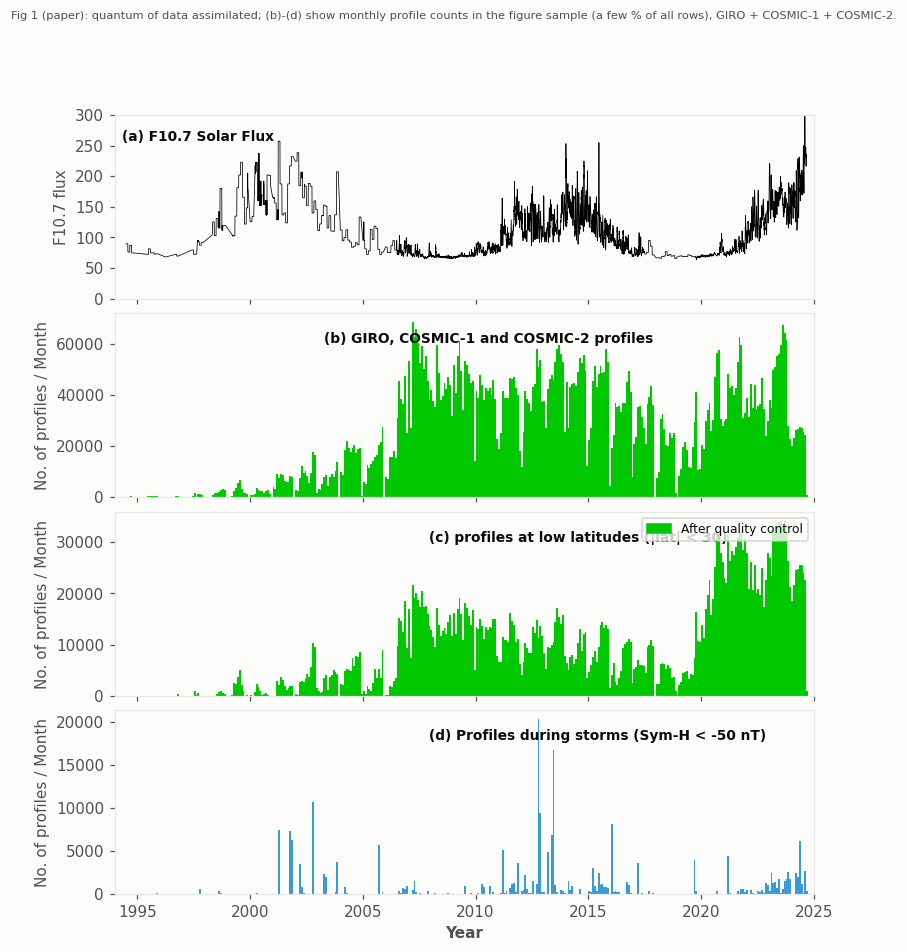

In [16]:
tic('Fig 1: data used')
Y0, Y1 = int(df["year"].min()), int(df["year"].max()) + 1
yr_ = df["year"].values.astype("int64"); doy_ = df["doy"].values.astype("int64"); ut_ = np.round(df["ut"].values * 100).astype("int64"); src_ = df["src"].values
key = (((yr_ - 1980) * 366 + doy_) * 100000 + ut_) * 20_000_000 + np.round((df["lon"].values + 180) / 5).astype("int64")
_uk, first = np.unique(key, return_index=True); del key; _p, _b = _uk // 20_000_000, _uk % 20_000_000; first = first[np.r_[True, (np.diff(_p) != 0) | (np.diff(_b) > 2)]]; del _uk, _p, _b
lat_f = df['lat'].values[first]; mi = (yr_[first] - Y0) * 12 + df["month"].values[first].astype(int) - 1; sf = src_[first]; storm_f = df["symh"].values[first] < -50; nm_ = (Y1 - Y0) * 12; del yr_, doy_, ut_
cnt = lambda m: np.bincount(mi[m], minlength=nm_)[:nm_]; tm = Y0 + (np.arange(nm_) + .5) / 12
dd = df.groupby(["year", "doy"])["f107"].median(); tt = dd.index.get_level_values(0).values + (dd.index.get_level_values(1).values - .5) / 365.25
fig = plt.figure(figsize=(8.2, 9.2)); gs = fig.add_gridspec(4, 1, hspace=.08); ax = [fig.add_subplot(gs[i]) for i in range(4)]
ax[0].plot(tt, dd.values, color="k", lw=.5); ax[0].set_ylim(0, 300); ax[0].set_ylabel("F10.7 flux"); ax[0].text(.01, .86, "(a) F10.7 Solar Flux", transform=ax[0].transAxes, fontweight="bold", fontsize=9)
for a_, m_, ttl, c_ in [(ax[1], sf >= 0, "(b) GIRO, COSMIC-1 and COSMIC-2 profiles", "#00c800"), (ax[2], np.abs(lat_f) < 30, "(c) profiles at low latitudes (|lat| < 30)", "#00c800"), (ax[3], storm_f, "(d) Profiles during storms (Sym-H < -50 nT)", "#3a9ad9")]:
    a_.bar(tm, cnt(m_), width=1 / 12, color=c_); a_.set_ylabel("No. of profiles / Month"); a_.text(.30 if a_ is ax[1] else .45, .84, ttl, transform=a_.transAxes, fontweight="bold", fontsize=9)
from matplotlib.patches import Patch
ax[2].legend(handles=[Patch(color="#00c800", label="After quality control")], loc="upper right", fontsize=8, frameon=True)
for a_ in ax: a_.set_xlim(Y0, Y1); a_.grid(False); a_.spines["top"].set_visible(True); a_.spines["right"].set_visible(True)
for a_ in ax[:3]: a_.set_xticklabels([])
ax[3].set_xlabel("Year", fontweight="bold")
fig.text(.01, .975, "Fig 1 (paper): quantum of data assimilated; (b)-(d) show monthly profile counts in the figure sample (a few % of all rows), GIRO + COSMIC-1 + COSMIC-2.", fontsize=7.5, color=INK2)
save(fig, "paper_fig01_data.png"); del mi, sf, storm_f, first

## Fig 2: architecture of the neural network

[ 12456s] Fig 2: architecture


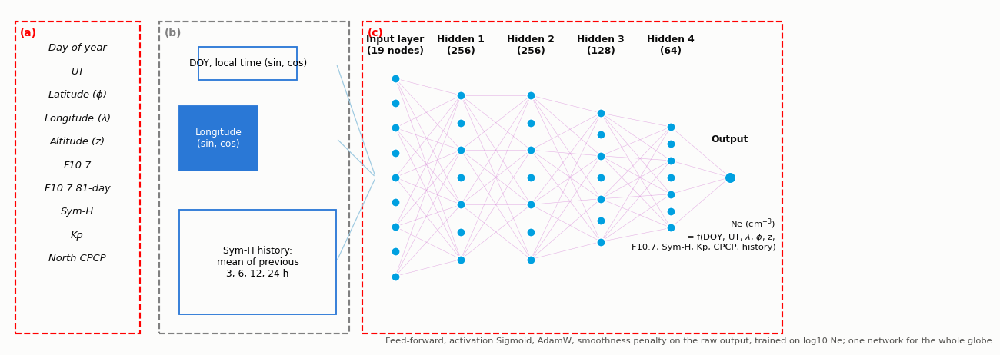

In [17]:
tic('Fig 2: architecture')
from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(12, 5.2)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 5.2)
def dbox(x, y, w, h, c, lab=None, ls="--"): ax.add_patch(Rectangle((x, y), w, h, fill=False, ec=c, ls=ls, lw=1.4)); (ax.text(x + .08, y + h - .22, lab, fontsize=9, fontweight="bold", color=c) if lab else None)
dbox(.1, .2, 1.9, 4.8, "r", "(a)")
for k, t in enumerate(["Day of year", "UT", "Latitude ($\\phi$)", "Longitude ($\\lambda$)", "Altitude (z)", "F10.7", "F10.7 81-day", "Sym-H", "Kp", "North CPCP"]): ax.text(1.05, 4.55 - .36 * k, t, ha="center", fontsize=8.5, style="italic")
dbox(2.3, .2, 2.9, 4.8, "gray", "(b)")
def tbox(x, y, w, h, t, c="#2a78d6", fill=False):
    ax.add_patch(Rectangle((x, y), w, h, fc=(c if fill else "none"), ec=c, lw=1.2)); ax.text(x + w / 2, y + h / 2, t, ha="center", va="center", fontsize=8, color=("w" if fill else "k"))
tbox(2.9, 4.1, 1.5, .5, "DOY, local time (sin, cos)"); tbox(2.6, 2.7, 1.2, 1.0, "Longitude\n(sin, cos)", fill=True); tbox(2.6, .5, 2.4, 1.6, "Sym-H history:\nmean of previous\n3, 6, 12, 24 h")
for y_ in (4.35, 3.2, 1.3): ax.annotate("", xy=(5.6, 2.6), xytext=(5.0, y_), arrowprops=dict(arrowstyle="-", color="#9ecae1", lw=.8))
dbox(5.4, .2, 6.4, 4.8, "r", "(c)")
ns_ = list(LAYERS); xs_ = list(np.linspace(6.9, 10.1, len(ns_))) if len(ns_) > 1 else [8.5]; ys_ = lambda n: 2.6 + (np.arange(7) - 3) * .42 * (n / max(ns_)) ** .35
ax.text(5.9, 4.5, f"Input layer\n({len(FEATS)} nodes)", ha="center", fontsize=8, fontweight="bold")
ax.scatter([5.9] * 9, 2.6 + (np.arange(9) - 4) * .38, s=55, color="#00a0e0", zorder=3, ec="w")
for k, (x0, n) in enumerate(zip(xs_, ns_)):
    ax.scatter([x0] * 7, ys_(n), s=55, color="#00a0e0", zorder=3, ec="w"); ax.text(x0, 4.5, f"Hidden {k + 1}\n({n})", ha="center", fontsize=8, fontweight="bold")
    xp, np_ = (5.9, 9) if k == 0 else (xs_[k - 1], 7); yp = (2.6 + (np.arange(9) - 4) * .38) if k == 0 else ys_(ns_[k - 1])
    for a0 in yp[::2]:
        for b0 in ys_(n)[::2]: ax.plot([xp, x0], [a0, b0], color="#d98cd9", lw=.35, alpha=.7, zorder=1)
ax.scatter([11.0], [2.6], s=90, color="#00a0e0", zorder=3, ec="w"); ax.text(11.0, 3.15, "Output", ha="center", fontsize=8, fontweight="bold")
for x0 in xs_[-1:]:
    for b0 in ys_(ns_[-1])[::2]: ax.plot([x0, 11.0], [b0, 2.6], color="#d98cd9", lw=.35, alpha=.7)
ax.text(11.7, 2.0, "Ne (cm$^{-3}$)\n= f(DOY, UT, $\\lambda$, $\\phi$, z,\nF10.7, Sym-H, Kp, CPCP, history)", fontsize=7.5, ha="right", va="top")
ax.text(5.75, .05, f"Feed-forward, activation {', '.join(ACT_LIST)}, AdamW, smoothness penalty on the raw output, trained on log10 Ne; one network for the whole globe", fontsize=7.5, color=INK2, ha="left")
save(fig, "paper_fig02_architecture.png")

## Fig 3: raw model profile, 100 to 850 km (the paper's alpha-Chapman and IRI extrapolation is not used)

[ 12456s] Fig 3: raw model profile


{'NmF2': 797012.19, 'hmF2': 344.0}


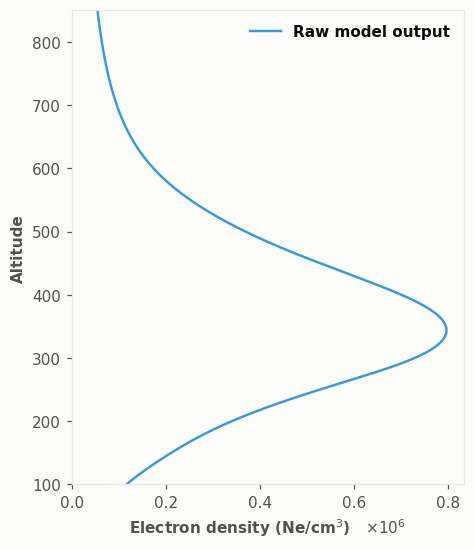

In [18]:
tic('Fig 3: raw model profile')
AL3 = np.arange(100, 851, 1.0); prim = ne_model(80, 12.0, -11.95, -76.87, AL3, -5.0, 75.0); nm3, hm3 = peaks(prim, AL3)
fig, ax = plt.subplots(figsize=(4.6, 5.6)); ax.plot(prim / 1e6, AL3, color="#3a9ad9", lw=1.6, label="Raw model output")
ax.set_xlabel("Electron density (Ne/cm$^3$)   $\\times 10^6$", fontweight="bold"); ax.set_ylabel("Altitude", fontweight="bold"); ax.set_ylim(100, 850); ax.set_xlim(left=0); ax.grid(False); ax.legend(loc="upper right", prop={"weight": "bold"})
for s_ in ("top", "right"): ax.spines[s_].set_visible(True)
print({"NmF2": round(float(nm3), 2), "hmF2": float(hm3)}); save(fig, "paper_fig03_profile_raw.png")


## Fig 4: profiles at 12 LT, March equinox, for F10.7 = 70 to 190 sfu, with NmF2 and hmF2 against observations (Jicamarca and Grahamstown)

[ 12457s] Fig 4: profiles vs F10.7


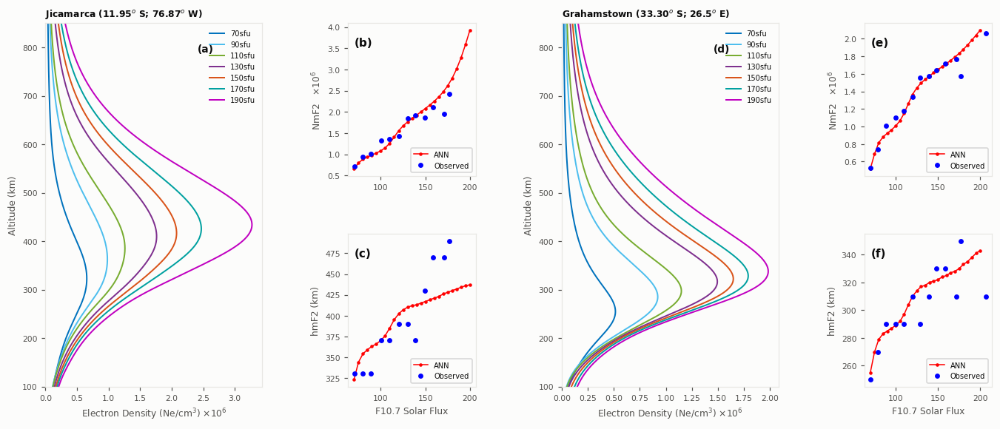

In [19]:
tic('Fig 4: profiles vs F10.7')
Dn = WB[WB["lt"].between(11, 13) & WB["doy"].between(61, 101) & (WB["site"] != "Millstone")]
FL4 = [70, 90, 110, 130, 150, 170, 190]; FF4 = np.arange(70, 200.1, 5.0); AL4 = np.arange(100, 851, 1.0)
C4 = ["#0072BD", "#4DBEEE", "#77AC30", "#7E2F8E", "#D95319", "#00A0A0", "#C000C0", "#EDB120", "#000000"]
S4 = [("Jicamarca (11.95$^o$ S; 76.87$^o$ W)", -11.95, -76.87, "(a)", "(b)", "(c)"), ("Grahamstown (33.30$^o$ S; 26.5$^o$ E)", -33.3, 26.5, "(d)", "(e)", "(f)")]
fig = plt.figure(figsize=(15, 5.8)); gs = fig.add_gridspec(2, 4, width_ratios=[1.7, 1, 1.7, 1], wspace=.5, hspace=.38)
for k, (nm, la, lo, l1, l2, l3) in enumerate(S4):
    a = fig.add_subplot(gs[:, 2 * k]); b_ = fig.add_subplot(gs[0, 2 * k + 1]); c_ = fig.add_subplot(gs[1, 2 * k + 1])
    for f, c in zip(FL4, C4):
        pr = ne_model(81, 12.0, la, lo, AL4, -5.0, float(f)); a.plot(pr / 1e6, AL4, color=c, lw=1.3, label=f"{f}sfu")
    P = np.array([peaks(ne_model(81, 12.0, la, lo, AL4, -5.0, float(f)), AL4) for f in FF4]); o = obs_peaks(la, lo)
    a.set_ylim(100, 850); a.set_xlim(left=0); a.set_xlabel("Electron Density (Ne/cm$^3$) $\\times 10^6$", fontsize=8); a.set_ylabel("Altitude (km)", fontsize=8); a.set_title(nm, fontsize=8, fontweight="bold"); a.text(.7, .92, l1, transform=a.transAxes, fontsize=9, fontweight="bold"); a.legend(fontsize=6.5, loc="upper right", frameon=False)
    b_.plot(FF4, P[:, 0] / 1e6, "r.-", ms=4, lw=1, label="ANN"); c_.plot(FF4, P[:, 1], "r.-", ms=4, lw=1, label="ANN")
    if len(o): b_.plot(o[:, 0], o[:, 1] / 1e6, "o", color="b", ms=3.5, label="Observed"); c_.plot(o[:, 0], o[:, 2], "o", color="b", ms=3.5, label="Observed")
    b_.set_ylabel("NmF2   $\\times 10^6$", fontsize=8); c_.set_ylabel("hmF2 (km)", fontsize=8); c_.set_xlabel("F10.7 Solar Flux", fontsize=8); b_.text(.05, .85, l2, transform=b_.transAxes, fontweight="bold"); c_.text(.05, .85, l3, transform=c_.transAxes, fontweight="bold")
    for q in (a, b_, c_):
        q.grid(False); q.tick_params(labelsize=7)
        for s_ in ("top", "right"): q.spines[s_].set_visible(True)
    b_.legend(fontsize=6.5, loc="lower right", frameon=True); c_.legend(fontsize=6.5, loc="best", frameon=True)
save(fig, "paper_fig04_profiles_vs_f107.png")

## Ne vs altitude at Jicamarca and Grahamstown: raw model output only
Every curve is the network output on a 1 km grid, with nothing applied after prediction. Smoothness comes from training only: a smooth activation and the second-difference penalty along altitude. Dots are COSMIC medians, shown for comparison and not used to draw the curves.


[ 12463s] Two sites: raw Ne vs altitude


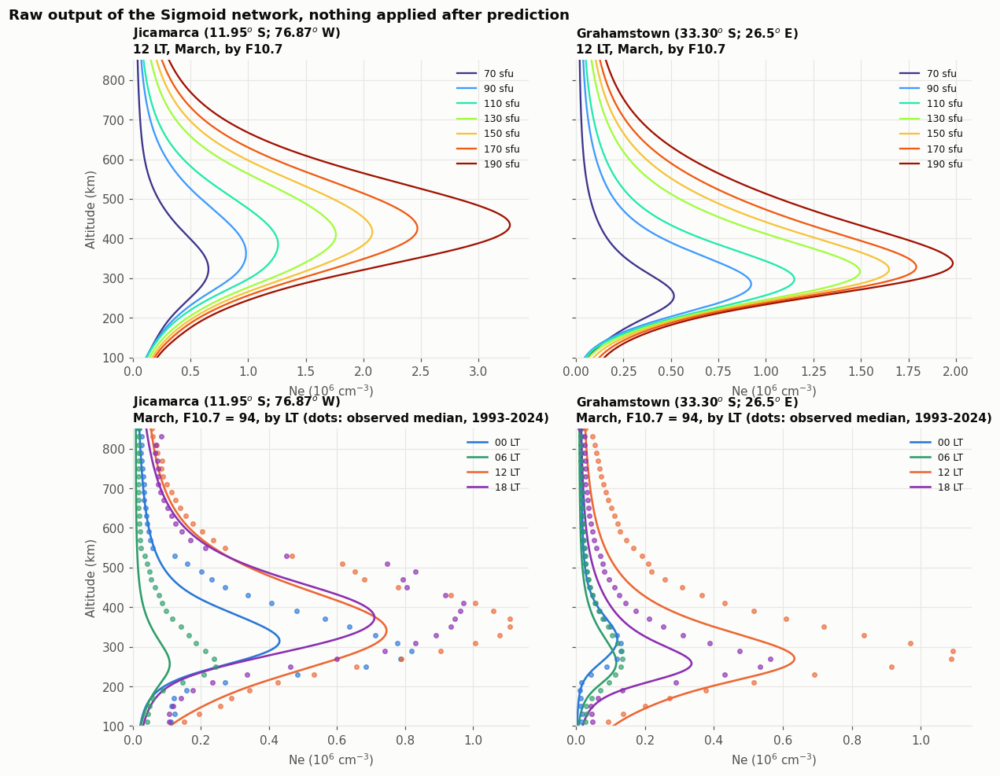

         model        site  profiles  pct_one_peak  max_curvature  median_curvature_sign_changes  max_curvature_sign_changes
           ANN   Jicamarca       120         100.0        0.00028                            2.0                           6
           ANN Grahamstown       120         100.0        0.00053                            2.0                           5
ANN no penalty   Jicamarca       120          95.0        0.00108                            4.0                          12
ANN no penalty Grahamstown       120         100.0        0.00157                            3.0                           7


In [20]:
tic('Two sites: raw Ne vs altitude')
AFine = np.arange(100.0, 851.0, 1.0); SITES2 = [("Jicamarca (11.95$^o$ S; 76.87$^o$ W)", -11.95, -76.87), ("Grahamstown (33.30$^o$ S; 26.5$^o$ E)", -33.3, 26.5)]; FL2 = [70, 90, 110, 130, 150, 170, 190]; LT2 = [0, 6, 12, 18]; C2 = plt.cm.turbo(np.linspace(.05, .95, len(FL2))); CL = [BLUE, GREEN, ORANGE, "#8c2fb0"]
def obs2(la, lo, lt0):
    s_ = [k for k, v in SB.items() if v[0] == la][0]; d_ = WB[(WB["site"] == s_) & (np.abs(WB["doy"] - 81) <= 20) & (np.minimum(np.abs(WB["lt"] - lt0), 24 - np.abs(WB["lt"] - lt0)) <= 1)]
    g_ = d_.groupby((d_["alt"] // 20) * 20 + 10)["ne"].agg(["median", "size"]); return g_[g_["size"] >= 10]
F2 = float(WB.loc[np.abs(WB["doy"] - 81) <= 20, "f107"].median()); D2 = season_drv(81, 60, 110)
fig, axs = plt.subplots(2, 2, figsize=(12.5, 10), sharey=True, gridspec_kw={"hspace": .24, "wspace": .12})
for r_, (sn, la, lo) in enumerate(SITES2):
    for f, c in zip(FL2, C2): axs[0, r_].plot(ne_model(81, 12.0, la, lo, AFine, -5.0, float(f)) / 1e6, AFine, color=c, lw=1.5, label=f"{f} sfu")
    axs[0, r_].set_title(f"{sn}\n12 LT, March, by F10.7", fontsize=10); axs[0, r_].legend(fontsize=8, loc="upper right")
    for lt_, c in zip(LT2, CL):
        axs[1, r_].plot(ne_model(81, float(lt_), la, lo, AFine, D2["symh"], F2, drv=D2) / 1e6, AFine, color=c, lw=1.7, label=f"{lt_:02d} LT"); o_ = obs2(la, lo, lt_)
        if len(o_): axs[1, r_].scatter(o_["median"] / 1e6, o_.index, s=13, color=c, alpha=.65, zorder=3)
    axs[1, r_].set_title(f"{sn}\nMarch, F10.7 = {F2:.0f}, by LT (dots: observed median, 1993-2024)", fontsize=10); axs[1, r_].legend(fontsize=8, loc="upper right")
for a in axs.ravel(): a.set_ylim(100, 850); a.set_xlim(left=0); a.set_xlabel("Ne (10$^6$ cm$^{-3}$)")
for a in axs[:, 0]: a.set_ylabel("Altitude (km)")
fig.suptitle(f"Raw output of the {ANN_RES[PLOTM]['act']} network, nothing applied after prediction", x=.01, ha="left", fontweight="bold", y=.94); save(fig, "two_sites_raw_model_profiles.png")
rows = []
for nm in PRED:
    for sn, la, lo in SITES2:
        Y = np.log10(np.array([ne_model(doy, float(lt), la, lo, AFine, -5.0, f, model=nm) for doy in (81, 172, 355) for lt in range(0, 24, 3) for f in (70., 100., 130., 160., 190.)]))
        d1, d2 = np.diff(Y, axis=1), np.diff(Y, 2, axis=1); core = (AFine[1:-1] >= 150) & (AFine[1:-1] <= 700); pk = ((d1[:, :-1] > 0) & (d1[:, 1:] <= 0) & core).sum(1); s2 = np.where(np.abs(d2) > 1e-6, np.sign(d2), 0); bends = [(np.diff(r[r != 0]) != 0).sum() for r in s2]
        rows.append(dict(model=nm, site=sn.split(" (")[0], profiles=len(Y), pct_one_peak=100 * float((pk == 1).mean()), max_curvature=float(np.abs(d2).max()), median_curvature_sign_changes=float(np.median(bends)), max_curvature_sign_changes=int(np.max(bends))))
TS = pd.DataFrame(rows); TS.round(6).to_csv(os.path.join(OUT, "two_sites_smoothness.csv"), index=False); print(TS.round(5).to_string(index=False))


## Fig 5 (analogue): profiles by 3-hour local time at the two sites, March. Paper: ISR radars. Here: observed GIRO and COSMIC from every row of 1993-2024 (red, median and 25-75%), ANN (blue), IRI (green), and the percentage difference

[ 12514s] Fig 5: profiles at two sites


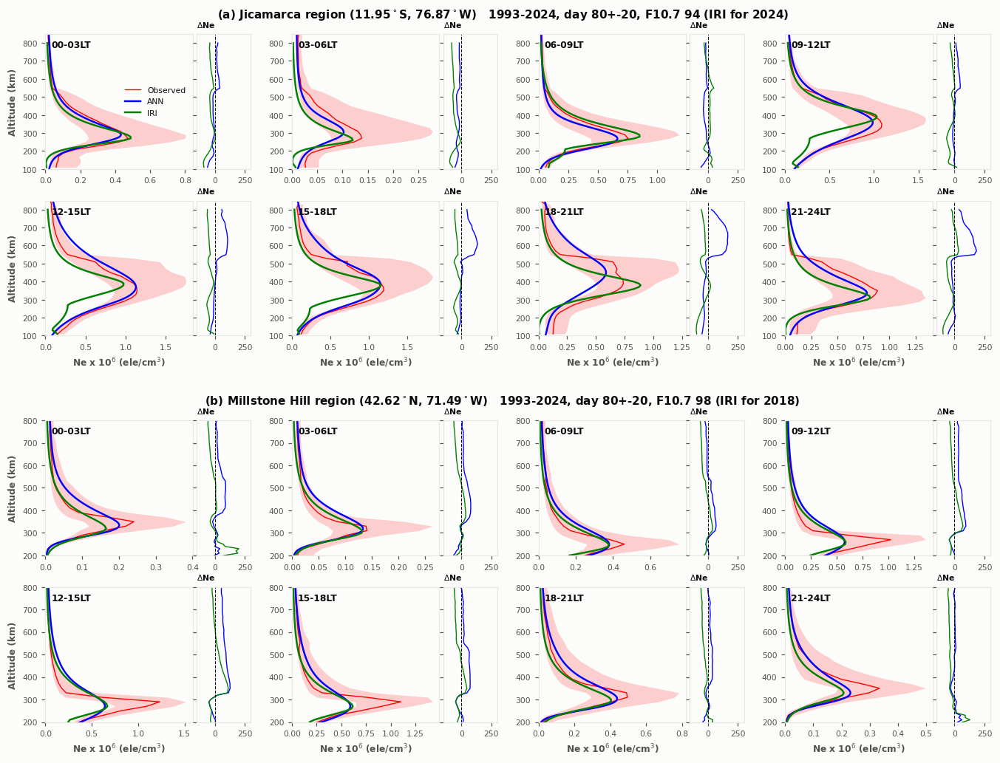

In [21]:
tic('Fig 5: profiles at two sites')
SITES5 = [("(a) Jicamarca region (11.95$^\\circ$S, 76.87$^\\circ$W)", -11.95, -76.87, 8, 12, (100, 850)), ("(b) Millstone Hill region (42.62$^\\circ$N, 71.49$^\\circ$W)", 42.62, -71.49, 6, 10, (200, 800))]
LTB = [(0, 3), (3, 6), (6, 9), (9, 12), (12, 15), (15, 18), (18, 21), (21, 24)]; ALT5 = np.arange(110, 801, 10.0); AL5 = np.arange(100, 851, 1.0)
fig = plt.figure(figsize=(15, 11)); gs = fig.add_gridspec(5, 4, height_ratios=[1, 1, .16, 1, 1], hspace=.28, wspace=.2); ROWS5 = [0, 1, 3, 4]
for si, (ttl, la, lo, dla, dlo, ylim) in enumerate(SITES5):
    B = WB[(WB["site"] == ["Jicamarca", "Millstone"][si]) & (np.abs(WB["doy"] - MAR_DOY) <= WINH) & WB["lat"].between(la - dla, la + dla) & WB["lon"].between(lo - dlo, lo + dlo)]
    if len(B) < 200: print("not enough rows near", ttl, len(B)); continue
    Y = int(B["year"].mode().iloc[0]); sy, ff = float(B["symh"].median()), float(B["f107"].median())
    for k, (a0, a1) in enumerate(LTB):
        sub_ = gs[ROWS5[2 * si + k // 4], k % 4].subgridspec(1, 2, width_ratios=[3, 1.1], wspace=.04); a = fig.add_subplot(sub_[0]); b = fig.add_subplot(sub_[1], sharey=a); lt_c = (a0 + a1) / 2
        o = B[B["lt"].between(a0, a1)]; g = o.groupby((o["alt"] // 20) * 20 + 10)["ne"]; q = g.quantile([.25, .5, .75]).unstack(); q["n"] = g.size(); q = q[q["n"] >= 10]
        pr = ne_model(MAR_DOY, lt_c, la, lo, AL5, sy, ff)
        try: iri = iri_cm3(Y, MAR_DOY, (lt_c - lo / 15.0) % 24, np.full(len(ALT5), lo), np.full(len(ALT5), la), ALT5, ff)
        except Exception as e: iri = np.full(len(ALT5), np.nan)
        if len(q): a.fill_betweenx(q.index, q[.25] / 1e6, q[.75] / 1e6, color="r", alpha=.18, lw=0); a.plot(q[.5] / 1e6, q.index, color="r", lw=.9, label="Observed")
        a.plot(pr / 1e6, AL5, color="b", lw=1.6, label="ANN"); a.plot(iri / 1e6, ALT5, color="g", lw=1.6, label="IRI")
        if len(q):
            ob = np.interp(ALT5, q.index, q[.5].values, left=np.nan, right=np.nan); b.plot(100 * (np.interp(ALT5, AL5, pr) - ob) / ob, ALT5, color="b", lw=.9); b.plot(100 * (iri - ob) / ob, ALT5, color="g", lw=.9)
        b.axvline(0, color="k", ls="--", lw=.7); b.set_xlim(-150, 300); b.tick_params(labelleft=False, labelsize=7); a.tick_params(labelsize=7); a.set_ylim(*ylim); a.set_xlim(left=0)
        a.text(.04, .9, f"{a0:02d}-{a1:02d}LT", transform=a.transAxes, fontweight="bold", fontsize=8); b.set_title("$\\Delta$Ne", fontsize=7, fontweight="bold")
        for q_ in (a, b):
            q_.grid(False)
            for s_ in ("top", "right"): q_.spines[s_].set_visible(True)
        if k % 4 == 0: a.set_ylabel("Altitude (km)", fontweight="bold", fontsize=8)
        if k // 4 == 1: a.set_xlabel("Ne x 10$^6$ (ele/cm$^3$)", fontsize=8, fontweight="bold")
        if si == 0 and k == 0: a.legend(fontsize=7, loc="center right")
    fig.text(.5, gs[[0, 3][si], 0].get_position(fig).y1 + .018, ttl + f"   1993-2024, day {MAR_DOY}+-{WINH}, F10.7 {ff:.0f} (IRI for {Y})", fontsize=10, fontweight="bold", ha="center")
save(fig, "paper_fig05_profiles_by_local_time.png")

## Fig 6 and 7 (analogue): noon maps at 580, 460 and 385 km and scatter plots. Paper: ROCSAT-1, SWARM-A, CHAMP in-situ. Here: COSMIC at the same altitudes in test year 2009 only (one year, so the map and the model share one solar flux)

[ 12531s] Fig 6 and 7: maps at three altitudes


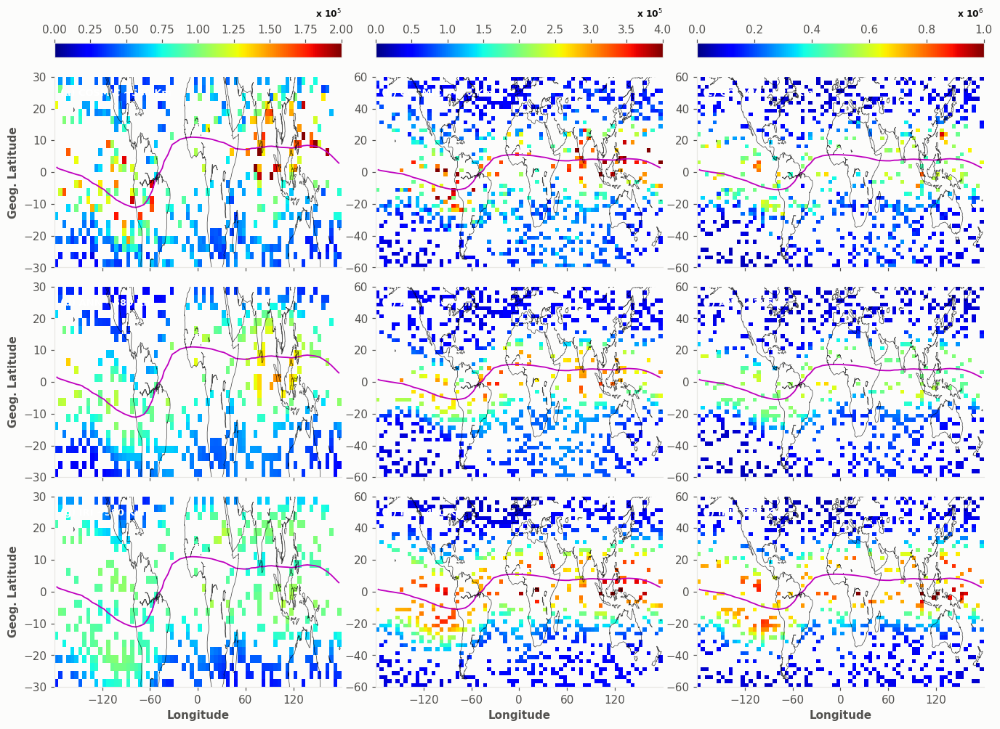

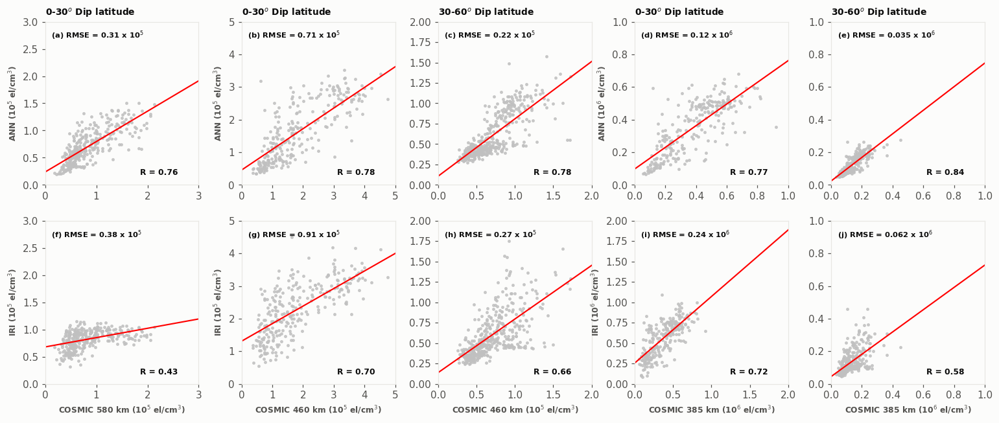

 alt diplat model     R       RMSE   n
 580   0-30   ANN 0.763  30669.337 316
 580   0-30   IRI 0.434  38477.414 316
 460   0-30   ANN 0.776  71054.970 271
 460   0-30   IRI 0.697  90524.698 271
 460  30-60   ANN 0.781  21731.181 414
 460  30-60   IRI 0.656  27072.427 414
 385   0-30   ANN 0.772 124141.376 242
 385   0-30   IRI 0.724 238155.227 242
 385  30-60   ANN 0.843  34677.317 353
 385  30-60   IRI 0.582  61607.707 353


In [22]:
tic('Fig 6 and 7: maps at three altitudes')
def bin_mean(lon, lat, v, lat_lim, dl=5.0, dp=2.5, nmin=3):
    xe, ye = np.arange(-180, 180 + dl, dl), np.arange(-lat_lim, lat_lim + dp, dp); s, _, _ = np.histogram2d(lon, lat, [xe, ye], weights=v); n, _, _ = np.histogram2d(lon, lat, [xe, ye])
    return xe[:-1] + dl / 2, ye[:-1] + dp / 2, np.where(n >= nmin, s / np.maximum(n, 1), np.nan).T
SL = [("ROCSAT-1 height ~580 km", 580, 30, 1e5), ("SWARM-A height ~460 km", 460, 60, 1e5), ("CHAMP height ~385 km", 385, 60, 1e6)]
FIG67_YEAR = 2009; ctr = DW[(DW["src"] >= 1) & DW["lt"].between(11, 13) & (DW["year"] == FIG67_YEAR)]; MAPS = []
fig, axs = plt.subplots(3, 3, figsize=(15, 10.5), gridspec_kw={"hspace": .1, "wspace": .12}); LET = "abcdefghi"
for j, (ttl, alt0, lim, un) in enumerate(SL):
    o = ctr[ctr["alt"].between(alt0 - 15, alt0 + 15)]
    if len(o) < 200: print(ttl, "only", len(o), "COSMIC rows, skipped"); MAPS.append(None); continue
    lon_c, lat_c, obs = bin_mean(o["lon"].values, o["lat"].values, o["ne"].values, lim); sy, ff, Y = float(o["symh"].median()), float(o["f107"].median()), int(o["year"].mode().iloc[0])
    ann = ne_model(MAR_DOY, 12.0, lat_c[:, None], lon_c[None, :], float(alt0), sy, ff); iri = np.full_like(ann, np.nan)
    try:
        for ii, lo_ in enumerate(lon_c): iri[:, ii] = iri_cm3(Y, MAR_DOY, (12.0 - lo_ / 15.0) % 24, np.full(len(lat_c), lo_), lat_c, np.full(len(lat_c), float(alt0)), ff)
    except Exception as e: print("IRI failed:", repr(e)[:100])
    dip = _gv[_tree.query(np.c_[np.repeat(lat_c, len(lon_c)), np.tile(lon_c, len(lat_c))])[1], 0].reshape(len(lat_c), len(lon_c)); MAPS.append((ttl, alt0, lon_c, lat_c, obs, ann, iri, dip, un))
    vmax = float(np.ceil(np.nanpercentile(obs / un, 97) * 1.05)) if np.isfinite(obs).any() else 10.0
    for i, (Z, nm) in enumerate([(obs, "COSMIC"), (ann, "ANN"), (iri, "IRI")]):
        a = axs[i, j]; a.grid(False); im = a.pcolormesh(lon_c, lat_c, (np.where(np.isfinite(obs), Z, np.nan) if i else Z) / un, cmap="jet", vmin=0, vmax=vmax, shading="auto"); a.contour(lon_c, lat_c, dip, [0.0], colors="m", linewidths=1.2); add_coast(a)
        a.text(.02, .9, f"({LET[3 * i + j]}) {nm} ~{alt0} Km", transform=a.transAxes, color="w", fontweight="bold", fontsize=8.5)
        a.set_xticks(range(-120, 121, 60)); a.set_xlim(-180, 180)
        if j == 0: a.set_ylabel("Geog. Latitude", fontweight="bold")
        if i == 2: a.set_xlabel("Longitude", fontweight="bold")
        else: a.set_xticklabels([])
        if i == 0: cb = fig.colorbar(im, ax=axs[:, j], location="top", fraction=.025, pad=.03); cb.ax.set_title(f"x 10$^{int(np.log10(un))}$", fontsize=8, loc="right")
save(fig, "paper_fig06_noon_maps_three_altitudes.png")
PANELS = [(0, "0-30", 0, 30), (1, "0-30", 0, 30), (1, "30-60", 30, 60), (2, "0-30", 0, 30), (2, "30-60", 30, 60)]; TOPT = ["ROCSAT-1 alt.", "SWARM-A alt.", "", "CHAMP alt.", ""]
fig, axs = plt.subplots(2, 5, figsize=(17, 6.6), gridspec_kw={"hspace": .22, "wspace": .28}); R7 = []; LET7 = "abcdefghij"
for k, (j, lab, d0, d1) in enumerate(PANELS):
    M_ = MAPS[j] if j < len(MAPS) else None
    if M_ is None: continue
    ttl, alt0, lon_c, lat_c, obs, ann, iri, dip, un = M_; sel = np.isfinite(obs) & (np.abs(dip) >= d0) & (np.abs(dip) < d1)
    for i, (Z, nm) in enumerate([(ann, "ANN"), (iri, "IRI")]):
        a = axs[i, k]; ok_ = sel & np.isfinite(Z); a.grid(False)
        if ok_.sum() < 10: a.text(.5, .5, "no data", transform=a.transAxes, ha="center"); continue
        x, y_ = obs[ok_] / un, Z[ok_] / un; r = np.corrcoef(x, y_)[0, 1]; rm_ = float(np.sqrt(np.mean((y_ - x) ** 2))); p = np.polyfit(x, y_, 1); lim = float(np.ceil(max(np.percentile(x, 99), np.percentile(y_, 99)) * 1.1))
        a.scatter(x, y_, s=5, color="#c0c0c0", alpha=.8); xs = np.array([0, lim]); a.plot(xs, np.polyval(p, xs), color="r", lw=1.4); a.set_xlim(0, lim); a.set_ylim(0, lim)
        a.text(.04, .9, f"({LET7[5 * i + k]}) RMSE = {rm_:.2g} x 10$^{int(np.log10(un))}$", transform=a.transAxes, fontsize=7.5, fontweight="bold"); a.text(.62, .06, f"R = {r:.2f}", transform=a.transAxes, fontsize=8, fontweight="bold")
        R7.append(dict(alt=alt0, diplat=lab, model=nm, R=r, RMSE=rm_ * un, n=int(ok_.sum())))
        if i == 0: a.set_title(f"{lab}$^o$ Dip latitude", fontsize=9, fontweight="bold")
        if k in (0, 1, 3): a.set_ylabel(f"{nm} (10$^{int(np.log10(un))}$ el/cm$^3$)", fontsize=8, fontweight="bold")
        if i == 1: a.set_xlabel(f"COSMIC {alt0} km (10$^{int(np.log10(un))}$ el/cm$^3$)", fontsize=8, fontweight="bold")
for ax_ in axs.ravel():
    for s_ in ("top", "right"): ax_.spines[s_].set_visible(True)
save(fig, "paper_fig07_scatter_vs_observation.png")
if R7: R7 = pd.DataFrame(R7); R7.round(3).to_csv(os.path.join(OUT, "metrics_paper_fig7_analogue.csv"), index=False); print(R7.round(3).to_string(index=False))

## Fig 8: latitude-altitude distribution of Ne every 3 LT, F10.7 = 120 sfu as in the paper, with each season's typical quiet-time Kp, Sym-H and CPCP (F10.7 100-140), 75E, for March, June and December

[ 12556s] Fig 8: lat-altitude maps


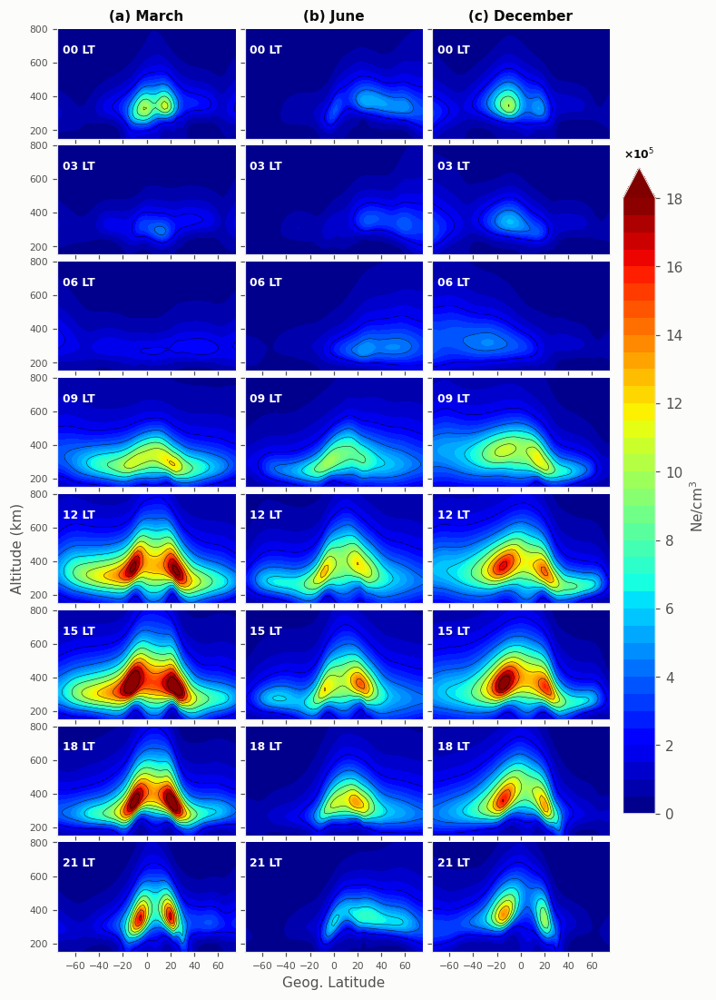

In [23]:
tic('Fig 8: lat-altitude maps')
LATG = np.arange(-75, 75.1, 2.5); ALT8 = np.arange(150, 801, 10.0); LTS = [0, 3, 6, 9, 12, 15, 18, 21]; levels = np.linspace(0, 18e5, 37)
fig, axs = plt.subplots(8, 3, figsize=(8.6, 12), sharex=True, sharey=True, gridspec_kw={"hspace": .06, "wspace": .05})
for j, (nm, doy) in enumerate([("(a) March", 80), ("(b) June", 172), ("(c) December", 355)]):
    D8 = season_drv(doy, 100, 140)
    for i, lt in enumerate(LTS):
        Z = ne_model(doy, lt, LATG[None, :], 75.0, ALT8[:, None], D8["symh"], 120.0, drv=D8); ax = axs[i, j]; ax.grid(False)
        cs = ax.contourf(LATG, ALT8, np.clip(Z, 0, 18e5), levels=levels, cmap="jet", extend="max"); ax.contour(LATG, ALT8, Z, levels=np.linspace(0, 18e5, 10), colors="k", linewidths=.3)
        ax.text(.03, .78, f"{lt:02d} LT", transform=ax.transAxes, color="w", fontweight="bold", fontsize=8); ax.set_yticks([200, 400, 600, 800]); ax.set_xticks(range(-60, 61, 20)); ax.tick_params(labelsize=7)
        if i == 0: ax.set_title(nm, fontsize=10, loc="center")
axs[-1, 1].set_xlabel("Geog. Latitude"); axs[4, 0].set_ylabel("Altitude (km)"); cb = fig.colorbar(cs, ax=axs, shrink=.7, pad=.02, ticks=np.arange(0, 19e5, 2e5)); cb.set_label("Ne/cm$^3$"); cb.ax.set_yticklabels([str(int(v / 1e5)) for v in np.arange(0, 19e5, 2e5)]); cb.ax.set_title("×10$^5$", fontsize=8)
save(fig, "paper_fig08_lat_altitude_maps.png")

## Altitude vs latitude from every row of 1993-2024: observed vs model on the same rows


[ 12569s] Altitude vs latitude: every row of 1993-2024, observed vs model


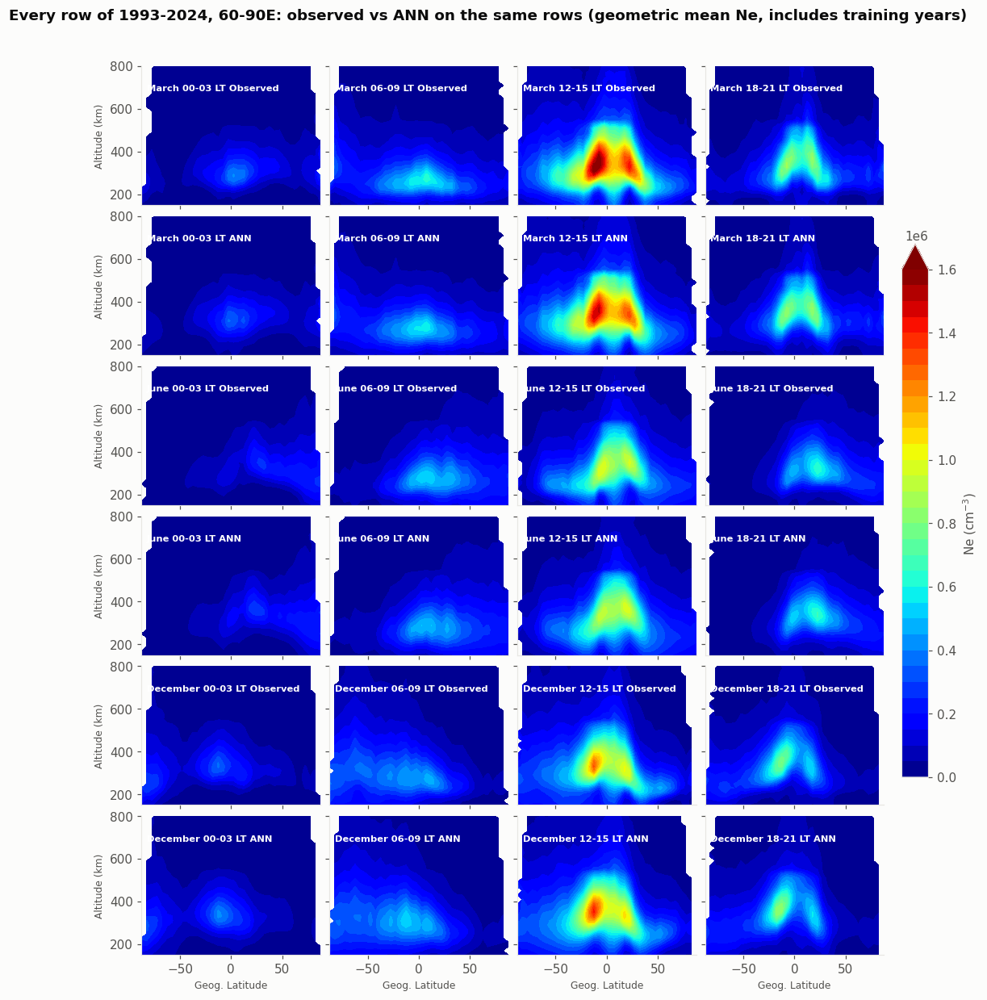

all_years_lat_alt_obs_vs_model_75E.png model peak / observed peak: {'March 00-03': 0.88, 'March 06-09': 0.93, 'March 12-15': 0.88, 'March 18-21': 0.99, 'June 00-03': 1.02, 'June 06-09': 0.93, 'June 12-15': 0.99, 'June 18-21': 1.02, 'December 00-03': 1.16, 'December 06-09': 1.15, 'December 12-15': 1.08, 'December 18-21': 1.05}


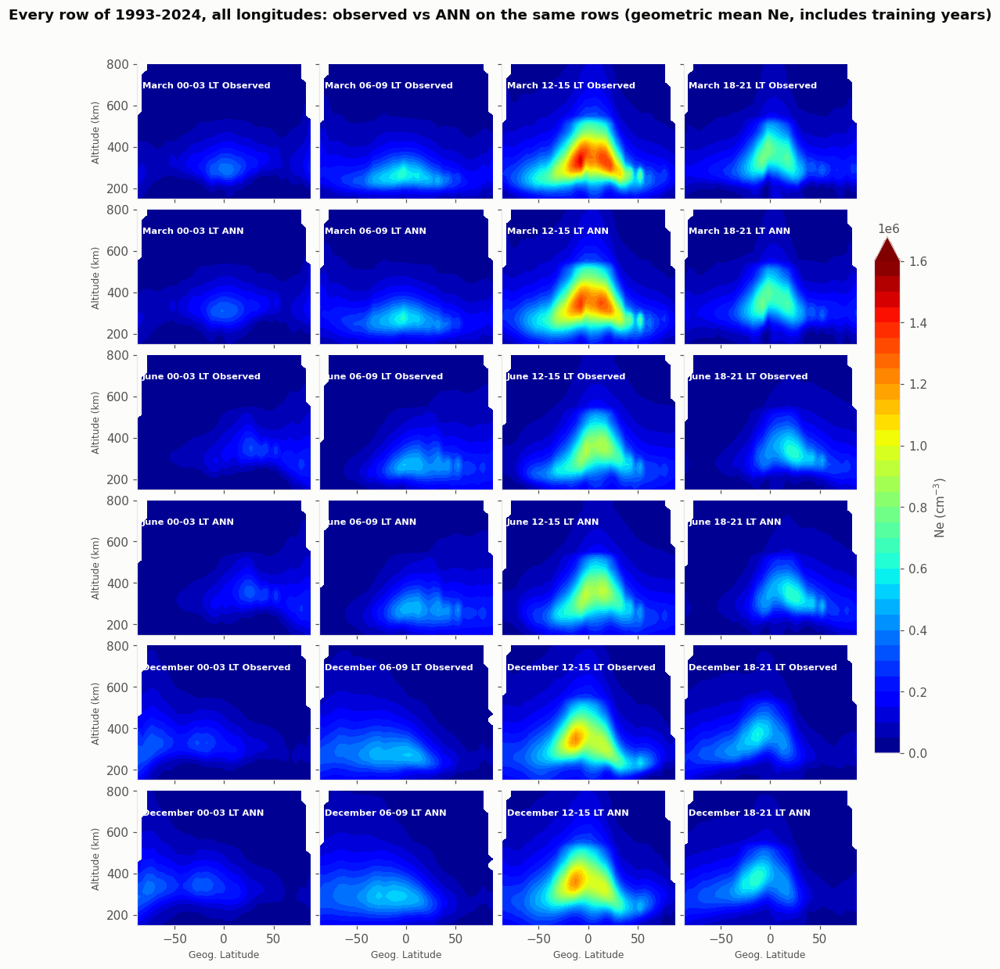

all_years_lat_alt_obs_vs_model_global.png model peak / observed peak: {'March 00-03': 0.92, 'March 06-09': 0.95, 'March 12-15': 0.92, 'March 18-21': 0.97, 'June 00-03': 1.07, 'June 06-09': 0.96, 'June 12-15': 1.03, 'June 18-21': 1.02, 'December 00-03': 1.07, 'December 06-09': 1.03, 'December 12-15': 1.0, 'December 18-21': 1.08}


In [24]:
tic('Altitude vs latitude: every row of 1993-2024, observed vs model')
_lc, _ac = -90 + 5 * np.arange(36) + 2.5, 100 + 20 * np.arange(40) + 10.0; LT8 = [(0, "00-03"), (2, "06-09"), (4, "12-15"), (6, "18-21")]
def lat_alt_fig(sc, name, ttl):
    fig, axs = plt.subplots(6, 4, figsize=(13, 13), sharex=True, sharey=True, gridspec_kw={"hspace": .08, "wspace": .05}); lv = np.linspace(0, 16e5, 33); rat = {}
    for s_i, (sn, _) in enumerate(SEAS[:3]):
        A = LA[s_i, sc]
        for c_, (il_, lab) in enumerate(LT8):
            n_ = A[il_, :, :, 0]; O_ = np.where(n_ >= 30, 10 ** (A[il_, :, :, 1] / np.maximum(n_, 1)), np.nan); M_ = np.where(n_ >= 30, 10 ** (A[il_, :, :, 2] / np.maximum(n_, 1)), np.nan); rat[(sn, lab)] = (np.nanmax(M_) / np.nanmax(O_)) if np.isfinite(O_).any() else np.nan
            for r_, (Z_, w_) in enumerate(((O_, "Observed"), (M_, "ANN"))):
                a = axs[2 * s_i + r_, c_]; a.grid(False); cs = a.contourf(_lc, _ac, np.clip(Z_, 0, 16e5).T, levels=lv, cmap="jet", extend="max"); a.set_ylim(150, 800); a.text(.03, .82, f"{sn} {lab} LT {w_}", transform=a.transAxes, color="w", fontweight="bold", fontsize=7.5)
    for a in axs[:, 0]: a.set_ylabel("Altitude (km)", fontsize=8)
    for a in axs[-1]: a.set_xlabel("Geog. Latitude", fontsize=8)
    cb = fig.colorbar(cs, ax=axs, shrink=.6, pad=.02); cb.set_label("Ne (cm$^{-3}$)"); fig.suptitle(ttl, x=.01, ha="left", fontweight="bold", y=.93); save(fig, name); print(name, "model peak / observed peak:", {f"{k[0]} {k[1]}": round(float(v), 2) for k, v in rat.items()})
lat_alt_fig(1, "all_years_lat_alt_obs_vs_model_75E.png", "Every row of 1993-2024, 60-90E: observed vs ANN on the same rows (geometric mean Ne, includes training years)")
lat_alt_fig(0, "all_years_lat_alt_obs_vs_model_global.png", "Every row of 1993-2024, all longitudes: observed vs ANN on the same rows (geometric mean Ne, includes training years)")


## Fig 9: main ionospheric trough, March equinox, 75E, every 2 LT

[ 12574s] 20g. Paper Fig 9: main ionospheric trough


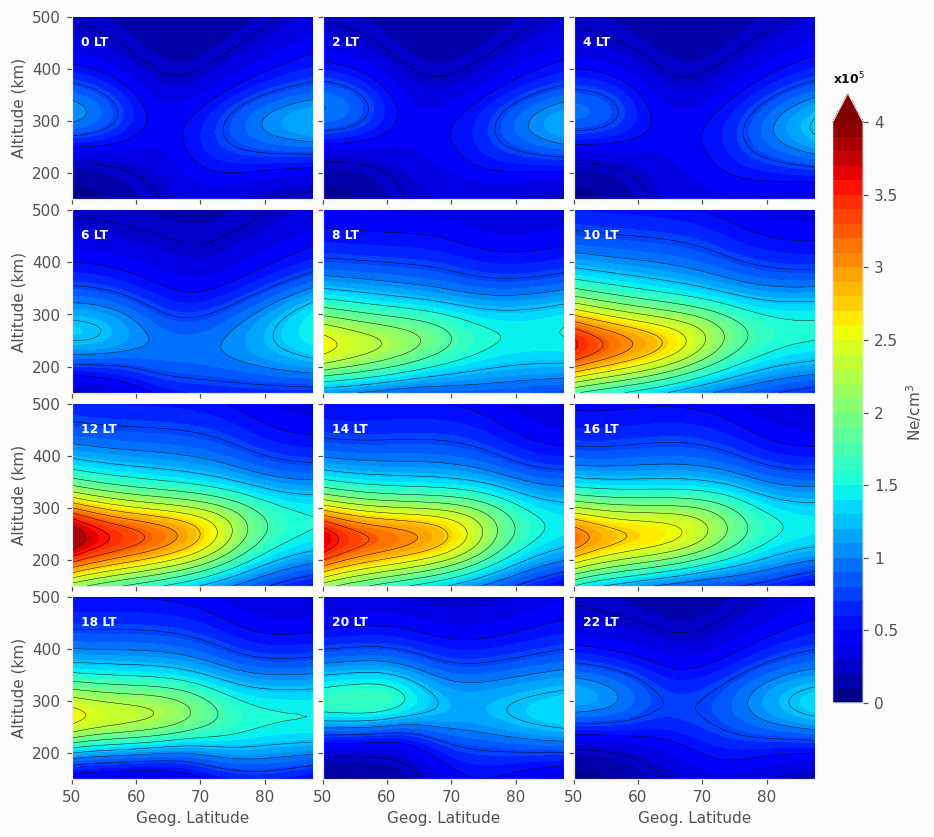


All paper-style figures done. Files p01..p09 and fig14/15/16 in ne_results_v6b


In [25]:
tic('20g. Paper Fig 9: main ionospheric trough')
LATT, ALTT = np.arange(50, 87.6, 0.5), np.arange(150, 501, 5.0); LT9 = list(range(0, 24, 2))
D9 = season_drv(MAR_DOY, 60, 110); fig, axs = plt.subplots(4, 3, figsize=(10.5, 9), sharex=True, sharey=True, gridspec_kw={"hspace": .06, "wspace": .04}); lv = np.linspace(0, 4e5, 41)
for a, lt in zip(axs.ravel(), LT9):
    Z = ne_model(MAR_DOY, float(lt), LATT[None, :], 75.0, ALTT[:, None], D9["symh"], 75.0, drv=D9); a.grid(False)
    cs = a.contourf(LATT, ALTT, np.clip(Z, 0, 4e5), levels=lv, cmap="jet", extend="max"); a.contour(LATT, ALTT, Z, levels=np.linspace(0, 4e5, 17), colors="k", linewidths=.3); a.text(.04, .84, f"{lt} LT", transform=a.transAxes, color="w", fontweight="bold", fontsize=8)
for a in axs[:, 0]: a.set_ylabel("Altitude (km)")
for a in axs[-1]: a.set_xlabel("Geog. Latitude")
cb = fig.colorbar(cs, ax=axs, shrink=.8, pad=.02, ticks=np.arange(0, 4.1e5, 5e4)); cb.set_label("Ne/cm$^3$"); cb.ax.set_yticklabels([f"{v/1e5:g}" for v in np.arange(0, 4.1e5, 5e4)]); cb.ax.set_title("x10$^5$", fontsize=8)
save(fig, "paper_fig09_main_trough.png")
print("\nAll paper-style figures done. Files p01..p09 and fig14/15/16 in", OUT)

## Fig 10: NmF2 and hmF2 at global local noon, quiet (Kp = 2) vs disturbed (Kp = 5), and the percentage change. NOT VALIDATED: model response only

[ 12580s] Fig 10: quiet vs disturbed world maps


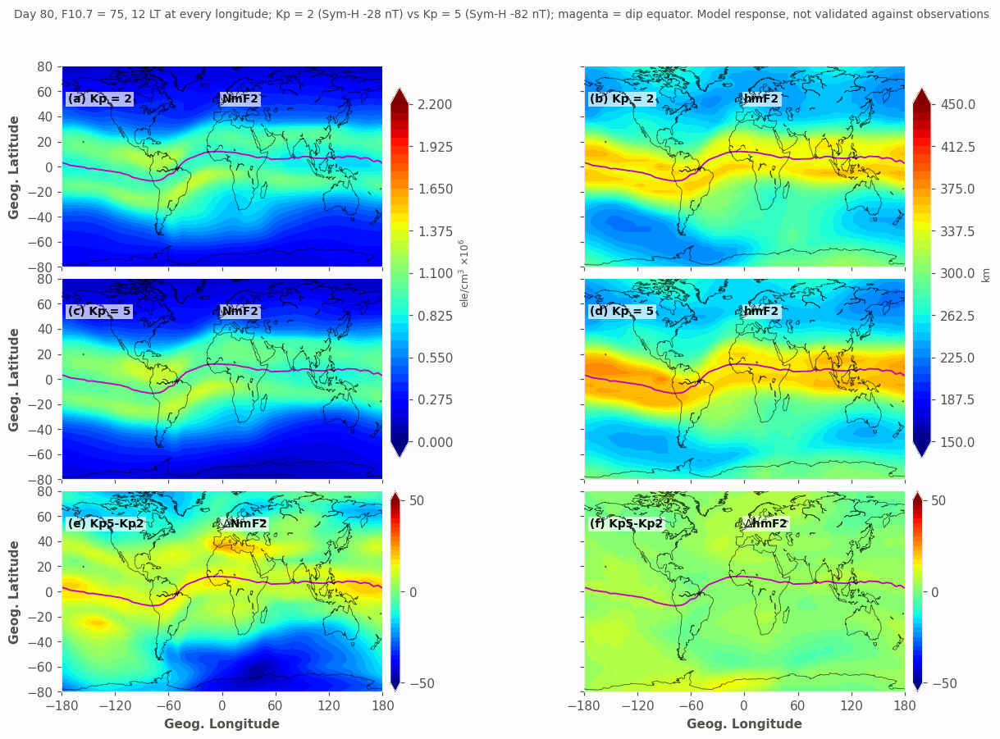


All paper figures done: paper_fig01 ... paper_fig10 in ne_results_v6b


In [26]:
tic('Fig 10: quiet vs disturbed world maps')
LON = np.arange(-180, 180.1, 5.0); LAT = np.arange(-80, 80.1, 5.0); ALT10 = np.arange(150, 701, 2.0); res = {}
KPQ, KPD = 2.0, 5.0; sym_of_kp = lambda k: -10.0 - 18.0 * (k - 1)
for tag, kp_ in [("quiet", KPQ), ("storm", KPD)]:
    Z = ne_model(MAR_DOY, 12.0, LAT[:, None, None], LON[None, :, None], ALT10[None, None, :], sym_of_kp(kp_), 75.0, kp_in=kp_); res[tag] = peaks(Z, ALT10)
dN = 100 * (res["storm"][0] - res["quiet"][0]) / res["quiet"][0]; dH = 100 * (res["storm"][1] - res["quiet"][1]) / res["quiet"][1]
DIPG = _gv[_tree.query(np.c_[np.repeat(LAT, len(LON)), np.tile(LON, len(LAT))])[1], 0].reshape(len(LAT), len(LON))
fig, axs = plt.subplots(3, 2, figsize=(13, 9), sharex=True, sharey=True, gridspec_kw={"hspace": .06, "wspace": .35})
PN = [(res["quiet"][0] / 1e6, f"(a) Kp = {KPQ:g}", "NmF2", 0, 2.2, 0, 0), (res["quiet"][1], f"(b) Kp = {KPQ:g}", "hmF2", 150, 450, 0, 1), (res["storm"][0] / 1e6, f"(c) Kp = {KPD:g}", "NmF2", 0, 2.2, 1, 0),
      (res["storm"][1], f"(d) Kp = {KPD:g}", "hmF2", 150, 450, 1, 1), (dN, f"(e) Kp{KPD:g}-Kp{KPQ:g}", "$\\Delta$NmF2", -50, 50, 2, 0), (dH, f"(f) Kp{KPD:g}-Kp{KPQ:g}", "$\\Delta$hmF2", -50, 50, 2, 1)]
IMS = {}
for Zp, t, name, v0, v1, r_, c_ in PN:
    a = axs[r_, c_]; a.grid(False); im = a.contourf(LON, LAT, np.clip(Zp, v0, v1), levels=np.linspace(v0, v1, 41), cmap="jet", extend="both"); a.contour(LON, LAT, DIPG, [0.0], colors="m", linewidths=1.2); add_coast(a); IMS[(r_, c_)] = im
    bb = dict(fc="w", alpha=.7, lw=0, pad=1.5); a.text(.02, .82, t, transform=a.transAxes, fontweight="bold", fontsize=9, bbox=bb); a.text(.5, .82, name, transform=a.transAxes, fontweight="bold", fontsize=9, bbox=bb)
    a.set_xticks(range(-180, 181, 60)); a.set_yticks(range(-80, 81, 20))
for a in axs[:, 0]: a.set_ylabel("Geog. Latitude", fontweight="bold")
for a in axs[-1]: a.set_xlabel("Geog. Longitude", fontweight="bold")
cb = fig.colorbar(IMS[(0, 0)], ax=[axs[0, 0], axs[1, 0]], pad=.02, shrink=.9); cb.set_label("ele/cm$^3$ $\\times 10^6$", fontsize=8); fig.colorbar(IMS[(2, 0)], ax=axs[2, 0], pad=.02, ticks=[-50, 0, 50])
cb = fig.colorbar(IMS[(0, 1)], ax=[axs[0, 1], axs[1, 1]], pad=.02, shrink=.9); cb.set_label("km", fontsize=8); fig.colorbar(IMS[(2, 1)], ax=axs[2, 1], pad=.02, ticks=[-50, 0, 50])
fig.text(.5, .94, f"Day {MAR_DOY}, F10.7 = 75, 12 LT at every longitude; Kp = {KPQ:g} (Sym-H {sym_of_kp(KPQ):.0f} nT) vs Kp = {KPD:g} (Sym-H {sym_of_kp(KPD):.0f} nT); magenta = dip equator. Model response, not validated against observations", ha="center", fontsize=9, color=INK2)
save(fig, "paper_fig10_nmf2_hmf2_quiet_vs_storm.png")
print("\nAll paper figures done: paper_fig01 ... paper_fig10 in", OUT)

# APPENDIX: extra diagnostics (not in the paper)
Bar charts, scatter plots, error tables, activation comparison, solar-maximum holdout, topside / bottomside test, and physics sanity checks.

## 5. Fig 1: model comparison

[ 12583s] 5. Fig 1: model comparison


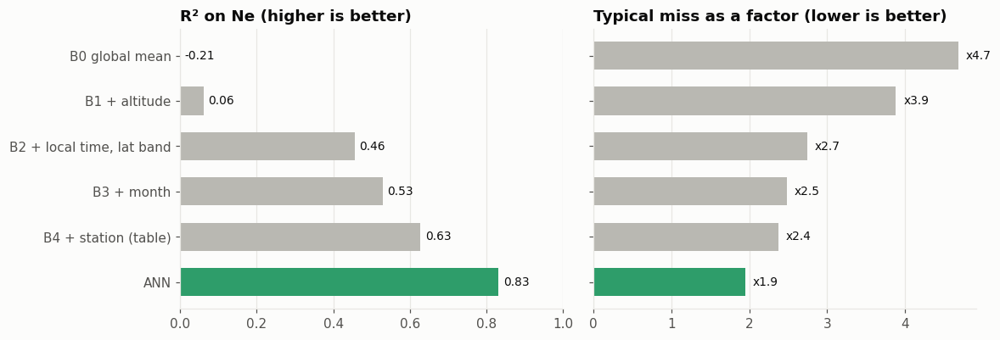

In [27]:
tic('5. Fig 1: model comparison')
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True, gridspec_kw={"wspace": 0.08}); names = list(M.index); yp = np.arange(len(names))[::-1]
cl = [MC.get(n, GRAY) for n in names]
a.barh(yp, M["R2_linear_Ne"].clip(lower=0), color=cl, height=0.62); b.barh(yp, M["typical_factor"], color=cl, height=0.62)
for y_, v, f in zip(yp, M["R2_linear_Ne"], M["typical_factor"]): a.text(max(v, 0) + 0.012, y_, f"{v:.2f}", va="center", fontsize=9); b.text(f + 0.1, y_, f"x{f:.1f}", va="center", fontsize=9)
a.set_yticks(yp); a.set_yticklabels(names); a.set_xlim(0, 1); a.grid(axis="y", visible=False); b.grid(axis="y", visible=False)
a.set_title("R² on Ne (higher is better)"); b.set_title("Typical miss as a factor (lower is better)"); save(fig, "fig1_model_comparison.png")

## 6. Fig 2: predicted vs observed (axes are Ne as powers of ten)

[ 12583s] 6. Fig 2: predicted vs observed Ne


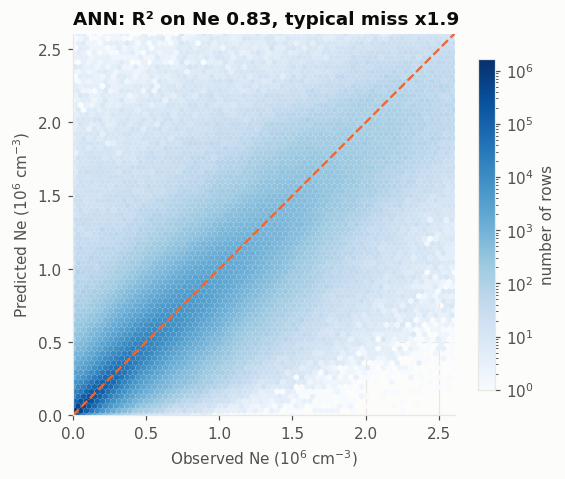

In [28]:
tic('6. Fig 2: predicted vs observed Ne')
fig, axs = plt.subplots(1, len(MODELS), figsize=(5.6 * len(MODELS), 5.2), squeeze=False)
for ax, m in zip(axs[0], MODELS):
    _x, _y = 10 ** np.asarray(yte) / 1e6, 10 ** te["p_" + m].values / 1e6; hi = float(np.percentile(_x, 99.9)); hb = ax.hexbin(_x, _y, gridsize=70, bins="log", mincnt=1, cmap="Blues", linewidths=0, extent=(0, hi, 0, hi)); ax.plot([0, hi], [0, hi], "--", color=ORANGE, lw=1.5); ax.set_xlim(0, hi); ax.set_ylim(0, hi)
    ax.set_aspect("equal"); ax.set_xlabel("Observed Ne (10$^6$ cm$^{-3}$)"); ax.set_ylabel("Predicted Ne (10$^6$ cm$^{-3}$)")
    ax.set_title(f"{m}: R² on Ne {r2(10 ** np.asarray(yte), 10 ** te['p_' + m].values):.2f}, typical miss x{10**rmse(yte, te['p_' + m].values):.1f}"); fig.colorbar(hb, ax=ax, shrink=0.75, label="number of rows")
save(fig, "fig2_pred_vs_obs.png")

## 7. Fig 3: Ne vs altitude, observed vs models, day and night

[ 12586s] 7. Fig 3: Ne vs altitude, observed vs model, day and night, all years


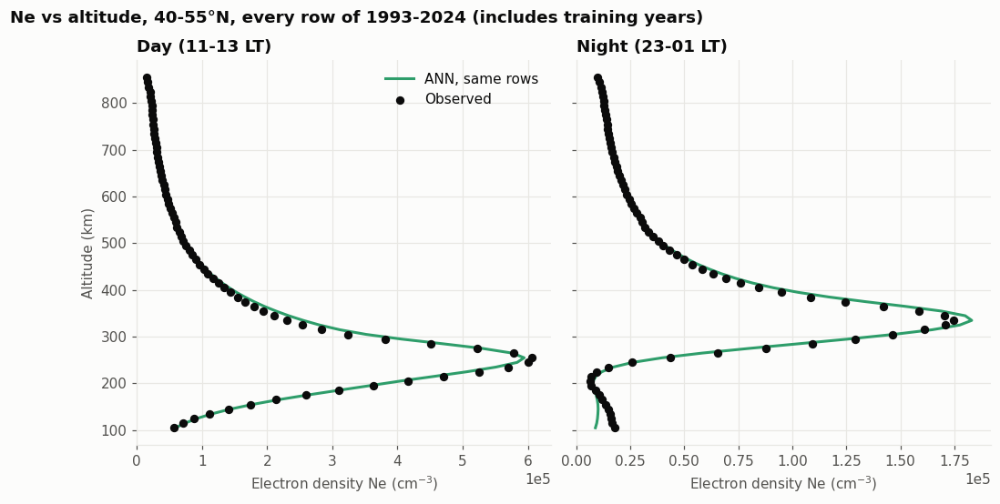

In [29]:
tic('7. Fig 3: Ne vs altitude, observed vs model, day and night, all years')
ALT10B = 100 + 10 * np.arange(80) + 5.0; MC_ = MC["ANN"]
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"wspace": 0.06})
for dn_, (ax, ttl) in enumerate(zip(axs, ["Day (11-13 LT)", "Night (23-01 LT)"])):
    n_, s_, p_ = [MID[dn_, 0, :, j_] for j_ in range(3)]; k_ = n_ >= 200; ax.plot(10 ** (p_[k_] / n_[k_]), ALT10B[k_], color=MC_, lw=2, label="ANN, same rows"); ax.scatter(10 ** (s_[k_] / n_[k_]), ALT10B[k_], s=26, color=INK, zorder=3, label="Observed")
    ax.set_xlim(left=0); ax.ticklabel_format(axis="x", style="sci", scilimits=(5, 5)); ax.set_title(ttl); ax.set_xlabel("Electron density Ne (cm$^{-3}$)")
axs[0].set_ylabel("Altitude (km)"); axs[0].legend(loc="upper right"); fig.suptitle("Ne vs altitude, 40-55°N, every row of 1993-2024 (includes training years)", x=0.01, ha="left", fontweight="bold"); save(fig, "fig3_ne_vs_altitude.png")


## 7b. Error by source in the test years

[ 12587s] 7b. Error by source in the test years


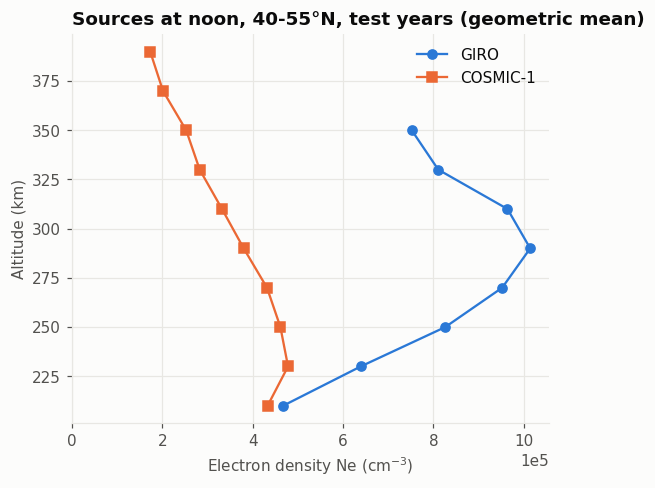

typical Ne error (factor) by source, test years:
  source       n   ANN
    GIRO 6095270 2.245
COSMIC-1 3990888 1.523
COSMIC-2 1996082 1.779


In [30]:
tic('7b. Error by source in the test years')
ov = te[te["alt"].between(200, 400) & te["lat"].between(40, 55) & te["lt"].between(11, 13)]
g = ov.assign(ab=(ov["alt"] // 20) * 20 + 10).groupby(["ab", "src"])["y"].agg(["mean", "size"]).unstack("src")
if g.shape[1] >= 4:
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    for s_, c_, mk in ((0, BLUE, "o-"), (1, ORANGE, "s-"), (2, GREEN, "^-")):
        if ("mean", s_) in g.columns: k_ = (g[("size", s_)] >= 50).values; ax.plot(10 ** g[("mean", s_)].values[k_], g.index.values[k_], mk, color=c_, label=SRC_NAME[s_])
    ax.set_xlim(left=0); ax.ticklabel_format(axis="x", style="sci", scilimits=(5, 5)); ax.set_xlabel("Electron density Ne (cm$^{-3}$)"); ax.set_ylabel("Altitude (km)"); ax.legend(); ax.set_title("Sources at noon, 40-55°N, test years (geometric mean)"); save(fig, "fig3b_source_overlap.png")
SRC = pd.DataFrame([dict(source=SRC_NAME[int(s_)], n=len(g), **{m: 10 ** rmse(g["y"].values, g["p_" + m].values) for m in MODELS}) for s_, g in te.groupby("src")]); SRC.round(3).to_csv(os.path.join(OUT, "metrics_by_source.csv")); print("typical Ne error (factor) by source, test years:"); print(SRC.round(3).to_string(index=False))


## 8. Fig 4: error by altitude, day and night

[ 12589s] 8. Fig 4: error by altitude, day and night


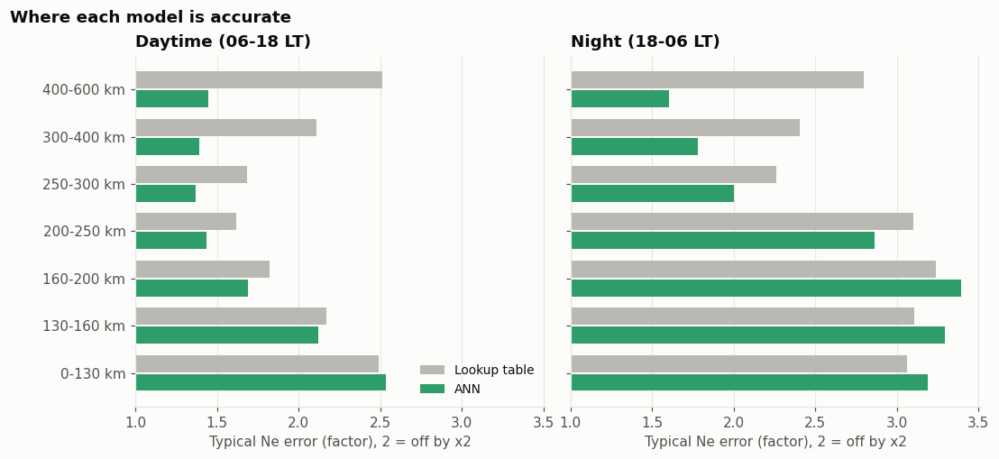

In [31]:
tic('8. Fig 4: error by altitude, day and night')
bands = list(dict.fromkeys(S["altband"])); fig, axs = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, sharex=True, gridspec_kw={"wspace": 0.06}); yy = np.arange(len(bands))
k = len(MODELS) + 1; h = 0.8 / k
for ax, dn in zip(axs, ["day", "night"]):
    d = S[S["dn"] == dn].set_index("altband").reindex(bands)
    ax.barh(yy + h * (k - 1) / 2, 10 ** d["RMSE_table"] - 1, left=1, height=h * 0.9, color=GRAY, label="Lookup table")
    for i, m in enumerate(MODELS): ax.barh(yy + h * (k - 1) / 2 - h * (i + 1), 10 ** d["RMSE_" + m] - 1, left=1, height=h * 0.9, color=MC[m], label=m)
    ax.set_title("Daytime (06-18 LT)" if dn == "day" else "Night (18-06 LT)"); ax.set_xlabel("Typical Ne error (factor), 2 = off by x2"); ax.grid(axis="y", visible=False)
axs[0].set_yticks(yy); axs[0].set_yticklabels([b.replace("(", "").replace("]", "").replace(", ", "-") + " km" for b in bands]); axs[0].legend(loc="lower right", fontsize=9)
fig.suptitle("Where each model is accurate", x=0.01, ha="left", fontweight="bold"); save(fig, "fig4_error_by_altitude.png")

## 9. Fig 5: Ne vs altitude for different F10.7 (observed dots, best model lines)

[ 12590s] 9. Fig 5: Ne vs altitude for different F10.7, all years


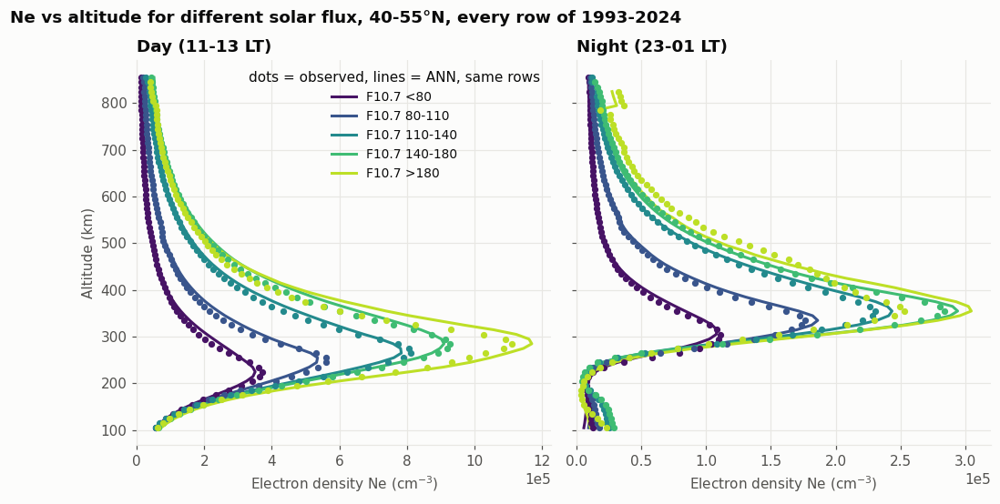

In [32]:
tic('9. Fig 5: Ne vs altitude for different F10.7, all years')
fl = ["<80", "80-110", "110-140", "140-180", ">180"]; cl5 = cm.viridis(np.linspace(0.05, 0.9, 5))
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharey=True, gridspec_kw={"wspace": 0.06})
for dn_, (ax, ttl) in enumerate(zip(axs, ["Day (11-13 LT)", "Night (23-01 LT)"])):
    for b_, (lab, c) in enumerate(zip(fl, cl5)):
        n_, s_, p_ = [MID[dn_, b_ + 1, :, j_] for j_ in range(3)]; k_ = n_ >= 100
        if k_.any(): ax.plot(10 ** (p_[k_] / n_[k_]), ALT10B[k_], color=c, lw=2, label=f"F10.7 {lab}"); ax.scatter(10 ** (s_[k_] / n_[k_]), ALT10B[k_], s=14, color=c, zorder=3)
    ax.set_xlim(left=0); ax.ticklabel_format(axis="x", style="sci", scilimits=(5, 5)); ax.set_title(ttl); ax.set_xlabel("Electron density Ne (cm$^{-3}$)")
axs[0].set_ylabel("Altitude (km)"); axs[0].legend(title="dots = observed, lines = ANN, same rows", loc="upper right", fontsize=9)
fig.suptitle("Ne vs altitude for different solar flux, 40-55°N, every row of 1993-2024", x=0.01, ha="left", fontweight="bold"); save(fig, "fig5_ne_vs_altitude_by_f107.png")


## 10. Fig 6: Ne vs F10.7 by altitude (midday)

[ 12591s] 10. Fig 6: Ne vs F10.7 by altitude (midday)


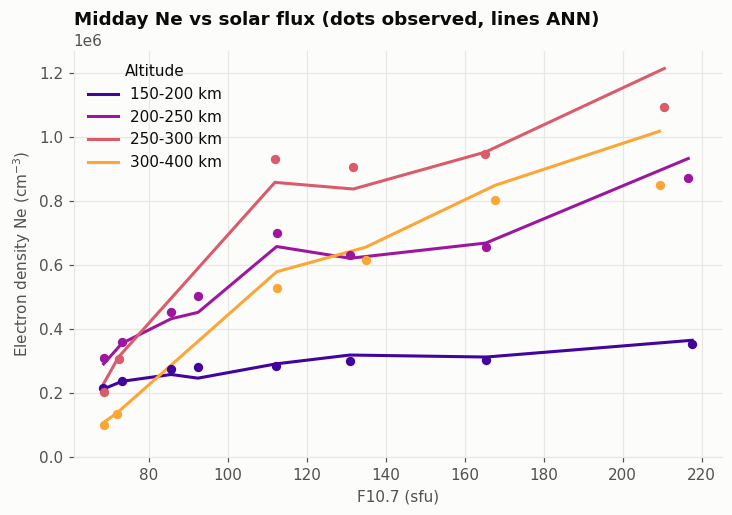

In [33]:
tic('10. Fig 6: Ne vs F10.7 by altitude (midday)')
noon = te[te["lat"].between(40, 55) & te["lt"].between(11, 13)]; fedges = [60, 70, 80, 90, 100, 120, 150, 200, 400]
fig, ax = plt.subplots(figsize=(7.6, 4.8))
for (lo_, hi_), c in zip([(150, 200), (200, 250), (250, 300), (300, 400)], cm.plasma(np.linspace(0.1, 0.8, 4))):
    d = noon[noon["alt"].between(lo_, hi_)]; g = d.groupby(pd.cut(d["f107"], fedges), observed=True).agg(f=("f107", "mean"), y=("y", "mean"), p=("p_" + BEST, "mean"), n=("y", "size")); g = g[g["n"] >= 200]
    ax.plot(g["f"], 10 ** g["p"], color=c, lw=2, label=f"{lo_}-{hi_} km"); ax.scatter(g["f"], 10 ** g["y"], s=26, color=c, zorder=3)
ax.set_ylim(bottom=0); ax.set_xlabel("F10.7 (sfu)"); ax.set_ylabel("Electron density Ne (cm$^{-3}$)"); ax.set_title(f"Midday Ne vs solar flux (dots observed, lines {BEST})"); ax.legend(title="Altitude"); save(fig, "fig6_ne_vs_f107.png")

## 11. Fig 7: daily cycle near 300 km, winter vs summer

[ 12591s] 11. Fig 7: daily cycle near 300 km, winter vs summer


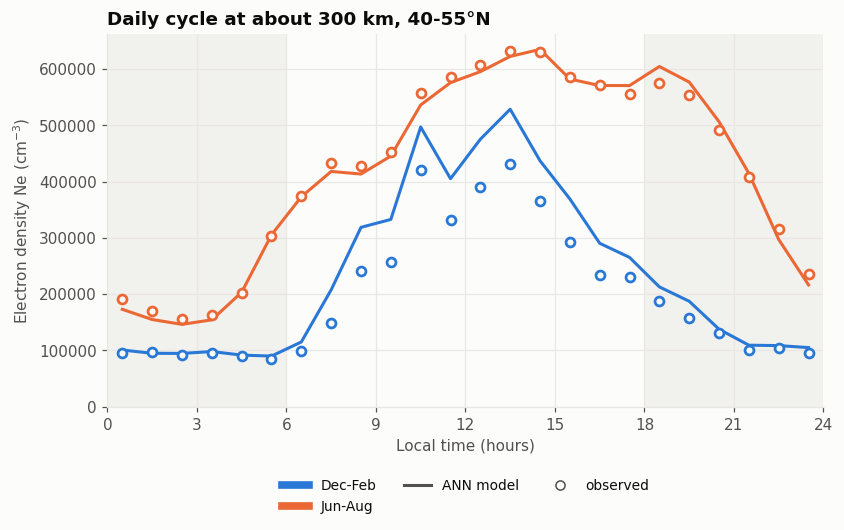

In [34]:
tic('11. Fig 7: daily cycle near 300 km, winter vs summer')
sel = te[te["alt"].between(280, 320) & te["lat"].between(40, 55)].copy(); sel["season"] = np.where(sel["month"].isin([12, 1, 2]), "Dec-Feb", np.where(sel["month"].isin([6, 7, 8]), "Jun-Aug", "x"))
fig, ax = plt.subplots(figsize=(8.4, 4.4)); ax.axvspan(0, 6, color=GRID, alpha=.5, lw=0); ax.axvspan(18, 24, color=GRID, alpha=.5, lw=0)
for sea, c in [("Dec-Feb", BLUE), ("Jun-Aug", ORANGE)]:
    s = sel[sel["season"] == sea]; g = s.groupby(s["lt"].astype(int).clip(0, 23)).agg(y=("y", "mean"), n=("y", "size"), **{m: ("p_" + m, "mean") for m in MODELS}); g = g[g["n"] >= 100]
    if len(g) == 0: continue
    ax.scatter(g.index + .5, 10 ** g["y"], s=34, facecolor=SURF, edgecolor=c, linewidth=1.8, zorder=3)
    for m, ls in zip(MODELS, ["-", "--"]): ax.plot(g.index + .5, 10 ** g[m], color=c, lw=2, ls=ls)
ax.set_ylim(bottom=0); ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xlabel("Local time (hours)"); ax.set_ylabel("Electron density Ne (cm$^{-3}$)")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], color=BLUE, lw=5, label="Dec-Feb"), Line2D([], [], color=ORANGE, lw=5, label="Jun-Aug"), Line2D([], [], color=INK2, lw=2, label="ANN model")] + [Line2D([], [], color=INK2, marker="o", mfc=SURF, ls="", label="observed")], ncol=3, loc="upper center", bbox_to_anchor=(.5, -.16), fontsize=9)
ax.set_title("Daily cycle at about 300 km, 40-55°N"); save(fig, "fig7_diurnal.png")

## 12. Fig 8: storm response (predicted / observed ratio, 1 = unbiased)

[ 12592s] 12. Fig 8: storm response (predicted / observed ratio, 1 = u


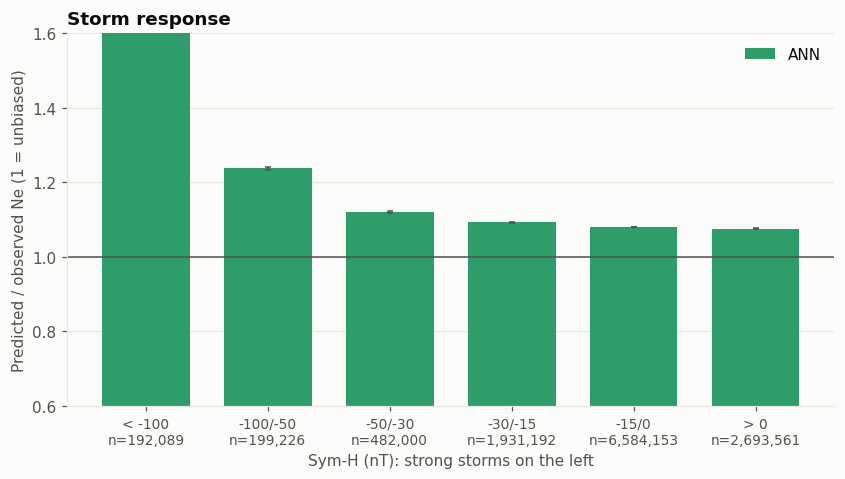

In [35]:
tic('12. Fig 8: storm response (predicted / observed ratio, 1 = u')
te["sb"] = pd.cut(te["symh"], [-1000, -100, -50, -30, -15, 0, 60], labels=["< -100", "-100/-50", "-50/-30", "-30/-15", "-15/0", "> 0"])
fig, ax = plt.subplots(figsize=(9, 4.4)); ax.axhline(1, color=INK2, lw=1); xs = np.arange(6); w = .8 / len(MODELS)
for i, m in enumerate(MODELS):
    e = (te["p_" + m] - te["y"]).groupby(te["sb"], observed=False); mean, se, n = e.mean(), e.std() / np.sqrt(e.size()), e.size()
    ax.bar(xs + (i - (len(MODELS) - 1) / 2) * w, 10 ** mean, width=w * .9, color=MC[m], label=m, yerr=[10 ** mean - 10 ** (mean - 1.96 * se), 10 ** (mean + 1.96 * se) - 10 ** mean], error_kw=dict(ecolor=INK2, lw=1, capsize=2))
ax.set_xticks(xs); ax.set_xticklabels([f"{l}\nn={int(n_):,}" for l, n_ in zip(n.index, n.values)], fontsize=9); ax.set_ylim(.6, 1.6); ax.grid(axis="x", visible=False)
ax.set_xlabel("Sym-H (nT): strong storms on the left"); ax.set_ylabel("Predicted / observed Ne (1 = unbiased)"); ax.legend(); ax.set_title("Storm response"); save(fig, "fig8_storm_bias.png")

## 13. Fig 9: R2 by month and by F10.7

[ 12593s] 13. Fig 9: R2 by month and by F10.7


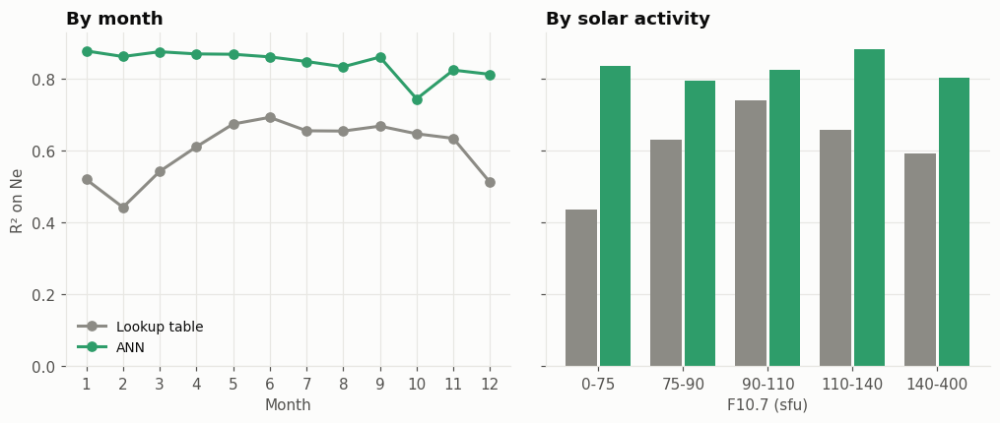

In [36]:
tic('13. Fig 9: R2 by month and by F10.7')
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4), sharey=True, gridspec_kw={"wspace": .08})
mo = te.groupby("month").apply(lambda g: pd.Series({"table": r2(10 ** g["y"].values, 10 ** g["B4"].values), **{m: r2(10 ** g["y"].values, 10 ** g["p_" + m].values) for m in MODELS}}))
a.plot(mo.index, mo["table"], "o-", color=DGRAY, lw=2, label="Lookup table")
for m in MODELS: a.plot(mo.index, mo[m], "o-", color=MC[m], lw=2, label=m)
a.set_xticks(range(1, 13)); a.set_xlabel("Month"); a.set_ylabel("R² on Ne"); a.set_title("By month"); a.legend(loc="lower left", fontsize=9)
te["fc"] = pd.cut(te["f107"], [0, 75, 90, 110, 140, 400]); fo = te.groupby("fc", observed=True).apply(lambda g: pd.Series({"table": r2(10 ** g["y"].values, 10 ** g["B4"].values), **{m: r2(10 ** g["y"].values, 10 ** g["p_" + m].values) for m in MODELS}}))
x = np.arange(len(fo)); kk = len(MODELS) + 1; ww = .8 / kk
b.bar(x - .4 + ww / 2, fo["table"], ww * .92, color=DGRAY)
for i, m in enumerate(MODELS): b.bar(x - .4 + ww / 2 + ww * (i + 1), fo[m], ww * .92, color=MC[m])
b.set_xticks(x); b.set_xticklabels([f"{int(i.left)}-{int(i.right)}" for i in fo.index]); b.set_xlabel("F10.7 (sfu)"); b.set_title("By solar activity"); b.grid(axis="x", visible=False); save(fig, "fig9_month_f107.png")

## 14. Fig 10: lat-altitude section at noon, observed vs best model

[ 12599s] 14. Fig 10: lat-altitude section at noon, observed vs model, all years


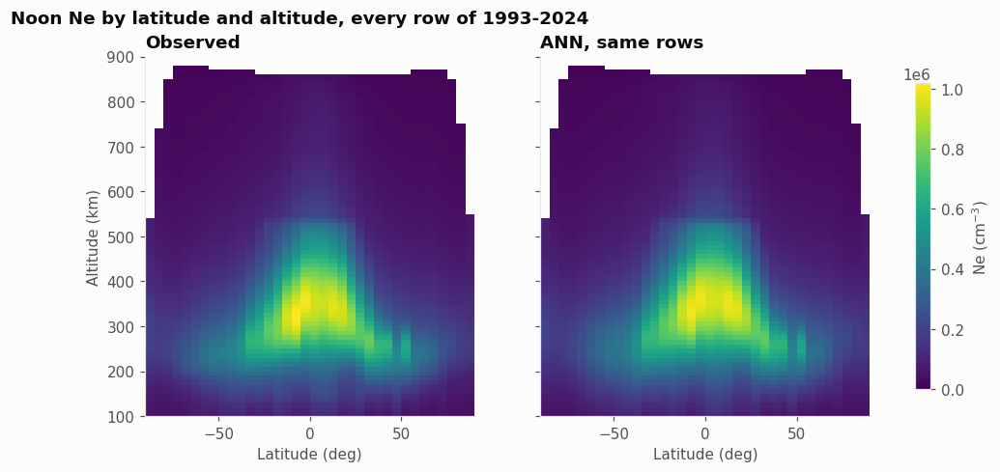

In [37]:
tic('14. Fig 10: lat-altitude section at noon, observed vs model, all years')
_lb = -90 + 5 * np.arange(36) + 2.5; fig, axs = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True); n_ = NOON[..., 0]; Y_ = np.where(n_ >= 50, NOON[..., 1] / np.maximum(n_, 1), np.nan); P_ = np.where(n_ >= 50, NOON[..., 2] / np.maximum(n_, 1), np.nan); Y_, P_ = 10 ** Y_, 10 ** P_; vmin, vmax = 0, np.nanmax([Y_, P_])
for ax, Z_, t in zip(axs, [Y_, P_], ["Observed", "ANN, same rows"]):
    sc = ax.pcolormesh(_lb, ALT10B, Z_.T, cmap="viridis", vmin=vmin, vmax=vmax, shading="auto"); ax.set_title(t); ax.set_xlabel("Latitude (deg)"); ax.grid(False)
axs[0].set_ylabel("Altitude (km)"); cb = fig.colorbar(sc, ax=axs, shrink=.85, label="Ne (cm$^{-3}$)")
fig.suptitle("Noon Ne by latitude and altitude, every row of 1993-2024", x=0.01, ha="left", fontweight="bold"); save(fig, "fig10_lat_altitude.png")


## 15. Fig 11: ANN training curve

[ 12600s] 15. Fig 11: ANN training curve


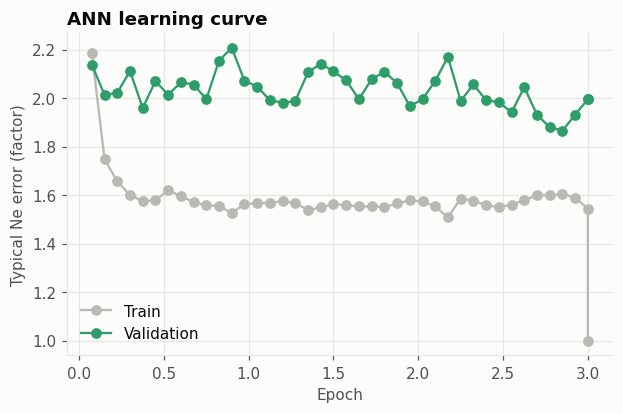

In [38]:
tic('15. Fig 11: ANN training curve')
if ann_hist:
    h = np.array(ann_hist); fig, ax = plt.subplots(figsize=(6.4, 3.8)); ax.plot(h[:, 0], 10 ** h[:, 1], "o-", color=GRAY, label="Train"); ax.plot(h[:, 0], 10 ** h[:, 2], "o-", color=GREEN, label="Validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Typical Ne error (factor)"); ax.set_title("ANN learning curve"); ax.legend(); save(fig, "fig11_ann_training.png")

## 15b. Activation comparison: SiLU vs ReLU vs Sigmoid (same data, same net, same epochs)

[ 12600s] 15b. Activation comparison


               activation  R2_log  RMSE_log10  typical_factor  bias_factor  MedAPE_pct  RMSE_Ne_cm3  R2_Ne  bottomside_RMSE  topside_RMSE  storm_RMSE  epochs  minutes
model                                                                                                                                                                 
ANN               Sigmoid   0.813       0.289           1.946        1.093      24.818   137908.125  0.832            0.368         0.177       0.460     3.0   85.425
ANN no penalty    Sigmoid   0.824       0.280           1.907        1.082      24.099   135943.672  0.837            0.354         0.175       0.425     3.0   55.706


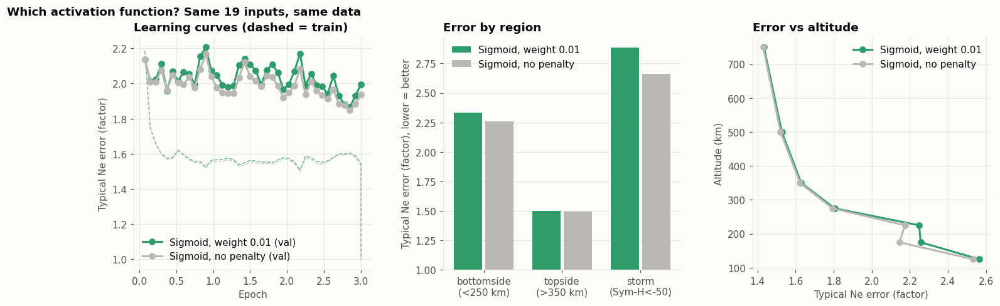

In [39]:
tic('15b. Activation comparison')
rows = []
for nm in ACT_MODELS:
    p = te["p_" + nm].values; m_ = metrics(yte, p); rows.append(dict(model=nm, activation=ANN_RES[nm]["act"], R2_log=m_["R2_log"], RMSE_log10=m_["RMSE_log10"], typical_factor=m_["typical_factor"], bias_factor=m_["bias_factor"], MedAPE_pct=m_["MedAPE_pct"], RMSE_Ne_cm3=m_["RMSE_Ne_cm3"], R2_Ne=m_["R2_linear_Ne"],
                     bottomside_RMSE=rmse(yte[(te["alt"] < 250).values], p[(te["alt"] < 250).values]), topside_RMSE=rmse(yte[(te["alt"] > 350).values], p[(te["alt"] > 350).values]),
                     storm_RMSE=rmse(yte[(te["symh"] < -50).values], p[(te["symh"] < -50).values]), epochs=ANN_RES[nm]["hist"][-1][0], minutes=ANN_RES[nm]["seconds"] / 60))
AC = pd.DataFrame(rows).set_index("model"); AC.round(4).to_csv(os.path.join(OUT, "metrics_activation_comparison.csv")); print(AC.round(3).to_string())
_lab = lambda nm: {"ANN": "Sigmoid, weight 0.01", "ANN SiLU 0.03": "SiLU, weight 0.03", "ANN SiLU 0.01": "SiLU, weight 0.01", "ANN no penalty": "Sigmoid, no penalty", "ANN SiLU no penalty": "SiLU, no penalty"}[nm]
ACOL = {"ANN": GREEN, "ANN SiLU 0.01": BLUE, "ANN SiLU 0.03": ORANGE, "ANN SiLU no penalty": "#8c2fb0", "ANN no penalty": GRAY, "ANN ReLU": BLUE, "ANN Sigmoid": ORANGE}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"wspace": .3})
for nm in ACT_MODELS:
    h = np.array(ANN_RES[nm]["hist"]); axs[0].plot(h[:, 0], 10 ** h[:, 2], "o-", color=ACOL.get(nm, GRAY), lw=2, label=f"{_lab(nm)} (val)"); axs[0].plot(h[:, 0], 10 ** h[:, 1], "--", color=ACOL.get(nm, GRAY), lw=1, alpha=.7)
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Typical Ne error (factor)"); axs[0].set_title("Learning curves (dashed = train)"); axs[0].legend()
xs = np.arange(3); w = .8 / len(ACT_MODELS)
for i, nm in enumerate(ACT_MODELS): axs[1].bar(xs + (i - (len(ACT_MODELS) - 1) / 2) * w, [10 ** AC.loc[nm, c] - 1 for c in ("bottomside_RMSE", "topside_RMSE", "storm_RMSE")], w * .9, bottom=1, color=ACOL.get(nm, GRAY), label=_lab(nm))
axs[1].set_xticks(xs); axs[1].set_xticklabels(["bottomside\n(<250 km)", "topside\n(>350 km)", "storm\n(Sym-H<-50)"]); axs[1].set_ylabel("Typical Ne error (factor), lower = better"); axs[1].set_title("Error by region"); axs[1].grid(axis="x", visible=False); axs[1].legend()
ab = [(100, 150), (150, 200), (200, 250), (250, 300), (300, 400), (400, 600), (600, 900)]
for nm in ACT_MODELS:
    axs[2].plot([10 ** rmse(yte[((te["alt"] >= a_) & (te["alt"] < b_)).values], te["p_" + nm].values[((te["alt"] >= a_) & (te["alt"] < b_)).values]) for a_, b_ in ab], [(a_ + b_) / 2 for a_, b_ in ab], "o-", color=ACOL.get(nm, GRAY), lw=2, label=_lab(nm))
axs[2].set_xlabel("Typical Ne error (factor)"); axs[2].set_ylabel("Altitude (km)"); axs[2].set_title("Error vs altitude"); axs[2].legend()
fig.suptitle(f"Which activation function? Same {len(FEATS)} inputs, same data", x=.01, ha="left", fontweight="bold"); save(fig, "fig11b_activation_comparison.png")


## 17. TOPSIDE vs BOTTOMSIDE test by source: error by altitude band, bottomside (< 250 km) and topside (> 350 km)

[ 12604s] 17. TOPSIDE vs BOTTOMSIDE test by source


   band   source       n  RMSE_log10    R2  factor  bias_factor
100-150     GIRO 1091270       0.417 0.488   2.610        1.221
100-150 COSMIC-1  161822       0.370 0.485   2.344        0.881
100-150 COSMIC-2  138003       0.392 0.452   2.464        0.914
150-200     GIRO 1430119       0.359 0.726   2.283        1.193
150-200 COSMIC-1  179104       0.317 0.661   2.076        1.020
150-200 COSMIC-2  159444       0.345 0.614   2.213        1.097
200-250     GIRO 1803178       0.367 0.774   2.329        1.139
200-250 COSMIC-1  209922       0.256 0.753   1.802        0.934
200-250 COSMIC-2  200257       0.293 0.689   1.965        0.992
250-300     GIRO 1182106       0.275 0.754   1.884        1.042
250-300 COSMIC-1  230143       0.180 0.844   1.514        0.953
250-300 COSMIC-2  230101       0.219 0.760   1.657        0.968
300-400     GIRO  547980       0.274 0.686   1.881        1.135
300-400 COSMIC-1  497313       0.143 0.922   1.390        1.050
300-400 COSMIC-2  509712       0.190 0.8

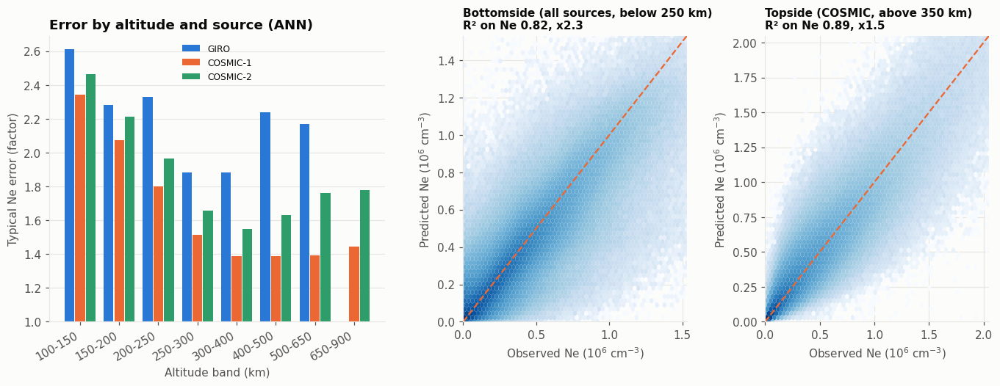

In [40]:
tic('17. TOPSIDE vs BOTTOMSIDE test by source')
te["src_name"] = te["src"].astype(int).map(SRC_NAME)
if (te["src"] >= 1).sum() < 1000: print("WARNING: almost no COSMIC rows in the test years. Check NE_YEAR_MIN / NE_YEAR_MAX.")
bands = [(100, 150), (150, 200), (200, 250), (250, 300), (300, 400), (400, 500), (500, 650), (650, 900)]; rows = []
for (lo_, hi_) in bands:
    for sname in SRC_NAME.values():
        g = te[(te["alt"] >= lo_) & (te["alt"] < hi_) & (te["src_name"] == sname)]
        if len(g) >= 500: rows.append(dict(band=f"{lo_}-{hi_}", source=sname, n=len(g), RMSE_log10=rmse(g["y"].values, g["p_" + BEST].values), R2=r2(g["y"].values, g["p_" + BEST].values), factor=10 ** rmse(g["y"].values, g["p_" + BEST].values), bias_factor=10 ** float((g["p_" + BEST] - g["y"]).mean())))
TB = pd.DataFrame(rows); TB.round(3).to_csv(os.path.join(OUT, "metrics_topside_bottomside.csv")); print(TB.round(3).to_string(index=False))
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.5, 1, 1], "wspace": .3})
bl = list(dict.fromkeys(TB["band"])) if len(TB) else []; xb = np.arange(len(bl))
for i, (sname, c) in enumerate([("GIRO", BLUE), ("COSMIC-1", ORANGE), ("COSMIC-2", GREEN)]):
    d = TB[TB["source"] == sname].set_index("band").reindex(bl); axs[0].bar(xb + (i - 1) * .27, d["factor"] - 1, .25, bottom=1, color=c, label=sname)
axs[0].set_xticks(xb); axs[0].set_xticklabels(bl, rotation=30, ha="right"); axs[0].set_ylabel("Typical Ne error (factor)"); axs[0].set_xlabel("Altitude band (km)"); axs[0].legend(fontsize=8); axs[0].set_title(f"Error by altitude and source ({BEST})"); axs[0].grid(axis="x", visible=False)
for ax, (ttl, m_) in zip(axs[1:], [("Bottomside (all sources, below 250 km)", (te["alt"] < 250)), ("Topside (COSMIC, above 350 km)", (te["alt"] > 350) & (te["src"] >= 1))]):
    g = te[m_]
    if len(g) > 100:
        _x, _y = 10 ** g["y"].values / 1e6, 10 ** g["p_" + BEST].values / 1e6; hi_ = float(np.percentile(_x, 99.9)); hb = ax.hexbin(_x, _y, gridsize=60, bins="log", mincnt=1, cmap="Blues", linewidths=0, extent=(0, hi_, 0, hi_)); ax.plot([0, hi_], [0, hi_], "--", color=ORANGE); ax.set_xlim(0, hi_); ax.set_ylim(0, hi_)
        ax.set_title(f"{ttl}\nR² on Ne {r2(10 ** g['y'].values, 10 ** g['p_' + BEST].values):.2f}, x{10 ** rmse(g['y'].values, g['p_' + BEST].values):.1f}", fontsize=10)
    ax.set_xlabel("Observed Ne (10$^6$ cm$^{-3}$)"); ax.set_ylabel("Predicted Ne (10$^6$ cm$^{-3}$)")
save(fig, "fig13_topside_bottomside_test.png")

## 19. Physics sanity checks on the trained model (should all say PASS)

In [41]:
tic('19. Physics sanity checks on the trained model (should all s')
print("MODEL SANITY"); AL = np.arange(100, 801, 2.0)
def _pk(doy, lt, lat, lon, f, sh=-5.0): return peaks(ne_model(doy, lt, lat, lon, AL, sh, f))
nm_hi, hm_hi = _pk(80, 12.0, 0.0, 75.0, 85.0); ok("noon equator, F10.7=85: NmF2 between 3e5 and 4e6", 3e5 < nm_hi < 4e6, f"(NmF2 {nm_hi:.2e})"); ok("noon equator: hmF2 between 220 and 480 km", 220 <= hm_hi <= 480, f"(hmF2 {hm_hi:.0f} km)")
ok("NmF2 grows with solar flux (F10.7 70 -> 85, 40N noon)", _pk(80, 12.0, 40.0, 75.0, 85.0)[0] > 1.3 * _pk(80, 12.0, 40.0, 75.0, 70.0)[0], f"({_pk(80, 12.0, 40.0, 75.0, 70.0)[0]:.2e} -> {_pk(80, 12.0, 40.0, 75.0, 85.0)[0]:.2e})")
ok("day density above night density at 300 km (40N, F10.7=75)", ne_model(80, 12.0, 40.0, 75.0, 300.0, -5.0, 75.0) > ne_model(80, 0.0, 40.0, 75.0, 300.0, -5.0, 75.0))
pr = ne_model(80, 12.0, 20.0, 75.0, AL, -5.0, 75.0); i_ = int(np.argmax(np.where((AL >= 150) & (AL <= 700), pr, 0)))
ok("topside falls off: Ne(hmF2+250 km) < 0.5 NmF2", pr[min(i_ + 125, len(AL) - 1)] < 0.5 * pr[i_]); ok("bottomside falls off: Ne(120 km) < 0.3 NmF2", pr[10] < 0.3 * pr[i_])
bd = ne_model(80, 12.0, 20.0, 75.0, 300.0, -100.0, 75.0) / ne_model(80, 12.0, 20.0, 75.0, 300.0, -5.0, 75.0); ok("storm changes Ne by less than a factor of 3 (Sym-H -100 vs -5)", 1 / 3 < bd < 3, f"(ratio {bd:.2f})")
ok(f"{BEST} beats the lookup table B4 (skill > 0.15)", M.loc[BEST, "skill_vs_B4"] > 0.15, f"(skill {M.loc[BEST, 'skill_vs_B4']:.2f})")
ok("no systematic bias (factor within 0.9-1.1)", 0.9 < M.loc[BEST, "bias_factor"] < 1.1, f"(bias x{M.loc[BEST, 'bias_factor']:.2f})")
ok("topside (COSMIC > 350 km) error below x2", 10 ** rmse(te.loc[(te["src"] >= 1) & (te["alt"] > 350), "y"].values, te.loc[(te["src"] >= 1) & (te["alt"] > 350), "p_" + BEST].values) < 2)
n_w = sum(1 for c_ in CHK if c_[1] == "WARN"); print(f"\n{len(CHK) - n_w} PASS, {n_w} WARN"); pd.DataFrame(CHK, columns=["check", "result", "info"]).to_csv(os.path.join(OUT, "sanity_checks.csv"), index=False)

print("\nDone. Everything is in", OUT)

[ 12628s] 19. Physics sanity checks on the trained model (should all s


MODEL SANITY
  [PASS] noon equator, F10.7=85: NmF2 between 3e5 and 4e6 (NmF2 8.87e+05)
  [PASS] noon equator: hmF2 between 220 and 480 km (hmF2 354 km)
  [PASS] NmF2 grows with solar flux (F10.7 70 -> 85, 40N noon) (4.12e+05 -> 6.59e+05)
  [PASS] day density above night density at 300 km (40N, F10.7=75) 
  [PASS] topside falls off: Ne(hmF2+250 km) < 0.5 NmF2 
  [PASS] bottomside falls off: Ne(120 km) < 0.3 NmF2 
  [PASS] storm changes Ne by less than a factor of 3 (Sym-H -100 vs -5) (ratio 1.18)
  [PASS] ANN beats the lookup table B4 (skill > 0.15) (skill 0.41)
  [PASS] no systematic bias (factor within 0.9-1.1) (bias x1.09)
  [PASS] topside (COSMIC > 350 km) error below x2 

22 PASS, 0 WARN

Done. Everything is in ne_results_v6b


## v5 vs v6b: same test rows, same grid
v5 (21 inputs with dip latitude and drift, all of COSMIC-2) is scored next to v6b (19 inputs, 30% of COSMIC-2 profiles) on the v6b test rows. The 2021 COSMIC-2 test rows are the 30% kept for v6b, so both models see the same rows. Both curves are raw network output.

[ 12628s] v5 vs v6b


                                               v5       v6b  v6b minus v5  change %
validation RMSE                            0.2984    0.2707       -0.0277   -9.2898
test RMSE                                  0.3131    0.2892       -0.0239   -7.6379
test R2 (log Ne)                           0.7804    0.8127        0.0323    4.1341
typical error (factor)                     2.0564    1.9462       -0.1102   -5.3577
bias (factor)                              1.1193    1.0930       -0.0263   -2.3485
test R2 (linear Ne)                        0.8380    0.8321       -0.0059   -0.7092
RMSE 100-150 km                            0.4582    0.4091       -0.0491  -10.7239
RMSE 150-250 km                            0.3899    0.3526       -0.0373   -9.5624
RMSE 250-400 km                            0.2354    0.2359        0.0004    0.1767
RMSE 400-600 km                            0.1888    0.1841       -0.0047   -2.4792
RMSE 600-900 km                            0.1600    0.1565       -0.0035   

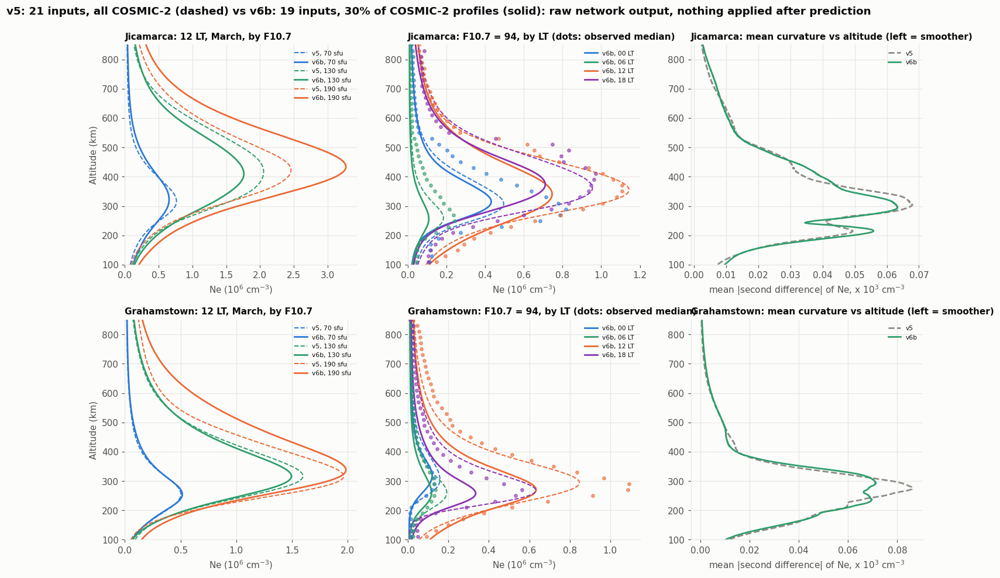

<function __main__.pred_v5(X, bs=262144)>

In [42]:
tic('v5 vs v6b')
V3 = "/home/user1/Downloads/ne_results_v5"; PRED["v5old"] = pred_v5; CMP = {"v5": "v5old", "v6b": "ANN"}; ALTB = [(100, 150), (150, 250), (250, 400), (400, 600), (600, 900)]; ATE, ADAY = Xte["alt"].values, te["lt"].between(6, 18).values; DOYS, LTS2, FS2 = (81, 172, 355), range(0, 24, 3), (70., 100., 130., 160., 190.)
Xte_w, Xva_w = featsw(te), featsw(va); _base_w = Xte_w.iloc[_sel].reset_index(drop=True)
def site_curves(nm, la, lo): return np.log10(np.array([ne_model(d, float(t), la, lo, AFine, -5.0, f, model=nm) for d in DOYS for t in LTS2 for f in FS2]))
def smooth_stats(Y):
    d1, d2 = np.diff(Y, axis=1), np.diff(Y, 2, axis=1); core = (AFine[1:-1] >= 150) & (AFine[1:-1] <= 700); pk = ((d1[:, :-1] > 0) & (d1[:, 1:] <= 0) & core).sum(1); s2 = np.where(np.abs(d2) > 1e-6, np.sign(d2), 0); b = np.array([(np.diff(r[r != 0]) != 0).sum() for r in s2])
    return dict(one_peak_pct=100 * float((pk == 1).mean()), max_curvature_e4=1e4 * float(np.abs(d2).max()), p99_curvature_e4=1e4 * float(np.percentile(np.abs(d2), 99)), sign_changes_median=float(np.median(b)), sign_changes_max=int(b.max()))
T3 = {}; CURV = {}
for lab, nm in CMP.items():
    p = PRED[nm](Xte_w); r = {"validation RMSE": rmse(yva, PRED[nm](Xva_w)), "test RMSE": rmse(yte, p), "test R2 (log Ne)": r2(yte, p), "typical error (factor)": 10 ** rmse(yte, p), "bias (factor)": 10 ** float((p - yte).mean()), "test R2 (linear Ne)": r2(10 ** yte, 10 ** p)}
    for a_, b_ in ALTB:
        m = (ATE >= a_) & (ATE < b_); r[f"RMSE {a_}-{b_} km"] = rmse(yte[m], p[m])
    m = te["symh"].values < -50; r["RMSE storm (Sym-H < -50)"] = rmse(yte[m], p[m]); r["RMSE day"] = rmse(yte[ADAY], p[ADAY]); r["RMSE night"] = rmse(yte[~ADAY], p[~ADAY])
    for sn, la, lo in SITES2:
        Y = site_curves(nm, la, lo); s_ = sn.split(" (")[0]; CURV[(lab, s_)] = np.abs(np.diff(10 ** Y, 2, axis=1)).mean(0)
        for k_, v_ in smooth_stats(Y).items(): r[f"{s_}: {k_}"] = v_
    P_ = profile_grid(PRED[nm], _base_w); dP = np.diff(P_, axis=1); pk = ((dP[:, :-1] > 0) & (dP[:, 1:] <= 0)).sum(1); r["400 random test profiles: one peak %"] = 100 * float((pk == 1).mean()); r["400 random test profiles: roughness e-4"] = 1e4 * float(np.abs(np.diff(P_, 2, axis=1)).mean()); T3[lab] = r
TV = pd.DataFrame(T3); TV["v6b minus v5"] = TV["v6b"] - TV["v5"]; TV["change %"] = 100 * TV["v6b minus v5"] / TV["v5"].abs().replace(0, np.nan); TV.round(4).to_csv(os.path.join(OUT, "v5_vs_v6b.csv")); print(TV.round(4).to_string())
if len(R7) and "model" in pd.DataFrame(R7).columns: _f3 = pd.read_csv(os.path.join(V3, "metrics_paper_fig7_analogue.csv")); _f4 = R7 if isinstance(R7, pd.DataFrame) else pd.DataFrame(R7); F7 = _f3[_f3["model"] == "ANN"].merge(_f4[_f4["model"] == "ANN"], on=["alt", "diplat"], suffixes=("_v5", "_v6b")).merge(_f4[_f4["model"] == "IRI"][["alt", "diplat", "R", "RMSE"]].rename(columns={"R": "R_IRI", "RMSE": "RMSE_IRI"}), on=["alt", "diplat"]); print("\nFig 7 comparison:"); print(F7[["alt", "diplat", "R_v5", "R_v6b", "R_IRI", "RMSE_v5", "RMSE_v6b", "RMSE_IRI"]].round(3).to_string(index=False)); F7.round(4).to_csv(os.path.join(OUT, "v5_vs_v6b_fig7.csv"), index=False)
fig, axs = plt.subplots(2, 3, figsize=(16, 10), gridspec_kw={"hspace": .25, "wspace": .22}); LN = {"v5": ("--", 1.3), "v6b": ("-", 1.8)}
for r_, (sn, la, lo) in enumerate(SITES2):
    for f, c in zip((70., 130., 190.), (BLUE, GREEN, ORANGE)):
        for lab, nm in CMP.items(): axs[r_, 0].plot(ne_model(81, 12.0, la, lo, AFine, -5.0, f, model=nm) / 1e6, AFine, color=c, ls=LN[lab][0], lw=LN[lab][1], label=f"{lab}, {f:.0f} sfu")
    for lt_, c in zip(LT2, CL):
        for lab, nm in CMP.items(): axs[r_, 1].plot(ne_model(81, float(lt_), la, lo, AFine, D2["symh"], F2, model=nm, drv=D2) / 1e6, AFine, color=c, ls=LN[lab][0], lw=LN[lab][1], label=f"{lab}, {lt_:02d} LT" if lab == "v6b" else None)
        o_ = obs2(la, lo, lt_)
        if len(o_): axs[r_, 1].scatter(o_["median"] / 1e6, o_.index, s=12, color=c, alpha=.6, zorder=3)
    s_ = sn.split(" (")[0]
    for lab in CMP: axs[r_, 2].plot(CURV[(lab, s_)] / 1e3, AFine[1:-1], color=DGRAY if lab == "v5" else GREEN, ls=LN[lab][0], lw=1.8, label=lab)
    axs[r_, 0].set_title(f"{s_}: 12 LT, March, by F10.7", fontsize=10); axs[r_, 1].set_title(f"{s_}: F10.7 = {F2:.0f}, by LT (dots: observed median)", fontsize=10); axs[r_, 2].set_title(f"{s_}: mean curvature vs altitude (left = smoother)", fontsize=10); axs[r_, 2].set_xlabel("mean |second difference| of Ne, x 10$^3$ cm$^{-3}$")
    for a in axs[r_]: a.set_ylim(100, 850); a.legend(fontsize=7, loc="upper right")
    for a in axs[r_, :2]: a.set_xlim(left=0); a.set_xlabel("Ne (10$^6$ cm$^{-3}$)")
    axs[r_, 0].set_ylabel("Altitude (km)")
fig.suptitle("v5: 21 inputs, all COSMIC-2 (dashed) vs v6b: 19 inputs, 30% of COSMIC-2 profiles (solid): raw network output, nothing applied after prediction", x=.01, ha="left", fontweight="bold", y=.94); save(fig, "v5_vs_v6b_profiles.png"); PRED.pop("v5old")


## v5 vs v6b: equatorial anomaly crests by longitude sector, same profiles
Without dip latitude, v6b has to find the magnetic equator from latitude and longitude. Each panel uses the real profiles of the unseen years (validation, test, 2024) at 12-16 LT near the equinoxes, within 20 degrees of the sector's longitude: observed NmF2 (median per 4 degree latitude bin) and v5 and v6b on the same profiles. The grey line is the dip equator in that sector. The table gives each crest's latitude and Ne, the trough Ne at the dip equator, and each model's typical NmF2 error on those profiles.

[ 12682s] v5 vs v6b: equatorial anomaly crests by longitude sector


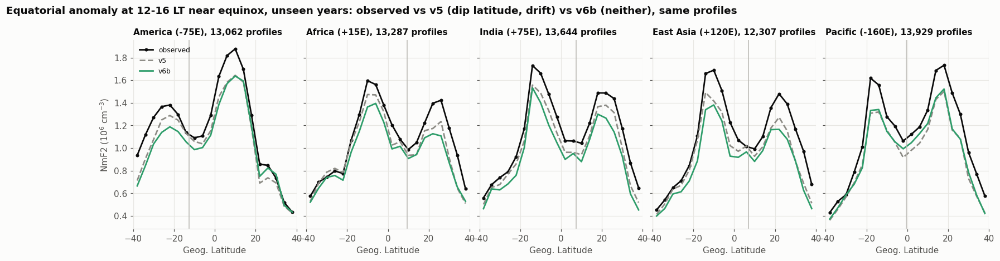

   sector   source  profiles  dip_equator_lat  north_crest_lat  north_crest_Ne  south_crest_lat  south_crest_Ne  trough_Ne  crest_to_trough  NmF2_typical_error_factor  NmF2_bias_factor
  America observed     13062            -12.5             10.0       1877392.0            -22.0       1381297.0  1119609.0             1.68                       1.00              1.00
  America       v5     13062            -12.5             10.0       1643610.0            -22.0       1288304.0  1103022.0             1.49                       1.32              0.89
  America      v6b     13062            -12.5             10.0       1637356.0            -22.0       1188326.0  1028790.0             1.59                       1.31              0.90
   Africa observed     13287              9.5             26.0       1423164.0            -10.0       1595798.0   998628.0             1.60                       1.00              1.00
   Africa       v5     13287              9.5             26.0       123527

In [43]:
tic('v5 vs v6b: equatorial anomaly crests by longitude sector')
SECT = [("America", -75.0), ("Africa", 15.0), ("India", 75.0), ("East Asia", 120.0), ("Pacific", -160.0)]; LB = np.arange(-40, 41, 4.0); LC = LB[:-1] + 2
P_ = PROF[PROF["year"].isin(UNSEEN) & PROF["lt"].between(12, 16) & PROF["month"].isin([2, 3, 4, 8, 9, 10]) & PROF["lat"].between(-40, 40)].dropna(subset=["nm_v5", "nm_ANN"])
def _crest(lat, v, side):
    m = (lat > 0) if side > 0 else (lat < 0)
    if not m.any(): return np.nan, np.nan
    k = int(np.nanargmax(np.where(m, v, -np.inf))); return float(lat[k]), float(v[k])
rows = []; fig, axs = plt.subplots(1, len(SECT), figsize=(18, 4), sharey=True, gridspec_kw={"wspace": .06})
for ax, (sn, lo0) in zip(axs, SECT):
    _la = np.arange(-30, 30.1, 0.5); eq = float(_la[np.abs(_gv[_tree.query(np.c_[_la, np.full(_la.shape, lo0)])[1], 0]).argmin()])
    g = P_[np.abs((P_["lon"] - lo0 + 180) % 360 - 180) <= 20]
    q = g.groupby(pd.cut(g["lat"], LB), observed=False).agg(n=("nm", "size"), observed=("nm", "median"), v5=("nm_v5", "median"), v6b=("nm_ANN", "median")); q.index = LC; q = q[q["n"] >= 30]
    for k, c, ls in (("observed", INK, "-"), ("v5", DGRAY, "--"), ("v6b", GREEN, "-")): ax.plot(q.index, q[k] / 1e6, color=c, ls=ls, lw=1.8, marker="o" if k == "observed" else None, ms=3, label=k)
    ax.axvline(eq, color=GRAY, lw=1); ax.set_title(f"{sn} ({lo0:+.0f}E), {len(g):,} profiles", fontsize=10); ax.set_xlabel("Geog. Latitude"); ax.set_xlim(-40, 40)
    if len(q) < 5: continue
    lat_ = q.index.values - eq
    for k in ("observed", "v5", "v6b"):
        v = q[k].values; ln, vn = _crest(lat_, v, 1); ls_, vs_ = _crest(lat_, v, -1); tr_ = float(np.interp(0, lat_, v))
        e = np.log10(g["nm_" + ("ANN" if k == "v6b" else k)].values / g["nm"].values) if k != "observed" else np.zeros(1)
        rows.append(dict(sector=sn, source=k, profiles=len(g), dip_equator_lat=eq, north_crest_lat=ln + eq, north_crest_Ne=vn, south_crest_lat=ls_ + eq, south_crest_Ne=vs_, trough_Ne=tr_, crest_to_trough=max(vn, vs_) / tr_, NmF2_typical_error_factor=10 ** float(np.sqrt(np.mean(e ** 2))), NmF2_bias_factor=10 ** float(np.mean(e))))
axs[0].set_ylabel("NmF2 (10$^6$ cm$^{-3}$)"); axs[0].legend(fontsize=8); fig.suptitle("Equatorial anomaly at 12-16 LT near equinox, unseen years: observed vs v5 (dip latitude, drift) vs v6b (neither), same profiles", x=.01, ha="left", fontweight="bold", y=1.02); save(fig, "v5_vs_v6b_eia_crests_by_sector.png")
EIA = pd.DataFrame(rows); EIA.to_csv(os.path.join(OUT, "v5_vs_v6b_eia_crests.csv"), index=False)
print(EIA.round({"dip_equator_lat": 1, "north_crest_lat": 1, "south_crest_lat": 1, "north_crest_Ne": 0, "south_crest_Ne": 0, "trough_Ne": 0, "crest_to_trough": 2, "NmF2_typical_error_factor": 2, "NmF2_bias_factor": 2}).to_string(index=False))


## Validation checks
How far to trust the results: every row by year, v5 vs v6b across days, peaks of real profiles, leave-one-year-out, and the status of each figure.

In [44]:
tic('Validation checks')
VC = []
def vc(check, value, note=""): VC.append(dict(check=check, value=value, note=note))
print("1. EVERY ROW, BY YEAR (training years are not a fair test)")
ry = pd.DataFrame({y_: dict(role="future" if y_ in FUTURE_YEARS else "test" if y_ in TEST_YEARS else "validation" if y_ in VAL_YEARS else "training", rows=r_["n"], RMSE=np.sqrt(r_["s"] / r_["n"]), R2=1 - r_["s"] / (r_["syy"] - r_["sy"] ** 2 / r_["n"]), low_Ne_rows_left_out=r_["low_n"], RMSE_with_low_Ne=np.sqrt((r_["s"] + r_["low_s"]) / (r_["n"] + r_["low_n"]))) for y_, r_ in sorted(YR.items())}).T; print(ry.to_string()); ry.to_csv(os.path.join(OUT, "check_rows_by_year.csv"))
for y_ in UNSEEN: vc(f"RMSE {y_}, every row", float(ry.loc[y_, "RMSE"]), ry.loc[y_, "role"]); vc(f"RMSE {y_}, low-Ne rows included", float(ry.loc[y_, "RMSE_with_low_Ne"]), "Ne below NE_MIN is left out of the headline")
print("\n2. BOOTSTRAP BY DAY: is v6b different from v5 (21 inputs, all COSMIC-2)?")
for y_ in UNSEEN:
    q_ = pd.DataFrame.from_dict(DAILY[y_], orient="index", columns=["n", "s3", "s4"]); g_ = np.random.default_rng(1); b_ = np.array([(lambda z: (np.sqrt(z.s3.sum() / z.n.sum()), np.sqrt(z.s4.sum() / z.n.sum())))(q_.iloc[g_.integers(0, len(q_), len(q_))]) for _ in range(2000)]); lo_, hi_ = np.percentile(b_[:, 1] - b_[:, 0], [2.5, 97.5]); print(f"{y_}: v5 {np.sqrt(q_.s3.sum()/q_.n.sum()):.4f}, v6b {np.sqrt(q_.s4.sum()/q_.n.sum()):.4f}, v6b minus v5 95% range {lo_:+.4f} to {hi_:+.4f}"); vc(f"RMSE v6b minus v5 {y_}, 95% low", float(lo_), "range across days, same trained models"); vc(f"RMSE v6b minus v5 {y_}, 95% high", float(hi_))
print("\n3. PEAKS OF REAL PROFILES, model at the same rows")
_T = PROF[PROF["year"].isin([y_ for y_ in YR if y_ not in UNSEEN])].copy(); _T["yl"] = np.log10(_T["nm"]); _key = lambda T: T["month"].astype(int) * 100000 + ((T["lat"] // 5).astype(int) + 20) * 100 + (T["lt"] // 2).astype(int); _cm = _T.groupby(_key(_T)).agg(yl=("yl", "mean"), hm=("hm", "mean"))
def pstat(T, k):
    e = np.log10(T["nm_" + k].values) - np.log10(T["nm"].values); h = T["hm_" + k].values - T["hm"].values; return dict(profiles=len(T), NmF2_factor=10 ** np.sqrt((e ** 2).mean()), NmF2_bias=10 ** e.mean(), NmF2_R=np.corrcoef(np.log10(T["nm_" + k]), np.log10(T["nm"]))[0, 1], hmF2_RMSE_km=np.sqrt((h ** 2).mean()), hmF2_bias_km=h.mean(), hmF2_R=np.corrcoef(T["hm_" + k], T["hm"])[0, 1])
for y_ in UNSEEN:
    T_ = PROF[PROF["year"] == y_].copy(); c_ = _cm.reindex(_key(T_)); T_["nm_clim"], T_["hm_clim"] = 10 ** c_["yl"].fillna(_T["yl"].mean()).values, c_["hm"].fillna(_T["hm"].mean()).values; t_ = pd.DataFrame({k: pstat(T_, k) for k in ("clim", "v5", "ANN")}).rename(columns={"ANN": "v6b", "clim": "climatology"}); print(y_); print(t_.round(3).to_string()); t_.round(4).to_csv(os.path.join(OUT, f"check_profile_peaks_{y_}.csv"))
    vc(f"NmF2 factor {y_} v6b", float(t_.loc["NmF2_factor", "v6b"])); vc(f"NmF2 factor {y_} v5", float(t_.loc["NmF2_factor", "v5"])); vc(f"NmF2 bias {y_} v6b", float(t_.loc["NmF2_bias", "v6b"])); vc(f"hmF2 RMSE km {y_} v6b", float(t_.loc["hmF2_RMSE_km", "v6b"])); vc(f"hmF2 RMSE km {y_} v5", float(t_.loc["hmF2_RMSE_km", "v5"]))
print("training years, v6b (optimistic by design):", {k: round(float(v), 3) for k, v in pstat(_T, "ANN").items()})
print("\n4. SITE PEAKS IN THE MARCH WINDOW: all years vs unseen years, model on the same rows"); rows = []
for s_, gg in WB[np.abs(WB["doy"] - 81) <= 20].groupby("site"):
    if s_ == "Millstone": continue
    for lt0 in (0, 6, 12, 18):
        g2 = gg[np.minimum(np.abs(gg["lt"] - lt0), 24 - np.abs(gg["lt"] - lt0)) <= 1]
        for lab, ys in (("all years", list(YR)), ("unseen years", UNSEEN), ("test year", list(TEST_YEARS))):
            h = g2[g2["year"].isin(ys)]
            if len(h) < 300: continue
            q_ = h.groupby((h["alt"] // 20) * 20 + 10).agg(o=("ne", "median"), m=("p", lambda x: 10 ** x.median()), n=("ne", "size")); q_ = q_[(q_["n"] >= 10) & (q_.index >= 150) & (q_.index <= 700)]; rows.append(dict(site=s_, LT=lt0, rows_from=lab, rows=len(h), obs_peak=q_["o"].max() / 1e6, model_peak=q_["m"].max() / 1e6, error_pct=100 * (q_["m"].max() / q_["o"].max() - 1), obs_hmF2=q_["o"].idxmax(), model_hmF2=q_["m"].idxmax()))
SC = pd.DataFrame(rows); print(SC.round(2).to_string(index=False)); SC.round(3).to_csv(os.path.join(OUT, "check_site_peaks.csv"), index=False)
print("\n5. LEAVE ONE YEAR OUT: 20 M training rows from the other years, one year for validation, one for test"); rows = []; _y = df["year"].values.astype(int); _SEED0 = SEED; _yr = [y_ for y_ in sorted(set(_y.tolist())) if (_y == y_).sum() >= int(os.environ.get("NE_LOYO_MIN_ROWS", 500_000))]; _folds = [(t_, _yr[(i_ + 1) % len(_yr)]) for i_, t_ in enumerate(_yr)]; _ty = next((y_ for y_ in (2009,) + tuple(TEST_YEARS) if y_ in _yr), _yr[0]); _vy = next((y_ for y_ in (2007,) + tuple(VAL_YEARS) if y_ in _yr and y_ != _ty), _yr[-1])
for t_, v_ in _folds + [(_ty, _vy)] * 2:
    SEED = _SEED0 + len(rows); rs = np.random.RandomState(SEED); ix = np.flatnonzero(~np.isin(_y, [t_, v_])); ix = np.sort(rs.choice(ix, min(20_000_000, len(ix)), replace=False)); vi = np.flatnonzero(_y == v_); vi = np.sort(rs.choice(vi, min(2_000_000, len(vi)), replace=False)); ti = np.flatnonzero(_y == t_); ti = np.sort(rs.choice(ti, min(5_000_000, len(ti)), replace=False)); yc = df["y"].values[ti]
    r_ = train_ann(MAIN_ACT, feats(df.iloc[ix]), df["y"].values[ix], feats(df.iloc[vi]), df["y"].values[vi], ANN_EPOCHS, "cv", save=False, lam=SMOOTH_LAM); p_ = r_["predict"](feats(df.iloc[ti])); rows.append(dict(test_year=t_, validation_year=v_, seed=SEED, RMSE=rmse(yc, p_), R2=r2(yc, p_), bias=10 ** float((p_ - yc).mean()), median_F107=float(np.median(df["f107"].values[ti])))); del r_; gc.collect()
SEED = _SEED0; CV = pd.DataFrame(rows); print(CV.round(4).to_string(index=False)); CV.round(4).to_csv(os.path.join(OUT, "check_leave_one_year_out.csv"), index=False); _c = CV.iloc[:len(_folds)]; print(f"mean across years: RMSE {_c['RMSE'].mean():.4f}, R2 {_c['R2'].mean():.4f}; range {_c['RMSE'].min():.4f} to {_c['RMSE'].max():.4f}; same year, different seeds: {CV[CV['test_year'] == _ty]['RMSE'].round(4).tolist()}"); vc("Leave-one-year-out RMSE, mean of years", float(_c["RMSE"].mean()), "20 M rows; compare only with the 2009 row of the same table"); vc("Leave-one-year-out RMSE, test year", float(_c[_c["test_year"] == _ty]["RMSE"].iloc[0]))
print("\n6. MAIN TROUGH, March, 60-90E, 250-350 km, every row")
for il_, lab in ((0, "00-03 LT"), (1, "03-06 LT")):
    A = LA[0, 1, il_, :, 7:12, :].sum(1); n_ = A[:, 0]; k_ = (n_ >= 30) & (_lc >= 45); print(lab, pd.DataFrame({"lat": _lc[k_], "observed_1e5": 10 ** (A[k_, 1] / n_[k_]) / 1e5, "ANN_1e5": 10 ** (A[k_, 2] / n_[k_]) / 1e5}).round(2).set_index("lat").T.to_string())
print("\n7. STATUS OF THE FIGURES")
ST = [("Ne vs altitude, altitude vs latitude", "Every row of 1993-2024, so training years are included. Agreement here is not independent; sections 1 to 5 are the independent tests."), ("Fig 6 and Fig 7", "Test years only, compared with COSMIC, an instrument the model trained on. Not independent of the instrument. IRI is PyIRI, not IRI-2016."), ("Fig 9", "Model output; section 6 compares it with observations."), ("Fig 10", "NOT VALIDATED: model response only. Comparing storm and quiet rows directly is confounded by season and solar flux."), ("Sanity checks", "Limits were set for this data and are loose: they catch failures but do not prove accuracy."), ("Test and future years", "Split fixed before training; settings were carried over from v5 and not tuned on these years. The future year is scored once.")]
for a_, b_ in ST: print(f"  {a_}: {b_}"); vc("Status: " + a_, "", b_)
pd.DataFrame(VC).to_csv(os.path.join(OUT, "validation_checks.csv"), index=False); print("\nsaved validation_checks.csv and check_*.csv in", OUT)


[ 12684s] Validation checks


1. EVERY ROW, BY YEAR (training years are not a fair test)
            role       rows      RMSE        R2 low_Ne_rows_left_out RMSE_with_low_Ne
1994    training      22345  0.297832  0.804949                 9470         4.247007
1995    training      84062  0.327227  0.750896                34585         5.578788
1996    training      30335  0.350994  0.731655                 9938         6.587366
1997    training     178660  0.306184  0.794069                63625         5.874869
1998    training     536502  0.343938  0.776309               169225         6.226494
1999    training    1008206  0.309904  0.817585               197787         4.259765
2000    training     949813  0.278895  0.858923               120425         2.216028
2001    training    3232192  0.336546  0.809725               611001         2.863088
2002        test    5198256  0.436274  0.707218              1077198         3.248414
2003  validation    3358674  0.389918  0.737747               962443         4.41

2003: v5 0.4461, v6b 0.3899, v6b minus v5 95% range -0.0679 to -0.0438


2007: v5 0.2415, v6b 0.2370, v6b minus v5 95% range -0.0080 to -0.0015


2012: v5 0.2527, v6b 0.2328, v6b minus v5 95% range -0.0247 to -0.0157


2017: v5 0.3407, v6b 0.3031, v6b minus v5 95% range -0.0412 to -0.0337


... (937 outputs left out)

[cv] epoch 2.92/3 train~0.2535 val RMSE(log10) 0.2152 balanced 0.2152 lr 1.2e-05 70s


[cv] epoch 3.00/3 train~0.2528 val RMSE(log10) 0.2153 balanced 0.2153 lr 1.0e-05 71s


[cv] epoch 3.00/3 train~0.0000 val RMSE(log10) 0.2149 balanced 0.2149 lr 1.0e-05 72s


 test_year  validation_year  seed   RMSE     R2   bias  median_F107
      2004             2005     0 0.4254 0.6567 1.2256         93.7
      2005             2006     1 0.4028 0.6543 1.2065         80.6
      2006             2007     2 0.2523 0.7892 1.0647         78.7
      2007             2008     3 0.2158 0.8426 0.9399         71.5
      2008             2009     4 0.2039 0.8491 1.0360         68.4
      2009             2010     5 0.2089 0.8418 1.0779         69.8
      2010             2011     6 0.2156 0.8450 0.9042         78.9
      2011             2012     7 0.2252 0.8488 1.0281        109.3
      2012             2013     8 0.2313 0.8358 0.9794        114.6
      2013             2014     9 0.2338 0.8358 0.9422        117.1
      2014             2015    10 0.2476 0.8192 0.9635        143.3
      2015             2016    11 0.2442 0.8266 0.9935        116.6
      2016             2017    12 0.2586 0.8049 0.9463         87.5
      2017             2018    13 0.2922 0.7718 

## Plot helpers for the one-driver tests
v5's drift test is not repeated: drift is not an input of v6b, so the model cannot respond to it.

In [45]:
import matplotlib.colors as mcolors
NE_LO = 1e4; NE_TK = np.array([0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 30]) * 1e5
def ne_levels(vmax): return np.geomspace(NE_LO, vmax, 37), mcolors.LogNorm(NE_LO, vmax)
def ne_cbar(fig, cs, axs, vmax):
    tk = NE_TK[NE_TK <= vmax]; cb = fig.colorbar(cs, ax=axs, shrink=.7, pad=.02, ticks=tk); cb.set_label("Ne/cm$^3$ (colour steps get wider with Ne)"); cb.ax.set_yticklabels([f"{t_ / 1e5:g}" for t_ in tk]); cb.ax.set_title("×10$^5$", fontsize=8); cb.ax.minorticks_off(); return cb
def change_maps(Zd, rows, base, others, coltitle, basetitle, title, fname):
    P = {(r, v): Zd[(r, v)] / Zd[(r, base)] for r in rows for v in others}; a = np.abs(np.log(np.concatenate([p.ravel() for p in P.values()])))
    hi = float(np.exp(max(np.log(1.25), np.percentile(a, 99.5)))); lo = 1 / hi; lv = np.geomspace(lo, hi, 25); nm = mcolors.LogNorm(lo, hi); tk = [t_ for t_ in (0.1, 0.2, 0.5, 0.67, 0.8, 0.9, 1, 1.1, 1.25, 1.5, 2, 5, 10) if lo <= t_ <= hi]
    fig, axs = plt.subplots(len(rows), len(others), figsize=(3.3 * len(others) + 1.5, 8), sharex=True, sharey=True, squeeze=False, gridspec_kw={"hspace": .12, "wspace": .05})
    for j, r in enumerate(rows):
        for i, v in enumerate(others):
            ax = axs[j, i]; ax.grid(False); cs = ax.contourf(LAT12, ALT12, np.clip(P[(r, v)], lo, hi).T, levels=lv, norm=nm, cmap="RdBu_r", extend="both"); ax.contour(LAT12, ALT12, P[(r, v)].T, levels=[1], colors="k", linewidths=.6); ax.set_xticks(range(-40, 41, 20)); ax.set_yticks([200, 400, 600, 800])
            if j == 0: ax.set_title(coltitle(v), fontsize=10)
            if i == 0: ax.set_ylabel(f"{r}\nAltitude (km)")
            if j == len(rows) - 1: ax.set_xlabel("Geog. Latitude")
    cb = fig.colorbar(cs, ax=axs, shrink=.7, pad=.02, ticks=tk); cb.ax.minorticks_off(); cb.ax.set_yticklabels([f"×{t_:g}" for t_ in tk]); cb.set_label(f"Ne ÷ Ne at {basetitle}  (×2 = +100%, ×0.5 = −50%)")
    for r in rows:
        for v in others: p = P[(r, v)]; print(f"{r:9s} {coltitle(v):18s} Ne ÷ base: min ×{p.min():.2f}, median ×{np.median(p):.2f}, max ×{p.max():.2f}")
    fig.suptitle(title + "\n(black line: no change; red = more Ne, blue = less)", fontweight="bold"); save(fig, fname)
SE12 = [("March", 80), ("June", 172), ("December", 355)]; LAT12 = np.arange(-60, 60.1, 1.0); ALT12 = np.arange(150, 801, 2.0); DCOL = [BLUE, GREEN, ORANGE, INK]
_eq = _tree.query(np.c_[LAT12, np.full(LAT12.shape, 75.0)])[1]; LAT_EQ = float(LAT12[np.abs(_gv[_eq, 0]).argmin()])
print(f"magnetic equator at 75E is near {LAT_EQ:.0f} deg latitude (from the data's dip latitude, used here only to mark the plots)")


magnetic equator at 75E is near 8 deg latitude (from the data's dip latitude, used here only to mark the plots)


## One-driver tests: Fig 8 at 12 LT, 60S to 60N, all other inputs locked, one driver changed at a time (F10.7, Kp, Sym-H, CPCP)
Locked base: each season's quiet-time Kp, Sym-H and CPCP from the data, F10.7 = 75 sfu, 75E, 12 LT. When F10.7 changes, its 81-day mean is set to the same value. Changing Kp or Sym-H alone gives combinations that rarely occur together (for example Kp 7 with Sym-H -5 nT), so read those panels as the network's response to one input, not as a real storm. A * marks a value outside the 0.5-99.5% range of the noon data. Dashed lines: v5 (21 inputs, all COSMIC-2) on the same grid. The last table checks each trend against observations binned by that driver, with both models on the same rows. Colours use steps that widen with Ne, so the topside and the crests are both visible. The change maps show Ne divided by Ne at the first value, at every latitude and altitude (×2 = +100%, ×0.5 = −50%; red = more, blue = less).


[ 14900s] One-driver tests: Fig 8 at 12 LT, one driver changed, all others locked


0.5-99.5% range at 11-13 LT: {'f107': (66.1, 233.2), 'kp': (0.0, 5.7), 'symh': (-83.0, 23.0), 'cpcp': (13.1, 84.2)}


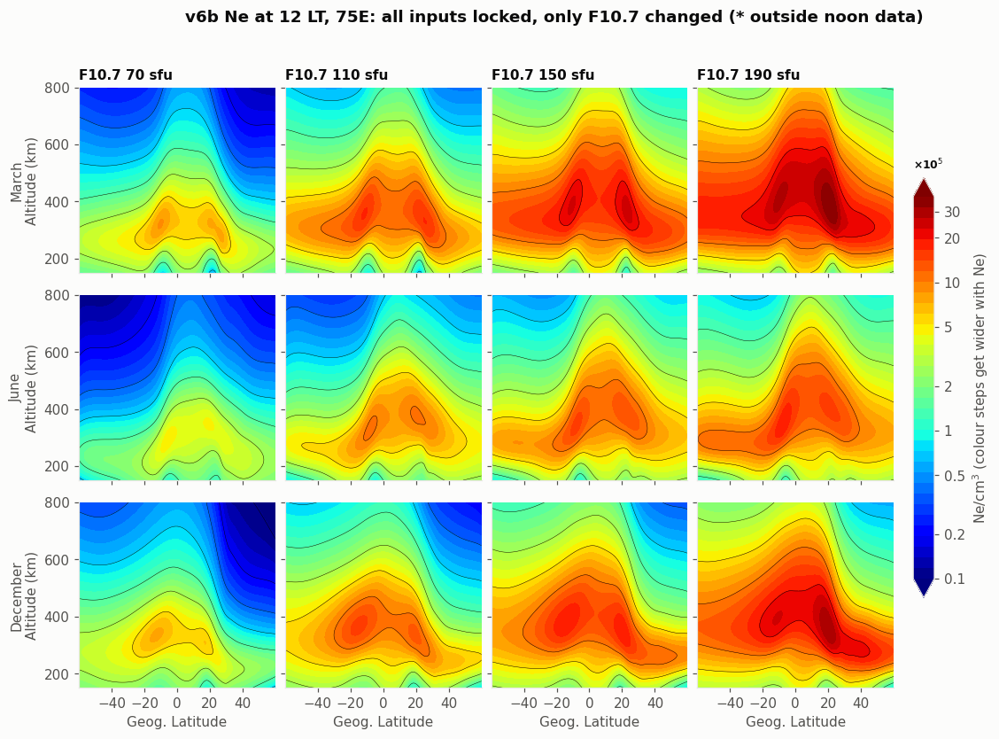

March     F10.7 110 sfu      Ne ÷ base: min ×0.97, median ×3.18, max ×5.14
March     F10.7 150 sfu      Ne ÷ base: min ×1.10, median ×6.96, max ×11.49
March     F10.7 190 sfu      Ne ÷ base: min ×1.25, median ×11.68, max ×20.32
June      F10.7 110 sfu      Ne ÷ base: min ×0.90, median ×3.02, max ×5.04
June      F10.7 150 sfu      Ne ÷ base: min ×0.92, median ×5.27, max ×8.78
June      F10.7 190 sfu      Ne ÷ base: min ×1.01, median ×6.94, max ×11.62
December  F10.7 110 sfu      Ne ÷ base: min ×1.07, median ×2.66, max ×4.94
December  F10.7 150 sfu      Ne ÷ base: min ×1.15, median ×4.50, max ×8.81
December  F10.7 190 sfu      Ne ÷ base: min ×1.27, median ×7.23, max ×17.31


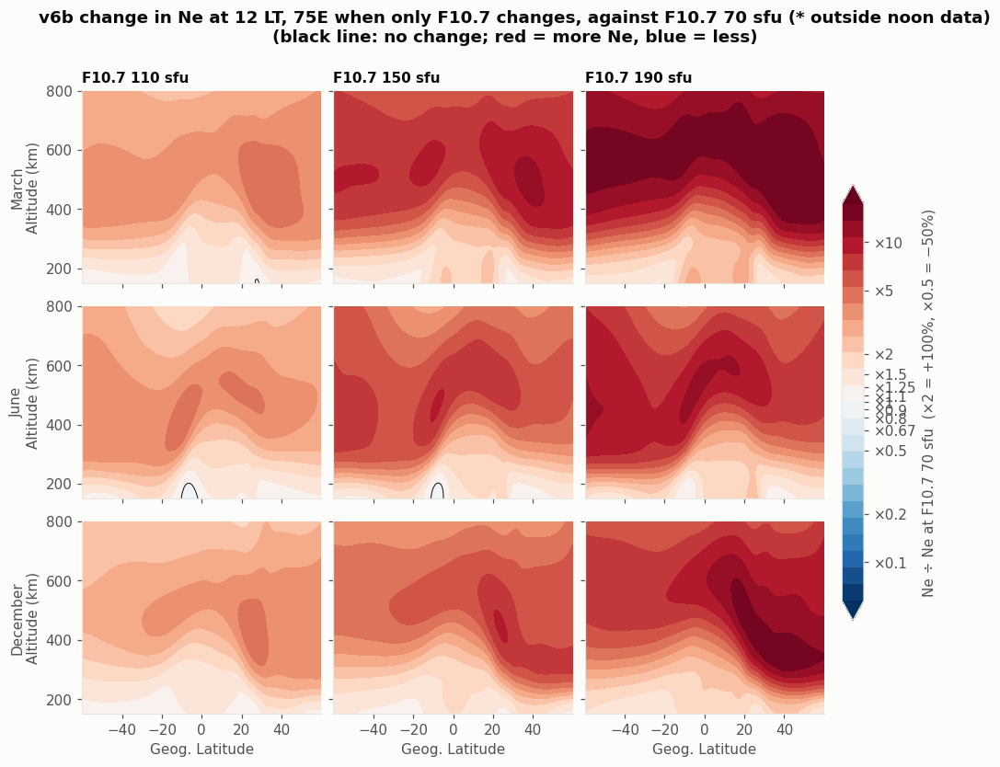

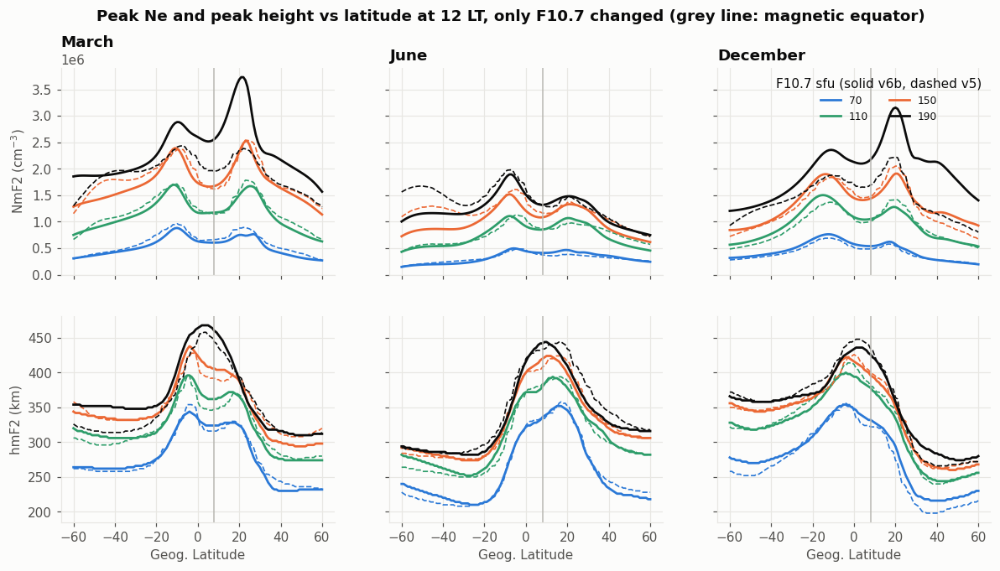

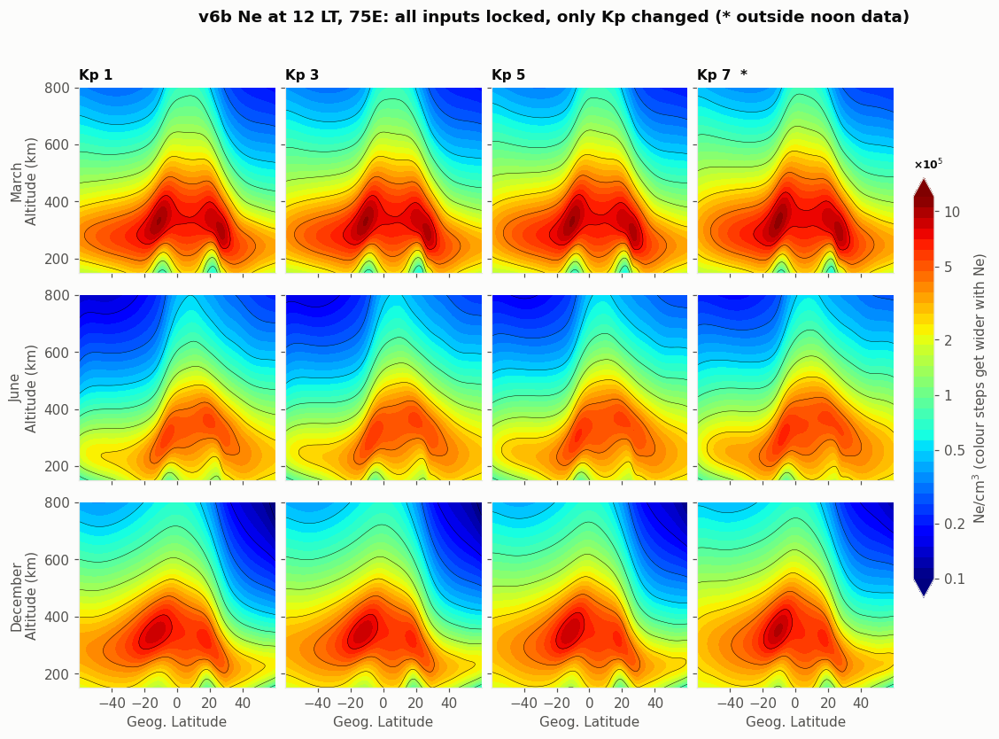

March     Kp 3               Ne ÷ base: min ×0.92, median ×1.00, max ×1.09
March     Kp 5               Ne ÷ base: min ×0.85, median ×1.03, max ×1.19
March     Kp 7  *            Ne ÷ base: min ×0.80, median ×1.10, max ×1.34
June      Kp 3               Ne ÷ base: min ×0.97, median ×1.07, max ×1.21
June      Kp 5               Ne ÷ base: min ×0.93, median ×1.15, max ×1.42
June      Kp 7  *            Ne ÷ base: min ×0.89, median ×1.23, max ×1.63
December  Kp 3               Ne ÷ base: min ×0.92, median ×1.01, max ×1.11
December  Kp 5               Ne ÷ base: min ×0.85, median ×1.03, max ×1.32
December  Kp 7  *            Ne ÷ base: min ×0.79, median ×1.09, max ×1.64


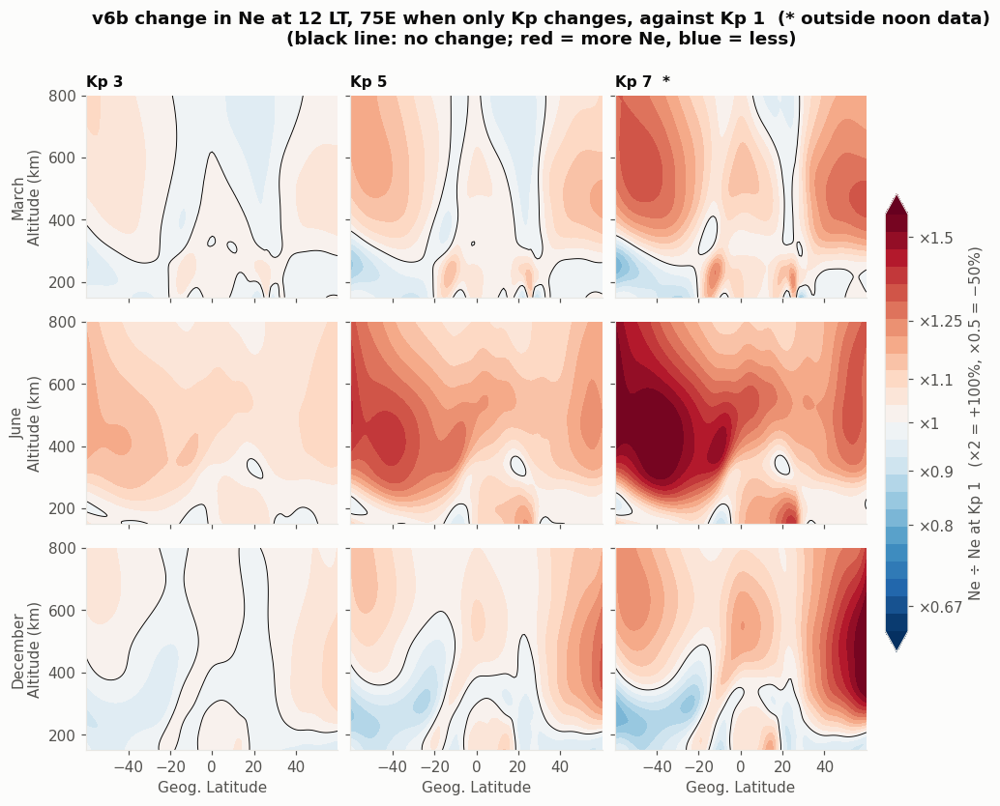

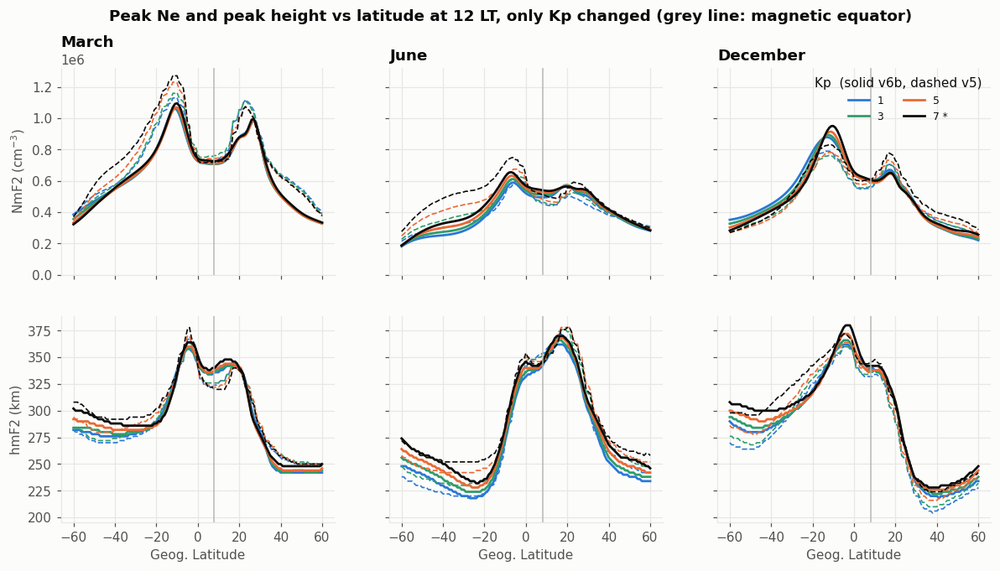

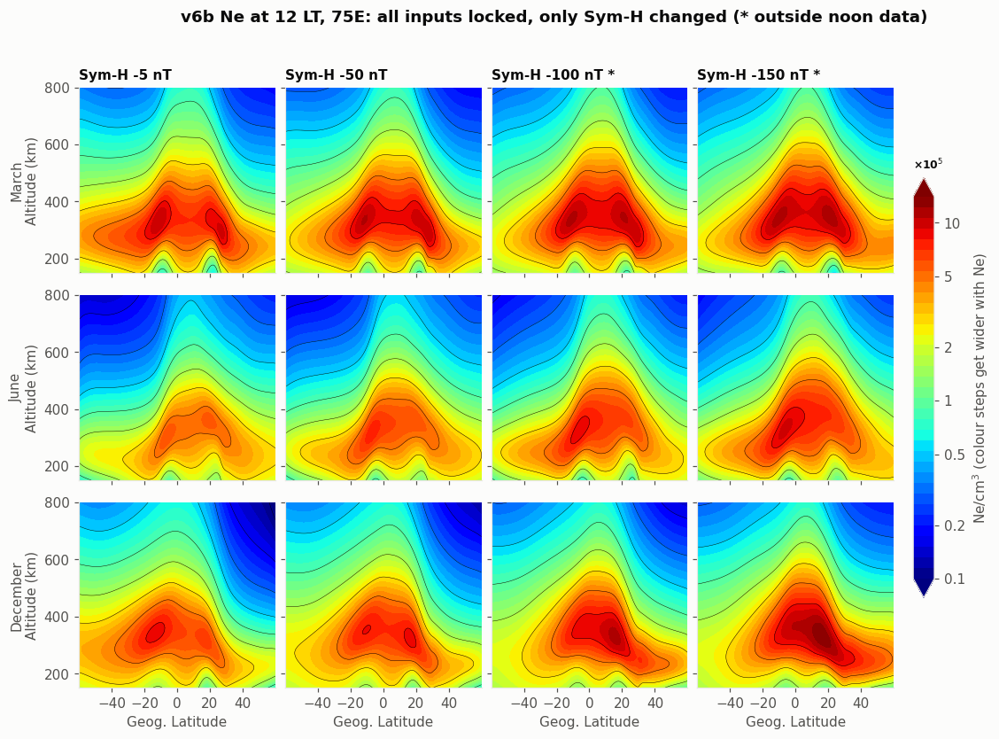

March     Sym-H -50 nT       Ne ÷ base: min ×0.60, median ×0.99, max ×1.41
March     Sym-H -100 nT *    Ne ÷ base: min ×0.51, median ×1.10, max ×1.51
March     Sym-H -150 nT *    Ne ÷ base: min ×0.50, median ×1.18, max ×1.74
June      Sym-H -50 nT       Ne ÷ base: min ×0.87, median ×1.16, max ×1.72
June      Sym-H -100 nT *    Ne ÷ base: min ×0.48, median ×1.32, max ×2.18
June      Sym-H -150 nT *    Ne ÷ base: min ×0.56, median ×1.50, max ×2.79
December  Sym-H -50 nT       Ne ÷ base: min ×0.72, median ×1.05, max ×1.47
December  Sym-H -100 nT *    Ne ÷ base: min ×0.58, median ×1.11, max ×2.00
December  Sym-H -150 nT *    Ne ÷ base: min ×0.57, median ×1.18, max ×3.42


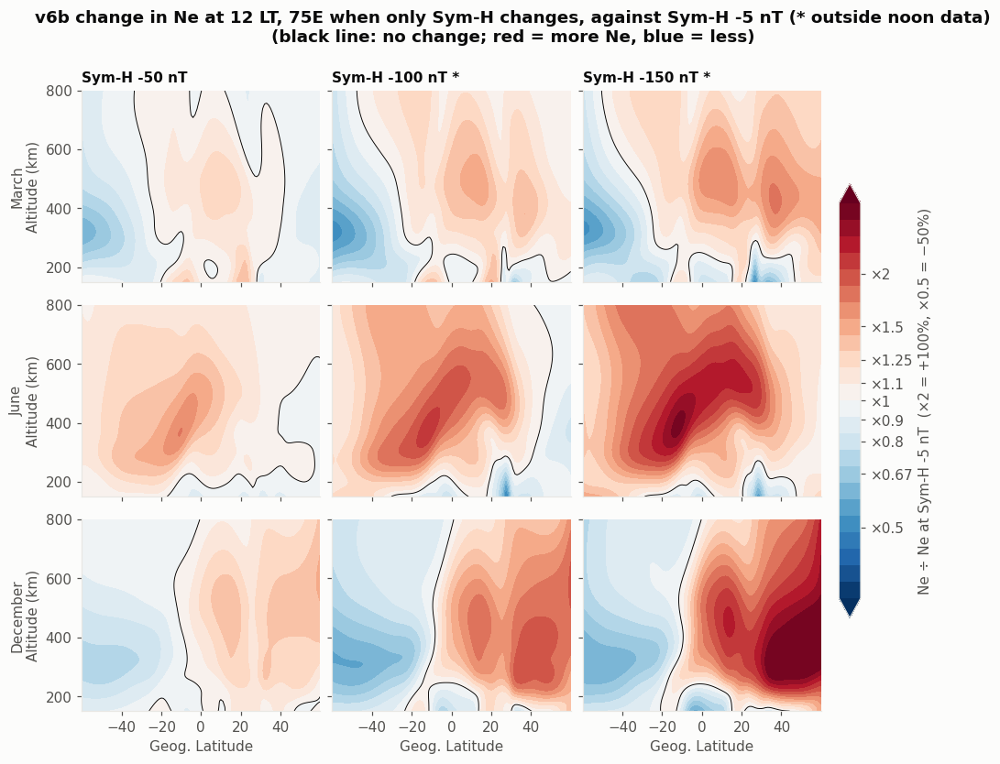

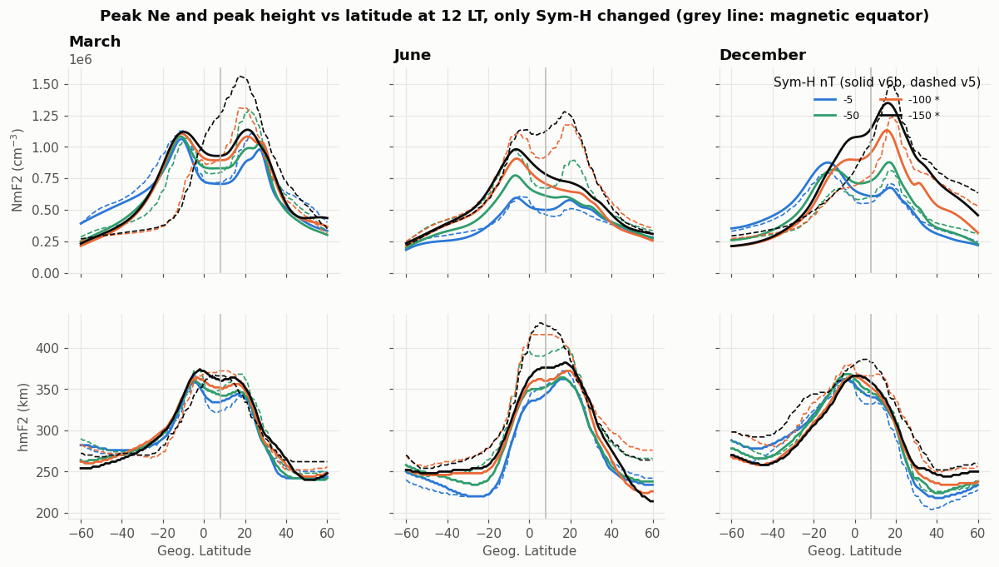

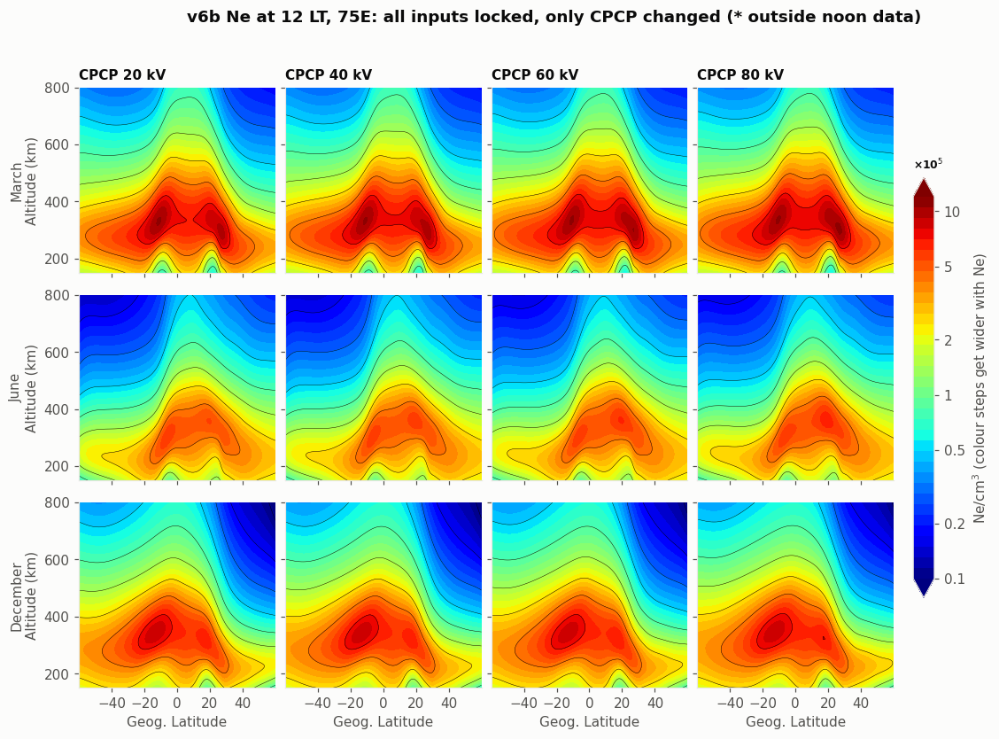

March     CPCP 40 kV         Ne ÷ base: min ×0.96, median ×1.03, max ×1.08
March     CPCP 60 kV         Ne ÷ base: min ×0.92, median ×1.06, max ×1.17
March     CPCP 80 kV         Ne ÷ base: min ×0.90, median ×1.10, max ×1.26
June      CPCP 40 kV         Ne ÷ base: min ×0.95, median ×1.02, max ×1.08
June      CPCP 60 kV         Ne ÷ base: min ×0.90, median ×1.05, max ×1.19
June      CPCP 80 kV         Ne ÷ base: min ×0.84, median ×1.08, max ×1.27
December  CPCP 40 kV         Ne ÷ base: min ×0.97, median ×1.01, max ×1.04
December  CPCP 60 kV         Ne ÷ base: min ×0.94, median ×1.04, max ×1.12
December  CPCP 80 kV         Ne ÷ base: min ×0.93, median ×1.07, max ×1.22


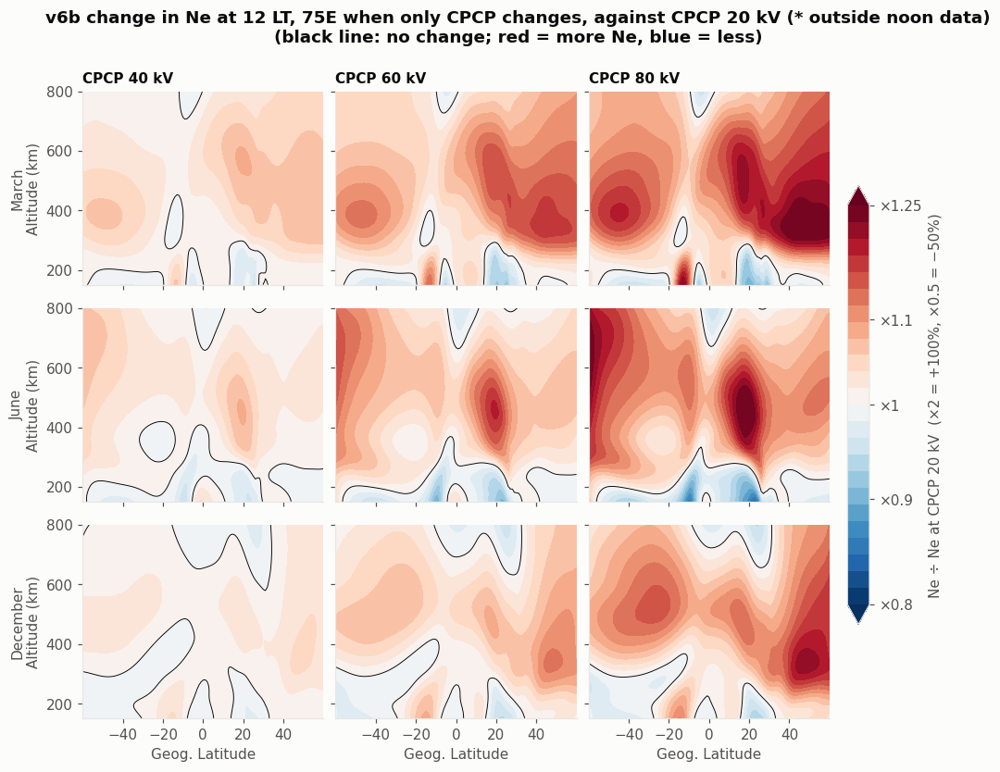

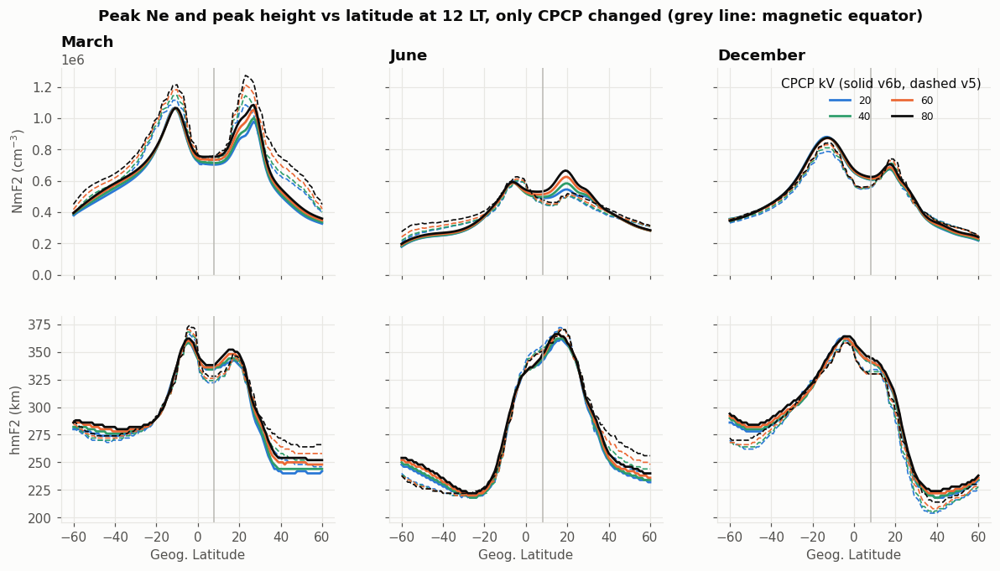

March, 12 LT, 75E:
               peak_Ne_v6b  peak_Ne_v5  equator_Ne_v6b  equator_Ne_v5  equator_hm_v6b  equator_hm_v5  crest_to_equator_v6b  crest_to_equator_v5
driver value                                                                                                                                   
F10.7   70.0      881027.0    962504.0        604288.0       663801.0           324.0          316.0                  1.46                 1.45
        110.0    1696239.0   1784190.0       1172300.0      1146206.0           362.0          348.0                  1.45                 1.56
        150.0    2524816.0   2540706.0       1673366.0      1615980.0           406.0          392.0                  1.51                 1.57
        190.0    3730634.0   2438162.0       2559693.0      1956660.0           460.0          444.0                  1.46                 1.25
Kp      1.0      1063674.0   1132236.0        707862.0       727400.0           336.0          324.0                 


observed check: 11-13 LT, 250-400 km, all longitudes, geometric mean Ne; change % is against the quietest bin (F10.7 rows need Kp < 3, the others need F10.7 60-130)
driver              band          bin   rows  observed_Ne  v6b_over_obs  v5_over_obs  observed_change_pct  v6b_change_pct  v5_change_pct
 F10.7       |dip| <= 20     (60, 90] 429604     562787.0          1.00         1.00                  0.0             0.0            0.0
 F10.7       |dip| <= 20    (90, 120] 145275     935189.0          1.00         1.02                 66.0            66.0           68.0
 F10.7       |dip| <= 20   (120, 150] 144480    1235832.0          0.99         1.02                120.0           118.0          124.0
 F10.7       |dip| <= 20   (150, 200] 157732    1256943.0          1.00         1.00                123.0           123.0          122.0
 F10.7       |dip| <= 20   (200, 300]  29733    1269855.0          1.19         0.98                126.0           168.0          122.0
 F10.7 40 <=

In [46]:
tic('One-driver tests: Fig 8 at 12 LT, one driver changed, all others locked')
if "v5old" not in PRED: PRED["v5old"] = pred_v5
ODT = [("F10.7", "f107", [70.0, 110.0, 150.0, 190.0], "sfu"), ("Kp", "kp", [1.0, 3.0, 5.0, 7.0], ""), ("Sym-H", "symh", [-5.0, -50.0, -100.0, -150.0], "nT"), ("CPCP", "cpcp", [20.0, 40.0, 60.0, 80.0], "kV")]
_n1 = df["lt"].between(11, 13).values; RNG1 = {c: tuple(np.percentile(df.loc[_n1, c].values, [0.5, 99.5])) for _, c, _, _ in ODT}; print("0.5-99.5% range at 11-13 LT:", {k: tuple(round(float(x), 1) for x in v) for k, v in RNG1.items()})
def run1(doy, D0, key, v, model="ANN"):
    D1, f, s = dict(D0), 75.0, D0["symh"]
    if key == "f107": f = v; D1["f81"] = v
    elif key == "symh": s = v
    else: D1[key] = v
    return ne_model(doy, 12.0, LAT12[:, None], 75.0, ALT12[None, :], s, f, drv=D1, model=model)
RES1 = []
for lab, key, vals, unit in ODT:
    out = lambda v: not (RNG1[key][0] <= v <= RNG1[key][1]); Z1 = {}
    for j, (sn, doy) in enumerate(SE12):
        D0 = season_drv(doy, 60, 110)
        for v in vals:
            for m_ in ("ANN", "v5old"): Z1[(sn, v, m_)] = run1(doy, D0, key, v, m_)
    vmax = float(np.ceil(max(Z1[(sn, v, "ANN")].max() for sn, _ in SE12 for v in vals) / 2e5) * 2e5); lv, nm = ne_levels(vmax)
    fig, axs = plt.subplots(3, 4, figsize=(13, 8), sharex=True, sharey=True, gridspec_kw={"hspace": .12, "wspace": .05})
    for j, (sn, doy) in enumerate(SE12):
        for i, v in enumerate(vals):
            Z = Z1[(sn, v, "ANN")]; ax = axs[j, i]; ax.grid(False)
            cs = ax.contourf(LAT12, ALT12, np.clip(Z, NE_LO, vmax).T, levels=lv, norm=nm, cmap="jet", extend="both"); ax.contour(LAT12, ALT12, Z.T, levels=lv[::4], colors="k", linewidths=.3); ax.set_xticks(range(-40, 41, 20)); ax.set_yticks([200, 400, 600, 800])
            if j == 0: ax.set_title(f"{lab} {v:g} {unit}" + (" *" if out(v) else ""), fontsize=10)
            if i == 0: ax.set_ylabel(f"{sn}\nAltitude (km)")
            if j == 2: ax.set_xlabel("Geog. Latitude")
            e = int(np.abs(LAT12 - LAT_EQ).argmin())
            for m_, mn in (("ANN", "v6b"), ("v5old", "v5")):
                Nm, Hm = peaks(Z1[(sn, v, m_)], ALT12); k = int(Nm.argmax()); RES1.append(dict(driver=lab, value=v, outside_data=out(v), season=sn, model=mn, peak_Ne=Nm[k], peak_lat=LAT12[k], peak_hm=Hm[k], equator_Ne=Nm[e], equator_hm=Hm[e], crest_to_equator=Nm[k] / Nm[e]))
    ne_cbar(fig, cs, axs, vmax)
    fig.suptitle(f"v6b Ne at 12 LT, 75E: all inputs locked, only {lab} changed (* outside noon data)", fontweight="bold"); save(fig, f"one_driver_{key}_lat_altitude_12LT.png")
    change_maps({(sn, v): Z1[(sn, v, "ANN")] for sn, _ in SE12 for v in vals}, [sn for sn, _ in SE12], vals[0], vals[1:], lambda v: f"{lab} {v:g} {unit}" + (" *" if out(v) else ""), f"{lab} {vals[0]:g} {unit}", f"v6b change in Ne at 12 LT, 75E when only {lab} changes, against {lab} {vals[0]:g} {unit} (* outside noon data)", f"one_driver_{key}_change_lat_altitude_12LT.png")
    fig, axs = plt.subplots(2, 3, figsize=(13, 6.4), sharex=True, sharey="row")
    for j, (sn, _) in enumerate(SE12):
        for v, c_ in zip(vals, DCOL):
            for m_, ls in (("ANN", "-"), ("v5old", "--")):
                Nm, Hm = peaks(Z1[(sn, v, m_)], ALT12); axs[0, j].plot(LAT12, Nm, color=c_, ls=ls, lw=1.8 if m_ == "ANN" else 1.1, label=f"{v:g}{' *' if out(v) else ''}" if m_ == "ANN" else None); axs[1, j].plot(LAT12, Hm, color=c_, ls=ls, lw=1.8 if m_ == "ANN" else 1.1)
        axs[0, j].set_title(sn); axs[0, j].set_ylim(bottom=0); axs[0, j].axvline(LAT_EQ, color=GRAY, lw=1); axs[1, j].axvline(LAT_EQ, color=GRAY, lw=1); axs[1, j].set_xlabel("Geog. Latitude")
    axs[0, 0].set_ylabel("NmF2 (cm$^{-3}$)"); axs[1, 0].set_ylabel("hmF2 (km)"); axs[0, 2].legend(title=f"{lab} {unit} (solid v6b, dashed v5)", fontsize=8, loc="upper right", ncol=2)
    fig.suptitle(f"Peak Ne and peak height vs latitude at 12 LT, only {lab} changed (grey line: magnetic equator)", fontweight="bold"); save(fig, f"one_driver_{key}_nmf2_hmf2_12LT.png")
RES1 = pd.DataFrame(RES1); RES1.to_csv(os.path.join(OUT, "one_driver_test_12LT.csv"), index=False)
_t = RES1[RES1["season"] == "March"].pivot_table(index=["driver", "value"], columns="model", values=["peak_Ne", "equator_Ne", "equator_hm", "crest_to_equator"], sort=False); _t.columns = [f"{a}_{b}" for a, b in _t.columns]
print("March, 12 LT, 75E:"); print(_t.round({c: 0 for c in _t.columns if "Ne" in c} | {c: 2 for c in _t.columns if "crest" in c}).to_string())
OBB = {"f107": ([60, 90, 120, 150, 200, 300], 0), "kp": ([0, 2, 4, 6, 9.1], 0), "symh": ([-500, -100, -50, -20, 100], 3), "cpcp": ([0, 30, 50, 70, 300], 0)}; _o = []
_g0 = df.loc[_n1 & df["alt"].between(250, 400).values]
for lab, key, _, unit in ODT:
    b_, ref = OBB[key]; g = _g0[(_g0["kp"] < 3) if key == "f107" else _g0["f107"].between(60, 130)]
    for band, mb in (("|dip| <= 20", np.abs(g["diplat"].values) <= 20), ("40 <= |dip| <= 60", np.abs(g["diplat"]).between(40, 60).values)):
        h = g[mb]; h = h.assign(p5=PRED["ANN"](feats(h)), p4=PRED["v5old"](featsw(h)), bb=pd.cut(h[key], b_)); r = []
        for bn, x in h.groupby("bb", observed=False): r.append(dict(driver=lab, band=band, bin=str(bn), rows=len(x), observed_Ne=10 ** x["y"].mean() if len(x) else np.nan, v6b_Ne=10 ** x["p5"].mean() if len(x) else np.nan, v5_Ne=10 ** x["p4"].mean() if len(x) else np.nan))
        r = pd.DataFrame(r)
        for c in ("observed", "v6b", "v5"): r[f"{c}_change_pct"] = 100 * (r[f"{c}_Ne"] / r[f"{c}_Ne"].iloc[ref] - 1)
        _o.append(r)
OB1 = pd.concat(_o, ignore_index=True); OB1["v6b_over_obs"] = OB1["v6b_Ne"] / OB1["observed_Ne"]; OB1["v5_over_obs"] = OB1["v5_Ne"] / OB1["observed_Ne"]; OB1.to_csv(os.path.join(OUT, "one_driver_observed_check.csv"), index=False)
print("\nobserved check: 11-13 LT, 250-400 km, all longitudes, geometric mean Ne; change % is against the quietest bin (F10.7 rows need Kp < 3, the others need F10.7 60-130)")
print(OB1[OB1["rows"] >= 200][["driver", "band", "bin", "rows", "observed_Ne", "v6b_over_obs", "v5_over_obs", "observed_change_pct", "v6b_change_pct", "v5_change_pct"]].round({"observed_Ne": 0, "v6b_over_obs": 2, "v5_over_obs": 2, "observed_change_pct": 0, "v6b_change_pct": 0, "v5_change_pct": 0}).to_string(index=False))
